# Queensland road crashes | V6

This notebook follows the six CRISP-ML(Q) phases, with quality checks alongside the analysis. It combines crash-level exploration, spatial enrichment, year-and-police-region analysis, and an experimental crash severity classifier.

Run from top to bottom with the project’s `.venv` kernel. Keep the six original CSVs beside the notebook and the Queensland reference layers under `Public spatial data/`. The notebook regenerates the enriched data and reconciliation exports. Each code cell has an overview of its methods before it and a summary of the saved results after it. The three CSV exports carry V6 filenames. The release manifest identifies the source files, spatial layers and software used in this run.

Open [the V5 Tableau workbook](Queensland%20Traffic%20V5.twbx) to explore the crash-level data with filters and maps and to review the fixed-period results, or [the interactive Esri maps](Queensland%20Traffic%20V6%20-%20Esri%20Maps.html) for the map layers. This notebook writes its tables to `Tableau data V6/`. `build_tableau_workbook.py` still packages the V5 tables. Its hotspot and model sheets need updating for the V6 table layouts before it can build a V6 workbook.

The kernel uses pandas, NumPy, SciPy, Matplotlib, Folium, scikit-learn, mlxtend, Shapely, PyProj, pyshp, ijson, and PyArrow.

Process references are available in [Studer et al., CRISP-ML(Q)](https://www.mdpi.com/2504-4990/3/2/20) · [Google Cloud, MLOps lifecycle and automation](https://docs.cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning)

### What changed in V6

The changes follow [`Review_Improvements_05.md`](Review_Improvements_05.md).

1. **Outcome drift.** The hospitalisation share of injury crashes rises steadily across the series while the fatal share stays level. A new Phase 2 check derives a stable severity window from the data. Serious-share heatmaps, association rules and models now use that window, long-run trends use the fatal share, and the site screening uses year-specific expected shares.
2. **Crash-level fields.** New sections analyse unit counts (pedestrians, cyclists, single-vehicle crashes), crash month, council areas, police districts and state electorates (funnel plots against road mix), and detailed DCA movement codes. A crash-level logistic regression gives adjusted odds ratios.
3. **Road-site screening.** DBSCAN count hotspots are replaced by junctions and road links from the Queensland road network, ranked by empirical-Bayes excess serious crashes. A two-period test checks that the ranking holds up, and stacked geocoded points are flagged.
4. **Severity models.** The three four-class Random Forests with SMOTENC are replaced by gradient boosting and logistic regression for two binary outcomes. Both are trained, thresholded and tested in time order inside the stable window, with calibration checks.
5. **Location recovery.** V5's inline recovery code moved to `traffic_location_recovery.py`, which reuses the identical helpers in `traffic_spatial_lookup.py` and caches the slow public-layer pass. Its outputs match V5 byte for byte.

### Optional · Run in Google Colab

Skip this cell when running locally. To work in Colab, copy this notebook to Google Drive, keep the data in a Drive folder named `Traffic Data`, and uncomment the lines below before running anything else.

**In this cell.** Mount Google Drive, make `Traffic Data` the working directory so every relative path in the notebook resolves there, and install the packages Colab does not provide. The folder needs the six source CSVs, the `Public spatial data/` subfolder and the three helper modules `traffic_spatial_lookup.py`, `traffic_location_recovery.py` and `traffic_road_sites.py`. Exports are written back to the same Drive folder.

In [1]:
# --- Google Colab setup -------------------------------------------------------------------
# Uncomment every line below (select the lines, then Ctrl+/ or Cmd+/) and run this cell first.
# Leave it commented out when running locally.

# from google.colab import drive
# import os
#
# # Mount Google Drive. Colab asks for permission the first time.
# drive.mount('/content/drive')
#
# # The notebook reads and writes relative to the working directory, so point it at the data folder.
# # Change this path if "Traffic Data" is not at the top level of My Drive.
# COLAB_DATA_DIR = '/content/drive/MyDrive/Traffic Data'
# os.chdir(COLAB_DATA_DIR)
#
# # Fail early with a clear message if the folder is not laid out as the notebook expects.
# for needed in ['Road crash locations.csv', 'Public spatial data/roads.geojson.gz']:
#     assert os.path.exists(needed), f'Missing in {COLAB_DATA_DIR}: {needed}'
#
# # Install the packages the notebook uses. Most are already in Colab; pip skips those.
# %pip install -q folium mlxtend shapely pyproj pyshp ijson pyarrow
#
# # If a cell later fails on a pandas or scikit-learn difference, install the versions this
# # notebook was last run with instead, then restart the runtime (Runtime > Restart session)
# # and run this cell again:
# # %pip install -q pandas==3.1.1 numpy==2.5.5 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1 \
# #     mlxtend==0.25.0 folium==1.0.0 shapely==2.2.0 pyproj==3.8.0 \
# #     pyshp==3.1.9 ijson==3.6.0 pyarrow==26.0.1
#
# # build_tableau_workbook.py still packages the V5 tables; it needs updating for the V6 layouts.
#
# print('Working directory:', os.getcwd())

**What this achieved.** Nothing when left commented out. When uncommented in Colab, the notebook runs from the `Traffic Data` folder in Google Drive with the required packages installed.

## Phase 1 · Business and data understanding

The current analytical goal is to describe the circumstances and outcomes of recorded Queensland crashes and identify patterns worth testing further. The modelling experiment classifies injury severity using recorded crash and road conditions. Its operational user, prediction timing, decision, and acceptance thresholds are open.

The locations file supports crash-level analysis. For comparisons across all six files, the common unit is crash year and police region. Treat 2025 as partial wherever complete years are required.

Two recording changes shape what the data can support. Property-damage-only crashes are recorded to 2010 only, so the analysis uses injury crashes wherever a series or a share crosses that year. The overseas-licensed driver flag stops during the series and is not analysed. A third change affects the outcome itself: the fatal-or-hospitalisation share of injury crashes rises steadily over the series while the fatal share stays level. Serious-share comparisons therefore use a stable recent window, set from the data in Phase 2. Phase 2 documents all three.

### Load and profile the source data

**In this cell.** Load the six source CSVs with pandas, verify that the required local spatial files are present, and check that crash identifiers are unique. List missing values to guide the cleaning steps.

In [2]:
from pathlib import Path
from tempfile import NamedTemporaryFile

import numpy as np
import pandas as pd
from IPython.display import display

# Fixed seed and file locations used throughout the notebook.
SEED = 42
DATA_DIR = Path.cwd()
SOURCE = DATA_DIR / 'Road crash locations.csv'
EXPORT = DATA_DIR / 'Road crash locations - cleaned V6.csv'
CRASH_ID = 'Crash_Ref_Number'
COORDS = ['Crash_Latitude', 'Crash_Longitude']
SPATIAL_DIR = DATA_DIR / 'Public spatial data'
# Cached intermediate results (location recovery, road network). Safe to delete; they are rebuilt.
CACHE_DIR = DATA_DIR / '.cache'

# The five grouped supplement files, keyed by a short name.
supplement_paths = {
    'Factors': DATA_DIR / 'Factors in road crashes.csv',
    'Casualties': DATA_DIR / 'Road casualties.csv',
    'Vehicles': DATA_DIR / 'Vehicle types.csv',
    'Demographics': DATA_DIR / 'Driver demographics.csv',
    'Restraints': DATA_DIR / 'Seatbelt restraints and helmet use.csv',
}
spatial_files = [
    'roads.geojson.gz', 'locality.geojson.gz', 'postal.geojson.gz', 'police.zip',
    'G-NAF Queensland 2026-08.parquet',
]
# Stop early with a clear message if any input file or spatial layer is missing.
required = [SOURCE, *supplement_paths.values(), *(SPATIAL_DIR / name for name in spatial_files)]
missing_inputs = [str(path.relative_to(DATA_DIR)) for path in required if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError('Missing notebook inputs: ' + ', '.join(missing_inputs))

# `raw` is the crash-level source and is never modified. `datasets` holds all six files.
raw = pd.read_csv(SOURCE, low_memory=False)
datasets = {'Locations': raw} | {
    name: pd.read_csv(path, low_memory=False) for name, path in supplement_paths.items()
}
# The crash reference must identify exactly one row.
assert raw[CRASH_ID].notna().all() and raw[CRASH_ID].is_unique
print(f"{len(raw):,} crashes | {raw.shape[1]} fields | {raw['Crash_Year'].min()}–{raw['Crash_Year'].max()}")
display(raw.isna().sum().loc[lambda counts: counts.gt(0)].rename('Missing rows').to_frame())

415,407 crashes | 53 fields | 2001–2025


,Missing rows
Crash_Longitude,598
Crash_Latitude,598
Crash_Street,15
Crash_Street_Intersecting,234997
State_Road_Name,224003
Crash_Speed_Limit,5
Crash_Road_Horiz_Align,1
Crash_Road_Vert_Align,2
DCA_Key_Approach_Dir,8021


**What this achieved.** Loaded the six source tables and checked that the required files and spatial layers are available. The crash-level source contains 415,407 unique crash records from 2001–2025. The output lists the fields with missing values.

### Audit the six files and test merge keys

Test identifier coverage, matching row IDs, and repeated year-region groups. A crash can be identified in the locations file by `Crash_Ref_Number`. Supplemental files report grouped counts and require a common geographic and time unit for analysis.

**In this cell.** Test candidate merge keys by checking identifier coverage, duplicate year–region groups, and whether matching row IDs refer to the same crash year. Align the police-region column names for later aggregation.

In [3]:
# Map each locations row ID to its crash year, to test whether `_id` means the same thing in every file.
location_ids = raw.set_index('_id')['Crash_Year']
# Each file names its police-region column differently.
region_fields = {
    'Locations': 'Loc_Police_Region',
    'Factors': 'Crash_Police_Region',
    'Casualties': 'Crash_Police_Region',
    'Vehicles': 'Crash_Police_Region',
    'Demographics': 'Crash_Police_Region',
    'Restraints': 'Crash_PoliceRegion',
}
group_fields = ['Crash_Year', 'Police_Region']
# The same tables with one shared `Police_Region` column, used for all year-region work below.
regional_sources = {
    name: frame.rename(columns={region_fields[name]: 'Police_Region'})
    for name, frame in datasets.items()
}

# Only columns present in all six files could serve as a common key.
columns_in_every_file = sorted(set.intersection(*(set(frame.columns) for frame in datasets.values())))
print('Exact column names shared by all six files:', ', '.join(columns_in_every_file))
# For each file, record ID coverage, uniqueness, year agreement and repeated year-region groups.
key_audit_rows = []
for name, frame in regional_sources.items():
    file_ids = frame['_id'].dropna()
    matching = frame.loc[file_ids.index[file_ids.isin(location_ids.index)], ['_id', 'Crash_Year']]
    mismatches = matching['Crash_Year'].ne(matching['_id'].map(location_ids))
    key_audit_rows.append({
        'File': name,
        'Rows': len(frame),
        'Has Crash ID': 'Crash ID' in frame,
        'Has crash reference': CRASH_ID in frame,
        'Unique _id': frame['_id'].is_unique,
        '_id overlaps with locations': len(matching),
        'Overlapping _id with different year': int(mismatches.sum()),
        'Year-region groups': frame[group_fields].drop_duplicates().shape[0],
        'Repeated year-region rows': int(frame.duplicated(group_fields).sum()),
    })
display(pd.DataFrame(key_audit_rows).set_index('File'))

Exact column names shared by all six files: Crash_Year, _id


,Rows,Has Crash ID,Has crash reference,Unique _id,_id overlaps with locations,Overlapping _id with different year,Year-region groups,Repeated year-region rows
File,,,,,,,,
Locations,415407,False,True,True,415407,0,186,415221
Factors,5523,False,False,True,5523,5234,186,5337
Casualties,38893,False,False,True,38893,37463,184,38709
Vehicles,3764,False,False,True,3764,3573,186,3578
Demographics,22699,False,False,True,22699,22572,186,22513
Restraints,42787,False,False,True,42787,41399,184,42603


**What this achieved.** Tested record identifiers and year–region coverage. `Crash_Ref_Number` identifies a locations record. Shared row IDs disagree on crash year across files. Year and police region support comparisons after source-level aggregation.

## Phase 2 · Data preparation and quality assurance

Prepare the crash-level data, document uncertainty, and reconcile both individual and grouped counts. The exploration that follows checks what the prepared data can support before modelling.

### Estimate missing coordinate pairs

Use median observed coordinates from the most specific group with at least three donor crashes. For records with usable locality labels, try an intersection within a suburb, then a street, suburb, or local government area (LGA). All 598 records missing coordinates have both suburb and LGA coded as `Unknown` in this CSV.

For records without locality labels, try an exact intersection, a street and named state-road segment, or a street name across Queensland. A compact match requires all geocoded donors to agree on a single known suburb and LGA, with a bounding-box diagonal of at most 1 km. As a last resort, a coarse street estimate allows a diagonal of up to 3 km where all donors agree on the LGA. An inferred suburb is recorded only when all donors agree on the suburb. Intersections are matched irrespective of road order. Unknown and generic street names are excluded. Estimates retain the donor method, count, and inferred locality, and unresolved coordinates remain blank.

Compare V2-style suburb/LGA medians with the V3 hierarchy on 10,000 withheld observed locations. Also mask suburb and LGA on those same rows to test the street fallback in conditions closer to the actual missing records. Errors are measured only where each method produced an estimate. Actual errors for the missing records remain unknown.

### Infer other fields where local records agree

For speed limit, require at least two agreeing reports on the same street and in the same suburb and LGA, within 25 m and two crash years. For road alignment, require at least three agreeing reports at the exact same recorded coordinates on the same street and in the same locality. These are conservative rules for suggesting missing values. Estimates rely on agreement within this dataset.

Leave the other blanks in place. Intersecting street and state-road name can be inapplicable, and approach direction depends on the individual crash.

### Add public spatial matches and reconcile the remaining gaps

The first pass runs locally and uses Queensland Roads and Tracks to check recorded points with a blank or generic street name. It requires a named road within 35 m and a lead of at least 10 m over the next differently named road. For crashes still missing coordinates, an exact road name or alias could yield an estimate at one shared junction or the midpoint of a single connected named street up to 1.5 km long.

The second pass expands standard street abbreviations and normalizes punctuation. A junction estimate requires two different recorded street names, the recorded cross-intersection type, a single mapped ground-level junction with four approaches, and at least one corroborating crash with the same two streets within 75 m. A street estimate requires a compact road corridor with every mapped road vertex within 500 m of the estimate, at least three distinct G-NAF address sites associated with the road, and at least three observed crash locations associated with the named street. All known crash points for that street must agree with the candidate corridor. The audit records the candidate extent and the evidence used. Plausible candidates without enough historical support are listed as review coordinates and excluded from the crash maps and models.

The validation sample combines 5,000 located crashes whose primary street names overlap with the unresolved cases and additional records on rare matching streets. For cases where the first road pass found no estimate, the check compares second-pass estimates with the recorded points. Each evaluated crash is excluded from its own historical road evidence. The errors describe performance on this sample.

Queensland locality polygons provide suburb and council area. ABS 2021 Postal Areas provide an approximate area code. QPS polygons provide the police-region label from the October 2026 archive. The latter two remain in separate columns so analysts can choose whether to combine them with recorded crash-era fields. Values derived from estimated points inherit their location uncertainty. Recorded street, suburb, council, postcode, and police-region values remain the preferred source.

The public layers are [Queensland Roads and Tracks](https://queensland.opendatasoft.com/explore/assets/roads-and-tracks/), [Queensland locality boundaries](https://www.data.qld.gov.au/dataset/locality-boundaries-queensland), [ABS Postal Areas](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files), and [QPS regions](https://www.data.qld.gov.au/dataset/qps-regions).

Council-name comparisons account for the Region/Regional suffix and the 2023 Moreton Bay reclassification. Both source labels are retained. [City of Moreton Bay](https://www.moretonbay.qld.gov.au/files/assets/public/v/3/services/annual-report/annual-report-2022-23/mbrc-annual-report-2022-23.pdf)

The August 2026 Queensland G-NAF extract adds nearby numbered-address references within 50 m of recorded crash points. Address matches use property or building geocodes and exclude low-confidence and secondary addresses. Locality and street must agree where known. Where the street remains unresolved, three distinct nearby address sites must agree on one street for G-NAF to report a candidate. Property references and their postcodes are stored separately from crash street names and recorded postcodes. [Geoscape G-NAF product description](https://docs.geoscape.com.au/projects/gnaf_desc/en/stable/appendix_d.html) · [GeoParquet source](https://github.com/minus34/gnaf-loader#option-4---geoparquet-files-in-s3)

The compressed Queensland layers and source manifest are in `Public spatial data/`. `traffic_location_recovery.py` recomputes the matches directly from the layers and the crash data.

#### Recover suburbs without assigning coordinates

For crashes still missing both coordinates and a suburb, look for an exact named road or street pair in the Queensland network. The road must map to one locality statewide, or all intersections of the two named roads must fall in the same locality. Require agreement from at least two recorded crashes or at least three G-NAF points. A conflicting recorded suburb blocks the estimate. The result appears in `Reconciled_Suburb`, with evidence in the `Suburb_Only_*` columns. Maps, coordinate estimates, and regional grouping still use their existing inputs.

#### Run the location recovery

The recovery code that V5 ran inline across sixteen cells now lives in [`traffic_location_recovery.py`](traffic_location_recovery.py). The public-layer helpers it uses come from [`traffic_spatial_lookup.py`](traffic_spatial_lookup.py), which already held identical copies, so each function now exists once. The method and thresholds are unchanged. The V6 run reproduces the V5 cleaned crash table and the reconciliation table byte for byte.

The statewide public-layer pass is the slow step. Its result is cached in `.cache/`, keyed by a digest of the crash data, the five spatial layers and the source of both modules. A change to any of them triggers a fresh run. Delete `.cache/` to force one.

**In this cell.** Run `recover_locations()`. It estimates coordinates from donor medians after testing the rules on 10,000 withheld locations, infers road attributes where neighbouring crashes agree, runs or reloads the public-layer passes, and applies the matches. Then display the validation and reconciliation tables it returns.

In [4]:
from traffic_location_recovery import (CROSS_STREET, LGA, STATE_ROAD, STREET, SUBURB, YEAR, council_name,
                                       distance_km, missing, normalized_label, recover_locations)
from traffic_spatial_lookup import FORWARD, INVERSE, shapefile_polygons
from shapely import union_all
from shapely.geometry import shape

# Everything V5 cells 16–41 produced, in one call. The public-layer pass is reused from the cache when its inputs are unchanged.
recovery = recover_locations(raw, SPATIAL_DIR, seed=SEED, cache_dir=CACHE_DIR)
print('Public-layer pass:', 'reused from cache' if recovery.cache_hit else 'recomputed and cached',
      f'({recovery.cache_file.relative_to(DATA_DIR)})')
cleaned, gap_audit, targets = recovery.cleaned, recovery.gap_audit, recovery.targets
recorded, available, second_pass = recovery.recorded, recovery.available, recovery.second_pass
missing_audit = recovery.missing_audit
for title, table in recovery.tables.items():
    print(f'\n{title}')
    display(table.round(3))
print('', *recovery.messages, sep='\n')

Public-layer pass: reused from cache (.cache/location_recovery_2ba41aa198d5fcf0c511.pkl)

Donor-rule validation on withheld locations


,Test locations,Estimated,Median error (km),90th percentile error (km)
Method,,,,
V2-style suburb/LGA,10000,10000,0.866,2.909
V3 named-locality hierarchy,10000,10000,0.234,2.100
"V3 street fallback, locality withheld",10000,3690,0.011,0.476



Street-fallback errors by rule


,Estimated,Median,P90
Method,,,
coarse statewide street,832,0.333,1.109
compact statewide intersection,2395,0.006,0.022
compact statewide street,330,0.175,0.536
compact street and state-road segment,133,0.069,0.401



Coordinate method after donor medians


,Crashes
Coordinate_Method,
observed,414809
unresolved,515
coarse statewide street,60
compact statewide street,21
compact statewide intersection,2


... (13 outputs left out)

,Holdout estimates,Median error (m),90th percentile error (m)
Second-pass method,,,
mapped four-arm cross intersection,7,9.3,25.3
G-NAF corroborated road corridor,2,41.7,45.2



Crashes still missing coordinates


,Crashes still missing coordinates
Second_pass_status,
street spans over 3 km or has disconnected corridors,243
no usable primary street name,109
normalized street absent from road network,91
insufficient or conflicting G-NAF support for one corridor,13
recorded junction type does not establish a cross intersection,8
insufficient observed crashes on the candidate road or junction,3
candidate corridor is too long for automatic estimation,2
no shared ground-level node for the recorded junction,1
recorded street pair repeats the same name,1



Suburb-only holdout: 294 matches among 295 estimates from 4,446 eligible records.
Matched against 564,950 local Queensland road segments.
Second-pass holdout: 4,455 of 5,441 sampled crashes were unresolved by the first road-network pass.
Suburb: 0 disagreements after name normalization among 59 donor/boundary comparisons.
Council Area: 0 disagreements after name normalization among 83 donor/boundary comparisons.


**What this achieved.** Ran the unchanged V5 recovery from the module. Donor medians estimated 83 coordinate pairs, local agreement inferred one speed limit and one vertical alignment, and the public layers added 44 more coordinate pairs (127 in total) and 28 suburb-only estimates. 471 crashes still lack coordinates, 443 of them also lack a suburb. The cleaned table keeps the method and evidence for every estimate.

### Validate and export the enriched crash data

Check that the crash IDs and recorded values are preserved. The cleaned export includes method, public source, and donor evidence columns. A separate reconciliation CSV lists the records that were eligible for public lookup, the outcome and the gaps that remain.

**In this cell.** Compare the cleaned data with the source to verify that crash IDs, row order, and recorded values are preserved. Write the cleaned crash and reconciliation CSVs through temporary files so each export can be replaced after it is fully written.

In [5]:
assert cleaned.index.equals(raw.index) and cleaned[CRASH_ID].equals(raw[CRASH_ID])
assert cleaned.columns.is_unique
# Every value recorded in the source must be unchanged in the cleaned table.
for column in raw.columns:
    recorded_values = raw[column].notna()
    assert cleaned.loc[recorded_values, column].equals(raw.loc[recorded_values, column]), column

# Write to a temporary file first, then replace the destination, so a failed run never leaves a partial export.
def write_csv(frame, destination):
    with NamedTemporaryFile(mode='w', encoding='utf-8', newline='', dir=destination.parent,
                            prefix='.traffic-v6-', suffix='.csv', delete=False) as temporary:
        temporary_path = Path(temporary.name)
        try:
            frame.to_csv(temporary, index=False)
        except BaseException:
            temporary_path.unlink(missing_ok=True)
            raise
    temporary_path.replace(destination)


write_csv(cleaned, EXPORT)
write_csv(gap_audit, DATA_DIR / 'Traffic location and suburb reconciliation V6.csv')
print(f"Exported {len(cleaned):,} rows and {cleaned.shape[1]} columns to {EXPORT.name}.")
print(f"Exported {len(gap_audit):,} lookup records to Traffic location and suburb reconciliation V6.csv.")

Exported 415,407 rows and 100 columns to Road crash locations - cleaned V6.csv.
Exported 877 lookup records to Traffic location and suburb reconciliation V6.csv.


**What this achieved.** Checked that every crash ID and recorded source value was preserved, then exported the enriched crash CSV and a record-level suburb and location reconciliation CSV.

### Check that source counts tally

Compare crash counts and casualty counts separately. The locations file contributes one per crash and its recorded casualty total. The other files contribute their published count columns. Check statewide totals and report year-by-police-region differences or absent groups. Finally, compare the restraints file with the road casualties file for the road-user categories it covers.

**In this cell.** Compare weighted crash and casualty totals statewide and by year and police region. Align the road-user categories in the casualty and restraint files to check whether scope differences explain their totals.

In [6]:
# Compare each source's counts with the locations file, statewide and by year-region group.
def tally_counts(sources, baseline='Locations'):
    groups = pd.concat(sources, axis=1).sort_index().astype('Int64')
    observed = groups[baseline].notna()
    rows = []
    for name, values in groups.items():
        compared = observed & values.notna()
        difference = (values - groups[baseline]).loc[compared]
        rows.append({
            'Source': name,
            'Statewide total': int(values.sum()),
            'Statewide difference from locations': int(values.sum() - groups[baseline].sum()),
            'Year-region groups compared': int(compared.sum()),
            'Groups with different counts': int(difference.ne(0).sum()),
            'Location groups absent from this file': int((observed & values.isna()).sum()),
        })
    return groups, pd.DataFrame(rows).set_index('Source')


# Sum a published count column to one value per year and police region.
def count_by_year_region(name, column):
    return regional_sources[name].groupby(group_fields, dropna=False)[column].sum(min_count=1)


crash_counts_by_group, crash_count_tally = tally_counts({
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
    **{name: count_by_year_region(name, 'Count_Crashes')
       for name in ['Factors', 'Vehicles', 'Demographics']},
})
casualty_counts_by_group, casualty_count_tally = tally_counts({
    name: count_by_year_region(name, column)
    for name, column in {
        'Locations': 'Count_Casualty_Total',
        'Factors': 'Count_All_Casualties',
        'Vehicles': 'Count_Casualty_All',
        'Demographics': 'Count_Casualty_All',
        'Casualties': 'Casualty_Count',
        'Restraints': 'Casualty_Count',
    }.items()
})
display(crash_count_tally.rename_axis('Crash counts'))
display(casualty_count_tally.rename_axis('Casualty counts'))

# The restraint file covers fewer road-user types. Compare the two casualty files on the types they share.
road_user = 'Casualty_Road_User_Type'
road_casualties = regional_sources['Casualties'].rename(columns={'Casualty_RoadUserType': road_user})
road_casualties = road_casualties.assign(**{
    road_user: road_casualties[road_user].replace({'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'})
})
restraints_source = regional_sources['Restraints']
covered_users = restraints_source[road_user].dropna().unique()
scope_labels = [*group_fields, road_user, 'Casualty_Severity']
restraint_scope = pd.concat({
    'Road casualties': road_casualties.loc[road_casualties[road_user].isin(covered_users)]
        .groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
    'Restraints and helmets': restraints_source.groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
}, axis=1).astype('Int64')
outside_scope = road_casualties.loc[~road_casualties[road_user].isin(covered_users)].groupby(
    road_user)['Casualty_Count'].sum()
display(outside_scope.rename('Casualties outside restraint source scope').to_frame())
print(f"Casualties in covered road-user groups: {restraint_scope['Road casualties'].sum():,} "
      f"in Road casualties and {restraint_scope['Restraints and helmets'].sum():,} in Restraints and helmets.")
scope_discrepancies = restraint_scope.loc[
    restraint_scope['Road casualties'].fillna(0).ne(restraint_scope['Restraints and helmets'].fillna(0))
]
print(f"Different nonzero counts after aligning road user, casualty severity, year and police region: "
      f"{len(scope_discrepancies):,}.")
if not scope_discrepancies.empty:
    display(scope_discrepancies.head(10))

,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Crash counts,,,,,
Locations,415407,0,186,0,0
Factors,415407,0,186,0,0
Vehicles,415407,0,186,0,0
Demographics,415407,0,186,0,0


,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Casualty counts,,,,,
Locations,437355,0,186,0,0
Factors,437355,0,186,0,0
Vehicles,437355,0,186,0,0
Demographics,437355,0,186,0,0
Casualties,437355,0,184,0,2
Restraints,417148,-20207,184,181,2


,Casualties outside restraint source scope
Casualty_Road_User_Type,
Other,1572
Pedestrian,18635


Casualties in covered road-user groups: 417,148 in Road casualties and 417,148 in Restraints and helmets.
Different nonzero counts after aligning road user, casualty severity, year and police region: 0.


#### What the tally shows

- **Crash counts agree.** The locations, crash factors, vehicle types, and driver demographics files each report **415,407 crashes**. Their counts match in all **186 year-and-police-region groups**.
- **Casualty counts also agree statewide.** Those four files and the road casualties file each report **437,355 casualties**. The road casualties file matches the locations file in all **184 year-and-police-region groups** that both report.
- **The restraint and helmet file covers a narrower set of road users.** It reports **417,148 casualties**, a difference of **20,207**. The road casualties file accounts for that difference with **18,635 pedestrians** and **1,572 other road users** outside the restraint file’s scope. For road users covered by both files, counts match by year, police region, road-user type, and injury severity.

### Check for recording changes over time

A change in what is recorded can look like a change in road safety. Check three series before reading any long-run trend, then check the severity mix itself (next section): the share of property-damage-only crashes, the overseas-licensed driver flag, and minor-injury casualties. Where a series stops or steps, later comparisons either start after the break or use a measure the break leaves untouched.

**In this cell.** Count injury and property-damage-only crashes by year, tabulate the overseas-licensed driver flag by year and severity, and plot minor-injury casualties for complete years. Record the last year with property-damage-only crashes so later cells can refer to it.

,Injury crashes,Property damage only,Property damage only (%),Overseas-licensed flag: Fatal crashes,Overseas-licensed flag: Other crashes,Minor-injury casualties
Crash_Year,,,,,,
2001,13867,8156,37.0,10,556,4835.0
2002,13821,8495,38.1,6,503,4786.0
2003,13652,8741,39.0,5,543,4671.0
2004,13960,9481,40.4,5,589,4589.0
2005,13928,9149,39.6,6,610,4383.0
2006,14048,8406,37.4,6,362,4907.0
2007,14710,8137,35.6,5,203,6089.0
2008,14770,8755,37.2,4,308,5150.0
2009,14017,8925,38.9,6,302,4074.0


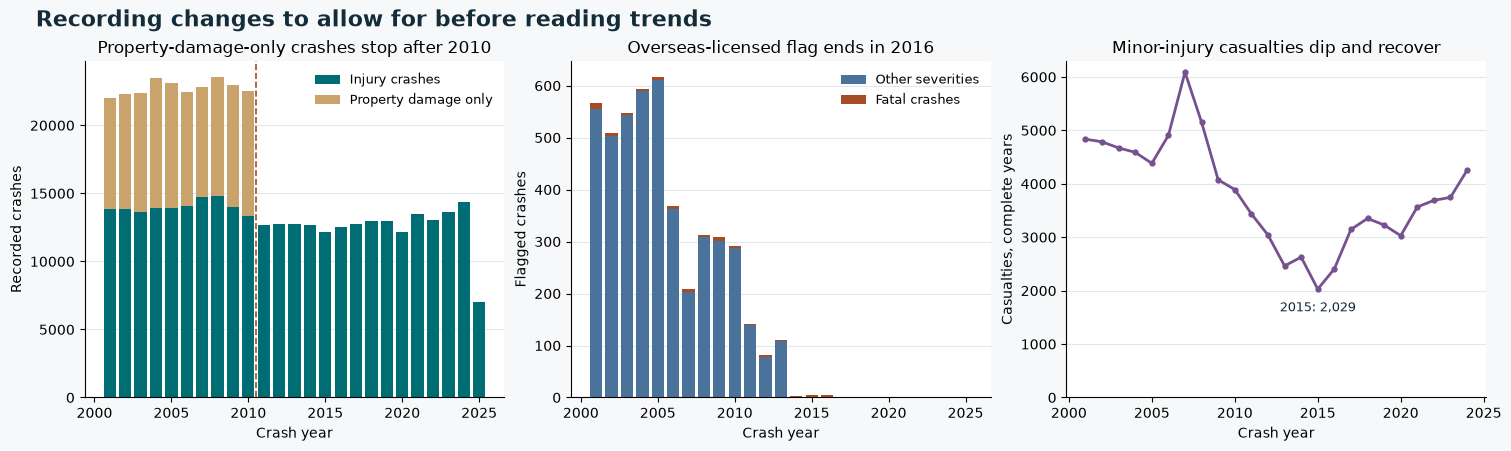

Property-damage-only crashes: 35.6–40.8% of records each year to 2010, then none.
Overseas-licensed flag: all severities to 2013, fatal crashes only to 2016, then no flagged crashes.
Minor-injury casualties: 6,089 in 2007, 2,029 in 2015, 4,253 in 2024.


In [7]:
import matplotlib.pyplot as plt

# These series describe what was recorded each year. A break here is a recording change.
record_mix = pd.crosstab(raw['Crash_Year'], raw['Crash_Severity'].eq('Property damage only'))
record_mix.columns = ['Injury crashes', 'Property damage only']
record_mix['Property damage only (%)'] = 100 * record_mix['Property damage only'] / record_mix.sum(axis=1)
last_pdo_year = int(record_mix.index[record_mix['Property damage only'].gt(0)].max())
assert record_mix.loc[record_mix.index > last_pdo_year, 'Property damage only'].eq(0).all()

# Flagged crashes by year, split into fatal and other severities.
overseas_flag = regional_sources['Demographics'].loc[
    lambda frame: frame['Involving_Overseas_Licensed_Driver'].eq('Yes')
].assign(Outcome=lambda frame: np.where(frame['Crash_Severity'].eq('Fatal'), 'Fatal crashes', 'Other crashes'))
overseas_by_year = (overseas_flag.pivot_table(index='Crash_Year', columns='Outcome', values='Count_Crashes',
                                              aggfunc='sum', fill_value=0)
                    .reindex(index=record_mix.index, columns=['Fatal crashes', 'Other crashes'], fill_value=0))
overseas_last_all_severities = int(overseas_by_year.index[overseas_by_year['Other crashes'].gt(0)].max())
overseas_last_year = int(overseas_by_year.index[overseas_by_year.sum(axis=1).gt(0)].max())

# Minor-injury casualties for years with all 12 months present.
full_years = raw.groupby('Crash_Year')['Crash_Month'].nunique().loc[lambda months: months.eq(12)].index
minor_by_year = (regional_sources['Casualties'].loc[lambda frame: frame['Casualty_Severity'].eq('Minor injury')]
                 .groupby('Crash_Year')['Casualty_Count'].sum().reindex(full_years))
minor_low_year = int(minor_by_year.idxmin())
minor_peak_before = minor_by_year.loc[:minor_low_year]

recording_audit = record_mix.join(overseas_by_year.add_prefix('Overseas-licensed flag: ')).join(
    minor_by_year.rename('Minor-injury casualties'))
display(recording_audit.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('Recording changes to allow for before reading trends', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
audit_years = record_mix.index
axes[0].bar(audit_years, record_mix['Injury crashes'], color='#006d75', label='Injury crashes')
axes[0].bar(audit_years, record_mix['Property damage only'], bottom=record_mix['Injury crashes'],
            color='#c9a36b', label='Property damage only')
axes[0].axvline(last_pdo_year + .5, color='#a64d25', linestyle='--', linewidth=1.2)
axes[0].set(title=f'Property-damage-only crashes stop after {last_pdo_year}', ylabel='Recorded crashes')
axes[0].legend(frameon=False, fontsize=9)
axes[1].bar(audit_years, overseas_by_year['Other crashes'], color='#4a729b', label='Other severities')
axes[1].bar(audit_years, overseas_by_year['Fatal crashes'], bottom=overseas_by_year['Other crashes'],
            color='#a64d25', label='Fatal crashes')
axes[1].set(title=f'Overseas-licensed flag ends in {overseas_last_year}', ylabel='Flagged crashes')
axes[1].legend(frameon=False, fontsize=9)
axes[2].plot(minor_by_year.index, minor_by_year.to_numpy(), color='#76518f', linewidth=2, marker='o', markersize=3.5)
axes[2].annotate(f'{minor_low_year}: {int(minor_by_year.loc[minor_low_year]):,}',
                 (minor_low_year, minor_by_year.loc[minor_low_year]), xytext=(0, -16),
                 textcoords='offset points', ha='center', fontsize=9, color='#142b3a')
axes[2].set(title='Minor-injury casualties dip and recover', ylabel='Casualties, complete years', ylim=(0, None))
for ax in axes:
    ax.set_xlabel('Crash year')
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

print(f"Property-damage-only crashes: {record_mix.loc[:last_pdo_year, 'Property damage only (%)'].min():.1f}–"
      f"{record_mix.loc[:last_pdo_year, 'Property damage only (%)'].max():.1f}% of records each year to {last_pdo_year}, "
      f"then none.")
print(f"Overseas-licensed flag: all severities to {overseas_last_all_severities}, fatal crashes only to "
      f"{overseas_last_year}, then no flagged crashes.")
print(f"Minor-injury casualties: {int(minor_peak_before.max()):,} in {int(minor_peak_before.idxmax())}, "
      f"{int(minor_by_year.loc[minor_low_year]):,} in {minor_low_year}, "
      f"{int(minor_by_year.iloc[-1]):,} in {int(minor_by_year.index[-1])}.")

**What this achieved.** Found three recording changes. Property-damage-only crashes made up 35.6–40.8% of records each year to 2010 and none from 2011, so any count or share that mixes all severities changes level at that point for recording reasons. The overseas-licensed driver flag covers all severities to 2013, fatal crashes only from 2014 to 2016, and no crashes afterwards, so it is left out of the flag comparisons. Minor-injury casualties fell from 6,089 in 2007 to 2,029 in 2015 and rose to 4,253 in 2024. The source files do not explain that movement, so treat minor-injury trends with caution. `last_pdo_year` records the first break for later cells.

### Check whether the severity mix drifts

The three checks above look at what is recorded. This one looks at how injury crashes are graded. Every serious-share comparison in this notebook divides fatal-or-hospitalisation crashes by injury crashes. If the hospitalisation share rises for reasons unrelated to road safety, such as triage or admission practice or how the "hospitalised" threshold is applied, a serious-share trend, a model trained on early years or a rule pooled across the series all inherit that change.

The stable window is set from the data. Starting from the latest complete year and moving back, keep each year whose hospitalisation share and fatal-or-hospitalisation share are both within 3 percentage points of the latest complete year. Stop at the first year that fails. Later sections use this window for serious shares, the rules and the models. The fatal share stays level over the series, so long-run trends use it.

**In this cell.** Tabulate the severity mix of injury crashes by year. Derive the stable window from the 3-point rule. Plot the four severity shares with the window shaded, and the fatal share with a Wilson 95% interval for each year.

Crash_Severity,Fatal,Hospitalisation,Medical treatment,Minor injury,Fatal or hospitalisation,Injury crashes
Crash_Year,,,,,,
2001,2.1,30.5,42.7,24.6,32.6,13867
2002,2.0,32.4,41.5,24.1,34.4,13821
2003,2.1,33.6,40.2,24.1,35.7,13652
2004,2.1,35.7,39.1,23.1,37.8,13960
2005,2.1,36.9,39.0,22.0,39.0,13928
2006,2.2,34.5,39.3,23.9,36.8,14048
2007,2.3,34.2,37.6,25.9,36.5,14710
2008,2.0,37.4,39.5,21.1,39.4,14770
2009,2.1,39.0,41.2,17.7,41.1,14017


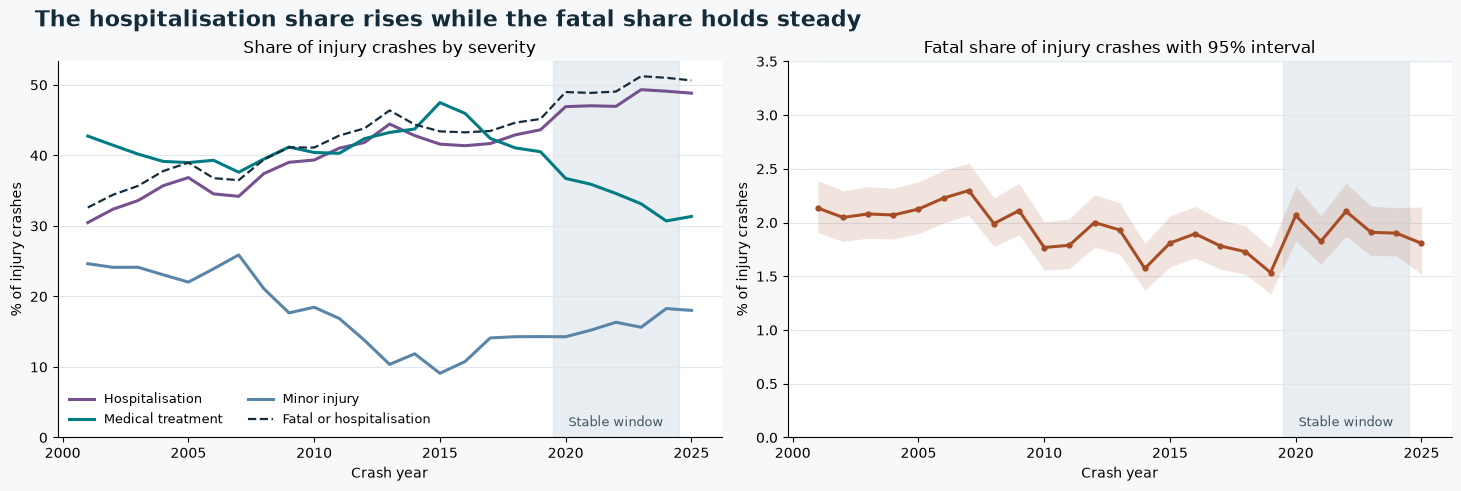

Hospitalisation share: 30.5% in 2001 → 49.1% in 2024. Fatal or hospitalisation: 32.6% → 51.0%.
Fatal share across complete years: 1.5–2.3%.
Stable severity window (within 3 points of 2024): 2020–2024, 66,624 injury crashes.


In [8]:
def wilson_interval(successes, totals, z=1.959964):
    """Wilson score interval for a binomial share, returned as fractions."""
    successes, totals = np.asarray(successes, dtype=float), np.asarray(totals, dtype=float)
    share = successes / totals
    centre = (share + z**2 / (2 * totals)) / (1 + z**2 / totals)
    half = z * np.sqrt(share * (1 - share) / totals + z**2 / (4 * totals**2)) / (1 + z**2 / totals)
    return centre - half, centre + half


# Severity mix of injury crashes by year, as percentages of that year's injury crashes.
mix_levels = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
injury_by_year = raw.loc[raw['Crash_Severity'].isin(mix_levels)]
severity_mix = (pd.crosstab(injury_by_year['Crash_Year'], injury_by_year['Crash_Severity'], normalize='index')
                .reindex(columns=mix_levels).mul(100))
severity_mix['Fatal or hospitalisation'] = severity_mix[['Fatal', 'Hospitalisation']].sum(axis=1)
severity_mix['Injury crashes'] = injury_by_year.groupby('Crash_Year').size()
mix_complete = severity_mix.loc[severity_mix.index.isin(full_years)]

# Stable window: complete years, back from the latest, whose hospitalisation and serious shares
# both stay within the tolerance of the latest complete year.
SEVERITY_TOLERANCE_PP = 3.0
drift_measures = ['Hospitalisation', 'Fatal or hospitalisation']
within = mix_complete[drift_measures].sub(mix_complete[drift_measures].iloc[-1]).abs().le(SEVERITY_TOLERANCE_PP).all(axis=1)
window_run = []
for year, ok in within.iloc[::-1].items():
    if not ok:
        break
    window_run.append(int(year))
stable_years = pd.Index(sorted(window_run), name='Crash_Year')
assert len(stable_years) >= 4, 'The stable window must hold at least four complete years for the model split.'
display(severity_mix.round(1))

fatal_counts = injury_by_year['Crash_Severity'].eq('Fatal').groupby(injury_by_year['Crash_Year']).agg(['sum', 'size'])
fatal_low, fatal_high = (100 * bound for bound in wilson_interval(fatal_counts['sum'], fatal_counts['size']))
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('The hospitalisation share rises while the fatal share holds steady', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
mix_colors = dict(zip(mix_levels, ['#a64d25', '#76518f', '#007c82', '#5985a8']))
for level in mix_levels[1:]:
    axes[0].plot(severity_mix.index, severity_mix[level], color=mix_colors[level], linewidth=2.2, label=level)
axes[0].plot(severity_mix.index, severity_mix['Fatal or hospitalisation'], color='#142b3a', linewidth=1.6,
             linestyle='--', label='Fatal or hospitalisation')
axes[0].set(title='Share of injury crashes by severity', ylabel='% of injury crashes', ylim=(0, None))
axes[0].legend(frameon=False, fontsize=9, ncols=2, loc='lower left')
axes[1].plot(fatal_counts.index, 100 * fatal_counts['sum'] / fatal_counts['size'], color=mix_colors['Fatal'],
             linewidth=2.2, marker='o', markersize=3.5)
axes[1].fill_between(fatal_counts.index, fatal_low, fatal_high, color=mix_colors['Fatal'], alpha=.15, linewidth=0)
axes[1].set(title='Fatal share of injury crashes with 95% interval', ylabel='% of injury crashes', ylim=(0, 3.5))
for ax in axes:
    ax.axvspan(stable_years.min() - .5, stable_years.max() + .5, color='#cfdae4', alpha=.45, zorder=0)
    ax.text(float(np.mean(stable_years)), .03, 'Stable window', transform=ax.get_xaxis_transform(), ha='center',
            fontsize=9, color='#405664')
    ax.set_xlabel('Crash year')
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

first_year_mix, latest_year_mix = mix_complete.iloc[0], mix_complete.iloc[-1]
print(f"Hospitalisation share: {first_year_mix['Hospitalisation']:.1f}% in {mix_complete.index[0]} → "
      f"{latest_year_mix['Hospitalisation']:.1f}% in {mix_complete.index[-1]}. "
      f"Fatal or hospitalisation: {first_year_mix['Fatal or hospitalisation']:.1f}% → "
      f"{latest_year_mix['Fatal or hospitalisation']:.1f}%.")
print(f"Fatal share across complete years: {mix_complete['Fatal'].min():.1f}–{mix_complete['Fatal'].max():.1f}%.")
print(f"Stable severity window (within {SEVERITY_TOLERANCE_PP:.0f} points of {mix_complete.index[-1]}): "
      f"{stable_years.min()}–{stable_years.max()}, {int(mix_complete.loc[stable_years, 'Injury crashes'].sum()):,} injury crashes.")

**What this achieved.** Found a fourth recording change, in the severity grading itself. The hospitalisation share of injury crashes rose from 30.5% in 2001 to 49.1% in 2024, and the fatal-or-hospitalisation share from 32.6% to 51.0%. The fatal share stayed between 1.5% and 2.3% throughout. The rise is mostly a steady climb, with a step of about 3 points in 2020, while the medical-treatment share fell from 42.7% to 30.7%. With the fatal share flat, this pattern points to how injuries are graded rather than to more severe crashes. The 3-point rule gives a stable window of **2020–2024** (66,624 injury crashes). `stable_years` carries it to the later cells, and long-run trends should use the fatal share.

### Explore the prepared crash data and year–region context

#### Explore severity, crash types, time of day, and road setting

Counts use the crash-level file. Because property-damage-only crashes are recorded only in the early years, the charts here describe **injury crashes**. The share of injury crashes that were fatal or led to hospitalisation is the severity measure. It describes outcomes among recorded injury crashes. It does not measure the risk of crashing. Counts use every injury crash. Because the hospitalisation share drifts upwards over the series, the severity heatmaps and contrasts use the stable severity window.

**In this cell.** Tabulate all records by severity, then chart injury crashes by severity and crash type. Show the fatal-or-hospitalisation share by day of week and hour, and by remoteness area and speed zone. Chart how many missing locations were recovered.

,Crashes,Share
Crash_Severity,,
Hospitalisation,133287,32.1%
Medical treatment,130109,31.3%
Property damage only,87432,21.0%
Minor injury,58188,14.0%
Fatal,6391,1.5%


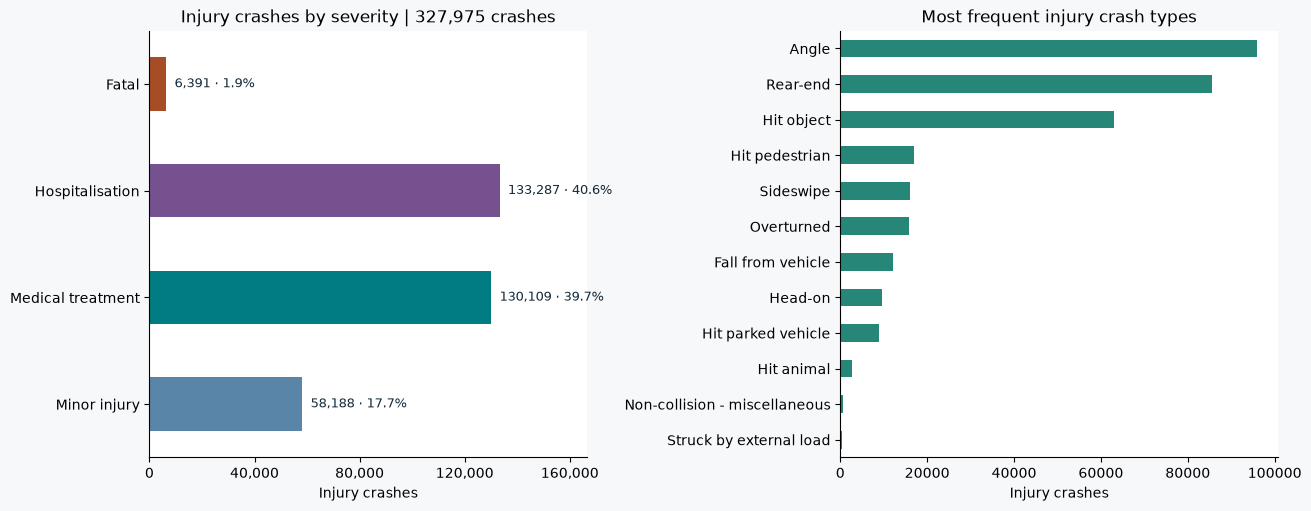

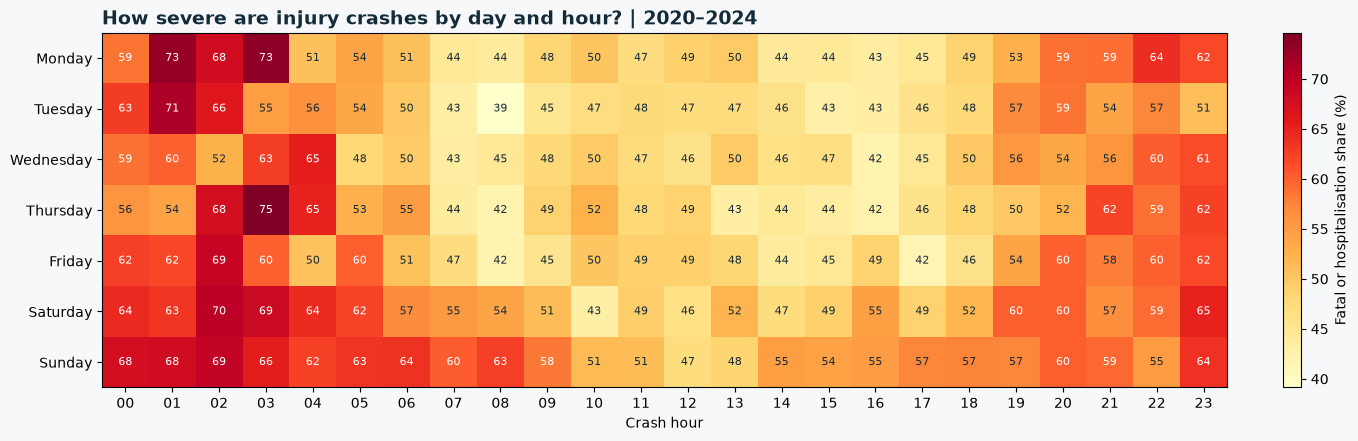

,Injury crashes,Fatal or hospitalisation (%),Fatal (%)
"Weekday, 05:00–21:59",46196.0,47.12,1.57
"Weekend, 22:00–04:59",2527.0,64.62,3.76


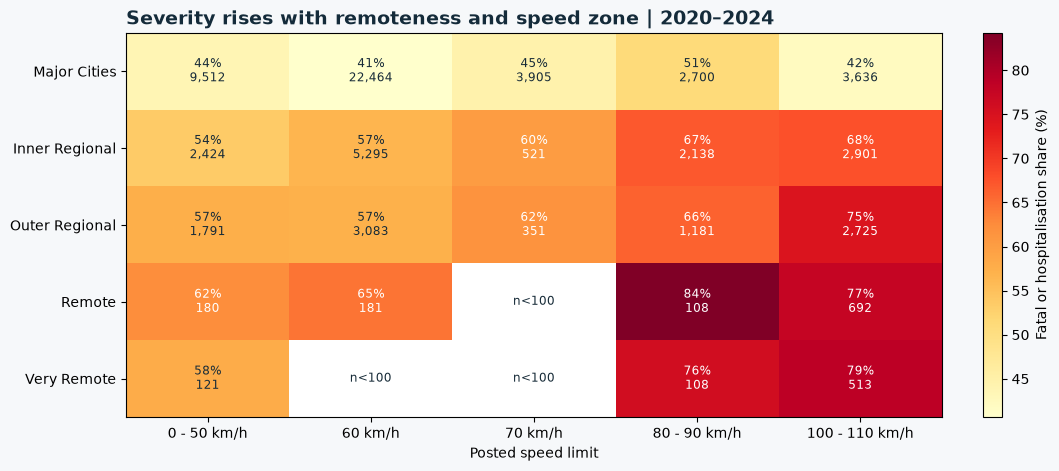

Injury crashes  Fatal (%)
Remoteness area Major Cities             42217       1.01
                Inner Regional           13279       3.08
                Outer Regional            9131       3.72
                Remote                    1173       6.48
                Very Remote                823       6.32
Speed zone      0 - 50 km/h              14028       1.06
                60 km/h                  31101       0.96
                70 km/h                   4792       1.96
                80 - 90 km/h              6235       3.32
                100 - 110 km/h           10468       5.32

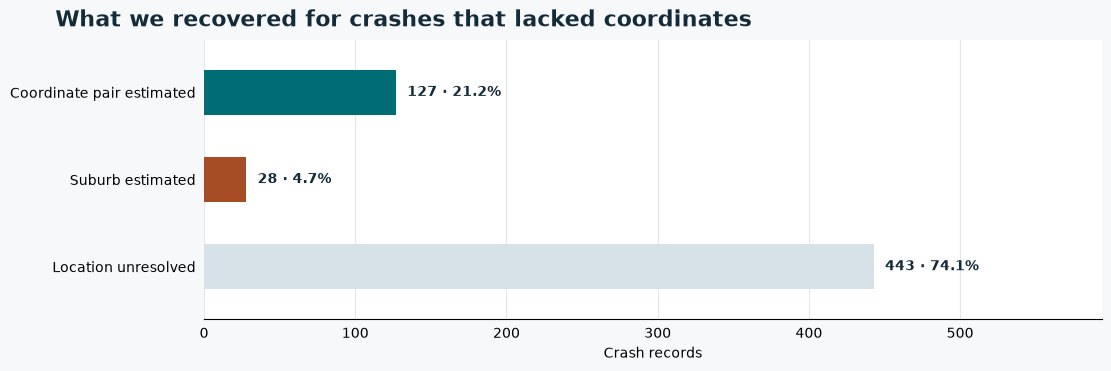

In [9]:
import matplotlib.pyplot as plt

severity = cleaned['Crash_Severity'].value_counts()
display(severity.to_frame('Crashes').assign(Share=(severity / len(cleaned)).map('{:.1%}'.format)))

# Property-damage-only crashes are recorded only in the early years, so the charts use injury crashes.
severity_order = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
injury_only = cleaned.loc[cleaned['Crash_Severity'].isin(severity_order)]
injury_serious = injury_only['Crash_Severity'].isin(['Fatal', 'Hospitalisation'])
injury_fatal = injury_only['Crash_Severity'].eq('Fatal')
injury_severity = injury_only['Crash_Severity'].value_counts().reindex(severity_order)
assert injury_severity.sum() == len(injury_only) == len(cleaned) - severity['Property damage only']

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', facecolor='#f6f8fa')
injury_severity.iloc[::-1].plot.barh(ax=axes[0], color=['#5985a8', '#007c82', '#76518f', '#a64d25'],
                                     title=f'Injury crashes by severity | {len(injury_only):,} crashes')
for position, count in enumerate(injury_severity.iloc[::-1]):
    axes[0].annotate(f'{count:,} · {count / len(injury_only):.1%}', (count, position), xytext=(6, 0),
                     textcoords='offset points', va='center', fontsize=9, color='#142b3a')
axes[0].set_xlim(0, injury_severity.max() * 1.25)
axes[0].set_xticks(range(0, 160_001, 40_000), [f'{tick:,}' for tick in range(0, 160_001, 40_000)])
injury_only['Crash_Nature'].value_counts().head(12).sort_values().plot.barh(
    ax=axes[1], color='#268677', title='Most frequent injury crash types'
)
for ax in axes:
    ax.set(xlabel='Injury crashes', ylabel='')
    ax.set_xlabel('Injury crashes')
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

# Severity shares use the stable severity window, so they are not mixed across coding periods.
window_injury = injury_only.loc[injury_only['Crash_Year'].isin(stable_years)]
window_serious = window_injury['Crash_Severity'].isin(['Fatal', 'Hospitalisation'])
window_fatal = window_injury['Crash_Severity'].eq('Fatal')
window_label = f'{stable_years.min()}–{stable_years.max()}'

hourly = pd.crosstab(injury_only['Crash_Severity'], injury_only['Crash_Hour']).reindex(severity_order)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Serious share for each day-of-week and hour cell.
day_hour = window_serious.groupby([window_injury['Crash_Day_Of_Week'], window_injury['Crash_Hour']]).agg(['size', 'mean'])
day_hour_count = day_hour['size'].unstack().reindex(day_order)
# Cells with fewer than 50 crashes are left blank.
day_hour_share = day_hour['mean'].unstack().reindex(day_order).mul(100).where(day_hour_count.ge(50))
assert day_hour_count.sum().sum() == len(window_injury)
fig, ax = plt.subplots(figsize=(13.5, 4.3), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(day_hour_share, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(24), xticklabels=[f'{hour:02}' for hour in day_hour_share.columns],
       yticks=range(7), yticklabels=day_order, xlabel='Crash hour')
ax.set_title(f'How severe are injury crashes by day and hour? | {window_label}', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
for row, col in np.ndindex(day_hour_share.shape):
    value = day_hour_share.iat[row, col]
    ax.text(col, row, f'{value:.0f}' if np.isfinite(value) else '', ha='center', va='center', fontsize=8,
            color='white' if np.isfinite(value) and value > 58 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatal or hospitalisation share (%)')
plt.show()

# Contrast weekend nights with weekday daytime and evening.
night_hours = [22, 23, 0, 1, 2, 3, 4]
weekend_night = (window_injury['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday'])
                 & window_injury['Crash_Hour'].isin(night_hours))
weekday_day = (~window_injury['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday'])
               & ~window_injury['Crash_Hour'].isin(night_hours))
timing_contrast = pd.DataFrame({
    label: {'Injury crashes': int(mask.sum()),
            'Fatal or hospitalisation (%)': 100 * window_serious[mask].mean(),
            'Fatal (%)': 100 * window_fatal[mask].mean()}
    for label, mask in [('Weekday, 05:00–21:59', weekday_day), ('Weekend, 22:00–04:59', weekend_night)]
}).T
display(timing_contrast.round(2))

remoteness_order = ['Major Cities', 'Inner Regional', 'Outer Regional', 'Remote', 'Very Remote']
speed_order = ['0 - 50 km/h', '60 km/h', '70 km/h', '80 - 90 km/h', '100 - 110 km/h']
# Serious share by remoteness area and speed zone. Cells with fewer than 100 crashes are left blank.
setting = window_serious.groupby([window_injury['Loc_ABS_Remoteness'], window_injury['Crash_Speed_Limit']]).agg(['size', 'mean'])
setting_count = setting['size'].unstack().reindex(index=remoteness_order, columns=speed_order).fillna(0).astype(int)
setting_share = setting['mean'].unstack().reindex(index=remoteness_order, columns=speed_order).mul(100)
setting_share = setting_share.where(setting_count.ge(100))
fig, ax = plt.subplots(figsize=(10.5, 4.6), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(setting_share, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(len(speed_order)), xticklabels=speed_order, yticks=range(len(remoteness_order)),
       yticklabels=remoteness_order, xlabel='Posted speed limit')
ax.set_title(f'Severity rises with remoteness and speed zone | {window_label}', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
for row, col in np.ndindex(setting_share.shape):
    value, count = setting_share.iat[row, col], setting_count.iat[row, col]
    label = f'{value:.0f}%\n{count:,}' if np.isfinite(value) else f'n<100'
    ax.text(col, row, label, ha='center', va='center', fontsize=8.5,
            color='white' if np.isfinite(value) and value > 58 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatal or hospitalisation share (%)')
plt.show()

setting_summary = pd.concat({
    'Remoteness area': pd.DataFrame({'Injury crashes': window_injury.groupby('Loc_ABS_Remoteness').size(),
                                     'Fatal (%)': window_fatal.groupby(window_injury['Loc_ABS_Remoteness']).mean().mul(100)}
                                    ).reindex(remoteness_order),
    'Speed zone': pd.DataFrame({'Injury crashes': window_injury.groupby('Crash_Speed_Limit').size(),
                                'Fatal (%)': window_fatal.groupby(window_injury['Crash_Speed_Limit']).mean().mul(100)}
                               ).reindex(speed_order),
})
display(setting_summary.round(2))

# Show what was recovered from the records that started with missing coordinates.
resolved_pair_count = int(available['Coordinate pair'].loc[targets].sum())
suburb_only_count = int((~available['Coordinate pair'] & available['Suburb']).loc[targets].sum())
missing_both_count = len(targets) - resolved_pair_count - suburb_only_count
fig, ax = plt.subplots(figsize=(11, 3.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('What we recovered for crashes that lacked coordinates', x=.045, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
categories = [
    ('Coordinate pair estimated', resolved_pair_count, '#006d75'),
    ('Suburb estimated', suburb_only_count, '#a64d25'),
    ('Location unresolved', missing_both_count, '#d7e1e8'),
]
counts = [count for _, count, _ in categories]
ax.barh(range(len(categories)), counts, color=[color for _, _, color in categories], height=.52)
ax.set(yticks=range(len(categories)), yticklabels=[label for label, _, _ in categories],
       ylim=(2.6, -.6), xlim=(0, max(counts) * 1.34), xlabel='Crash records')
for y, (_, count, _) in enumerate(categories):
    ax.annotate(f'{count:,} · {count / len(targets):.1%}', (count, y), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=10, color='#142b3a', fontweight='bold')
ax.grid(axis='x', color='#e1e8ed', zorder=0)
ax.set_axisbelow(True)
ax.tick_params(length=0, pad=6)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

**What this achieved.** Summarised injury-crash severity, crash types, timing, road setting and location recovery. Of 327,975 injury crashes, 133,287 (40.6%) led to hospitalisation and 6,391 (1.9%) were fatal, and 15:00 had the most injury crashes. The severity heatmaps and contrasts now use the 2020–2024 window. There, the fatal-or-hospitalisation share was 64.6% on weekend nights (22:00–04:59) compared with 47.1% on weekdays between 05:00 and 21:59, and the fatal share was 3.76% compared with 1.57%. V5 reported 57.0% and 39.9% pooled over 2001–2025. The gap is similar, but the levels reflect current grading. The fatal share rose from 1.01% in major cities to 6.48% in remote and 6.32% in very remote areas, and from 0.96% in 60 km/h zones to 5.32% in 100–110 km/h zones. These are shares of recorded injury crashes. If minor crashes are less completely reported in remote areas, the remote shares are overstated.

#### Map the crashes

Toggle the sampled density and severity layers. Inferred coordinates appear in their own optional layer. Its markers are approximate locations, with the estimation method in each tooltip. Both interactive maps use Esri World Street Map.

**In this cell.** Build a Folium map on an Esri basemap. Show observed crash density as a heatmap, add sampled markers by severity, and place estimated coordinates in their own map layer.

In [10]:
from html import escape

import folium
from folium.plugins import HeatMap

# Keep observed and estimated coordinates apart so that estimates never feed the density layer.
map_points = cleaned.dropna(subset=COORDS)
observed_points = map_points.loc[map_points['Coordinate_Method'].eq('observed')]
inferred_points = map_points.loc[map_points['Coordinate_Method'].ne('observed')]
severity_colors = {
    'Fatal': '#9d2525', 'Hospitalisation': '#db6820', 'Medical treatment': '#8c618f',
    'Minor injury': '#197a8c', 'Property damage only': '#456c46',
}
crash_map = folium.Map(
    location=observed_points[COORDS].median().tolist(), zoom_start=6, tiles='Esri.WorldStreetMap'
)
# A 5,000-point sample keeps the heatmap responsive.
density_points = observed_points.sample(n=min(5000, len(observed_points)), random_state=SEED)
HeatMap(density_points[COORDS].to_numpy().tolist(), name='Observed crash density', radius=14).add_to(crash_map)

# One optional layer of sampled markers per severity level.
for level, color in severity_colors.items():
    layer = folium.FeatureGroup(name=level, show=False).add_to(crash_map)
    rows = observed_points.loc[observed_points['Crash_Severity'].eq(level), COORDS]
    for point in rows.sample(n=min(180, len(rows)), random_state=SEED).to_numpy().tolist():
        folium.CircleMarker(point, radius=3, color=color, fill=True, fill_opacity=.65,
                            weight=1, tooltip=level).add_to(layer)

# Estimated locations sit in their own layer, with the estimation method in each tooltip.
estimate_layer = folium.FeatureGroup(name='Inferred coordinates', show=False).add_to(crash_map)
for lat, lon, method in inferred_points[[*COORDS, 'Coordinate_Method']].itertuples(index=False, name=None):
    folium.CircleMarker([lat, lon], radius=3, color='#53389e', fill=True, fill_opacity=.55,
                        weight=1, tooltip=escape(method)).add_to(estimate_layer)
folium.LayerControl(collapsed=False).add_to(crash_map)
display(crash_map)

**Static picture of the map above.** A saved notebook may show "Make this Notebook Trusted to load map" in place of an interactive map. The picture below shows the same view from the run saved on 20 November 2026. For the interactive version, run the cell above or open `Queensland Traffic V6 - Esri Maps.html` in a browser.

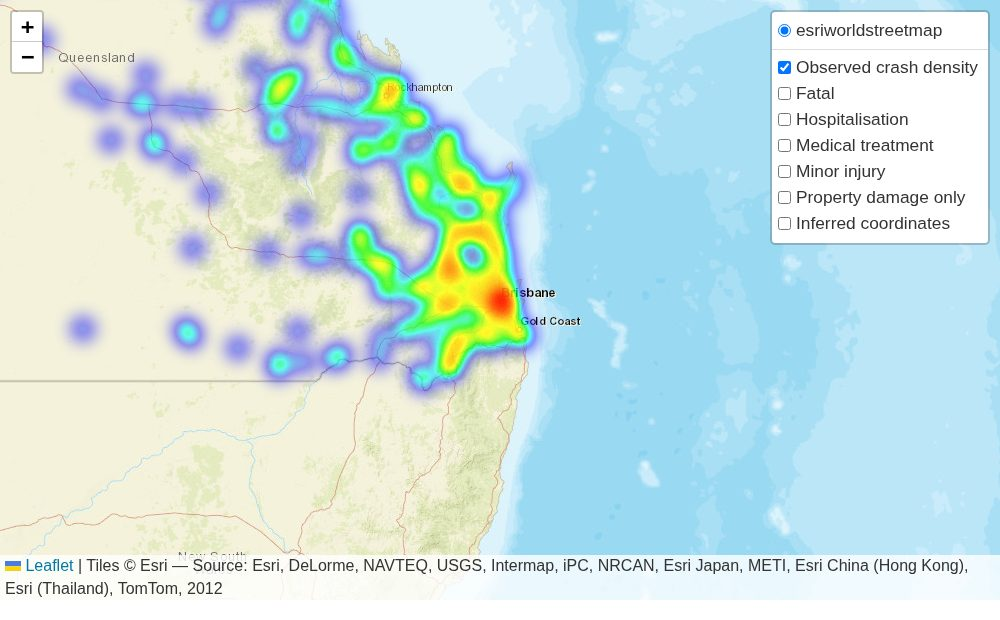

**What this achieved.** Built an interactive Esri map with observed crash density, sampled severity markers and a separate layer for estimated coordinates.

#### Vehicle involvement and crash severity

Use the aggregate vehicle table and weight by `Count_Crashes`. Compare cases involving a motorcycle or moped, a truck, or a bus with cases without that particular flag. A crash can involve multiple vehicle types. Reported injury crashes are the common basis for severity and trend comparisons because property-damage-only coverage changes over time. The latest five complete years in the locations file set the comparison window. The partial 2025 series is excluded from full-year comparisons.

The fatal and hospitalisation shares describe severity among recorded injury crashes. Vehicle trips, distance travelled, and fleet exposure are outside the source data.

**In this cell.** Weight the vehicle analysis by reported crash counts and compare injury severity with and without each vehicle flag. Use annual trends, paired comparisons, and box plots to show how involvement and severity vary across complete years.

Vehicle severity comparison for 2020–2024


Injury crashes  Fatal crashes  Fatal share (%)  \
Vehicle             Status                                                     
Motorcycle or moped Involved            8022            351             4.38   
                    Absent             58602            953             1.63   
Truck               Involved            4482            217             4.84   
                    Absent             62142           1087             1.75   
Bus                 Involved             934             19             2.03   
                    Absent             65690           1285             1.96   

                              Fatal or hospitalisation (%)  
Vehicle             Status                                  
Motorcycle or moped Involved                         72.36  
                    Absent                           46.79  
Truck               Involved                         53.06  
                    Absent                           49.64  
Bus                 Involved                         45.07  
                    Absent                           49.94

,Recorded injury crashes
None of these three flags,53437
Motorcycle or moped,7801
Truck,4268
Bus,867
Motorcycle or moped + Truck,184
Motorcycle or moped + Bus,37
Truck + Bus,30


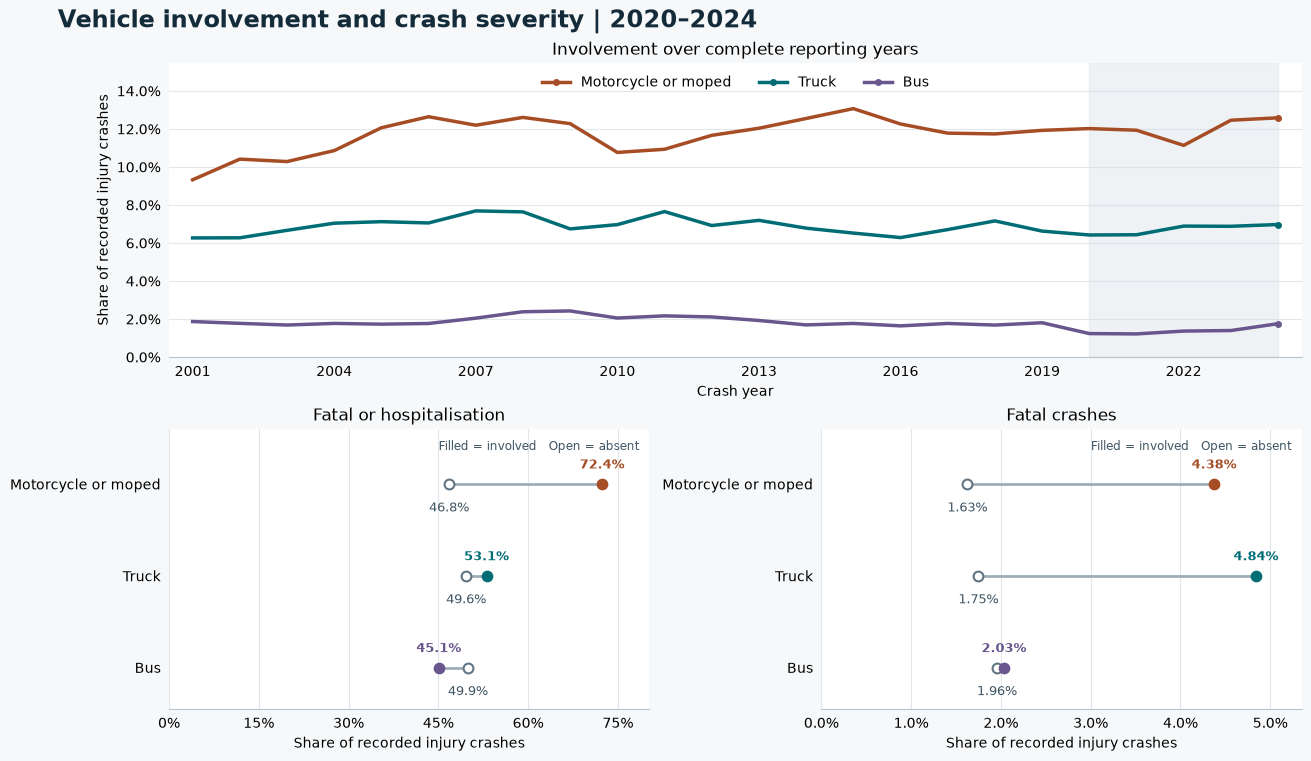

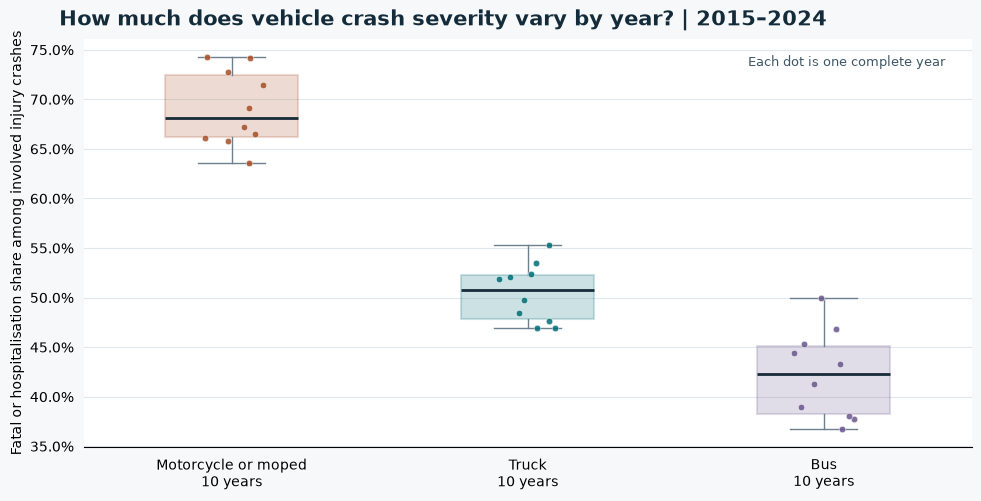

In [11]:
import matplotlib.ticker as mticker

# A complete year has crashes in all 12 months. The latest five set the comparison window.
complete_years = raw.groupby('Crash_Year')['Crash_Month'].nunique()
complete_years = complete_years.index[complete_years.eq(12)]
recent_years = complete_years[-5:]
injury_labels = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
severe_labels = ['Fatal', 'Hospitalisation']
vehicle_flags = {
    'Motorcycle or moped': 'Involving_Motorcycle_Moped',
    'Truck': 'Involving_Truck',
    'Bus': 'Involving_Bus',
}
# Injury crashes only, because property-damage-only coverage changes over time.
vehicle_injury = regional_sources['Vehicles'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].copy()
vehicle_recent = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(recent_years)]
assert vehicle_recent['Crash_Severity'].isin(injury_labels).all()
# Severity shares with and without each vehicle flag, weighted by crash counts.
vehicle_metrics = []
for kind, flag in vehicle_flags.items():
    for answer, label in [('Yes', 'Involved'), ('No', 'Absent')]:
        cohort = vehicle_recent.loc[vehicle_recent[flag].eq(answer)]
        counts = cohort.groupby('Crash_Severity')['Count_Crashes'].sum().reindex(injury_labels, fill_value=0)
        total = int(counts.sum())
        vehicle_metrics.append({
            'Vehicle': kind, 'Status': label, 'Injury crashes': total,
            'Fatal crashes': int(counts['Fatal']),
            'Fatal share (%)': 100 * counts['Fatal'] / total if total else np.nan,
            'Fatal or hospitalisation (%)': 100 * counts[severe_labels].sum() / total if total else np.nan,
        })
vehicle_severity = pd.DataFrame(vehicle_metrics).set_index(['Vehicle', 'Status'])
print(f'Vehicle severity comparison for {recent_years.min()}–{recent_years.max()}')
display(vehicle_severity.round(2))

# Annual involvement share for each vehicle flag over complete years.
annual_vehicle = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(complete_years)]
annual_vehicle_total = annual_vehicle.groupby('Crash_Year')['Count_Crashes'].sum()
vehicle_trends = pd.DataFrame({
    kind: annual_vehicle['Count_Crashes'].where(annual_vehicle[flag].eq('Yes'), 0)
    .groupby(annual_vehicle['Crash_Year']).sum().div(annual_vehicle_total).mul(100)
    for kind, flag in vehicle_flags.items()
})
flag_pattern_counts = vehicle_recent.groupby(list(vehicle_flags.values()))['Count_Crashes'].sum()
flag_labels = [' + '.join(kind for kind, value in zip(vehicle_flags, combination) if value == 'Yes')
               or 'None of these three flags' for combination in flag_pattern_counts.index]
vehicle_overlap = flag_pattern_counts.set_axis(flag_labels).sort_values(ascending=False)
assert vehicle_overlap.sum() == vehicle_recent['Count_Crashes'].sum()
display(vehicle_overlap.to_frame('Recorded injury crashes'))

fig = plt.figure(figsize=(13, 7.5), layout='constrained', facecolor='#f6f8fa')
grid = fig.add_gridspec(2, 2, height_ratios=[1.05, 1])
trend = fig.add_subplot(grid[0, :])
severity_axes = [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
fig.suptitle(f'Vehicle involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.04, ha='left', fontsize=17, fontweight='bold', color='#142b3a')
vehicle_colors = {'Motorcycle or moped': '#a64d25', 'Truck': '#006d75', 'Bus': '#68568d'}

for kind, color in vehicle_colors.items():
    trend.plot(vehicle_trends.index, vehicle_trends[kind], linewidth=2.5, color=color, label=kind,
               marker='o', markersize=4, markevery=[-1])
trend.axvspan(recent_years.min(), recent_years.max(), color='#cfdae4', alpha=.35)
trend.set(title='Involvement over complete reporting years', xlabel='Crash year',
          ylabel='Share of recorded injury crashes')
trend.yaxis.set_major_formatter(mticker.PercentFormatter())
trend.set_xlim(vehicle_trends.index.min() - .5, vehicle_trends.index.max() + .5)
trend.set_ylim(0, float(vehicle_trends.max().max()) + 2.4)
trend.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
trend.legend(loc='upper center', frameon=False, ncols=3, bbox_to_anchor=(.5, 1.0))

for ax, field, title, step in zip(
    severity_axes, ['Fatal or hospitalisation (%)', 'Fatal share (%)'],
    ['Fatal or hospitalisation', 'Fatal crashes'], [15, 1],
):
    by_flag = vehicle_severity[field].unstack().reindex(vehicle_flags)
    for y, (kind, row) in enumerate(by_flag.iterrows()):
        involved, absent = row['Involved'], row['Absent']
        ax.hlines(y, min(involved, absent), max(involved, absent), color='#9eaeb8', lw=2, zorder=2)
        ax.scatter(absent, y, s=50, facecolor='white', edgecolor='#637582', linewidth=1.5, zorder=3)
        ax.scatter(involved, y, s=55, color=vehicle_colors[kind], zorder=4)
        digits = 2 if field == 'Fatal share (%)' else 1
        ax.annotate(f'{absent:.{digits}f}%', (absent, y), xytext=(0, -13), textcoords='offset points',
                    ha='center', va='top', fontsize=9, color='#405664')
        ax.annotate(f'{involved:.{digits}f}%', (involved, y), xytext=(0, 9), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color=vehicle_colors[kind], fontweight='bold')
    ax.set(yticks=range(len(by_flag)), yticklabels=by_flag.index,
           ylim=(len(by_flag)-.55, -.6), xlim=(0, step * (np.ceil(by_flag.max().max()/step) + .35)),
           xlabel='Share of recorded injury crashes', title=title)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(step))
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.text(.98, .96, 'Filled = involved   Open = absent', transform=ax.transAxes,
            va='top', ha='right', fontsize=8.5, color='#405664')

for ax in [trend, *severity_axes]:
    ax.set_facecolor('white')
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#b8c4cc')
    ax.tick_params(length=0, pad=6)
    ax.grid(axis='y' if ax is trend else 'x', color='#e1e8ed', zorder=0)
    ax.set_axisbelow(True)
plt.show()


# Compare variability across years using one within-vehicle rate per complete year.
box_years = complete_years[-10:]
boxes = []
for kind, flag in vehicle_flags.items():
    involved = vehicle_injury.loc[vehicle_injury[flag].eq('Yes') & vehicle_injury['Crash_Year'].isin(box_years)]
    annual_totals = involved.groupby('Crash_Year')['Count_Crashes'].sum()
    annual_severe = involved['Count_Crashes'].where(involved['Crash_Severity'].isin(severe_labels), 0)
    annual_severe = annual_severe.groupby(involved['Crash_Year']).sum()
    boxes.append(annual_severe.div(annual_totals.where(annual_totals.gt(0))).mul(100).dropna().to_numpy())

fig, ax = plt.subplots(figsize=(9.7, 4.9), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'How much does vehicle crash severity vary by year? | {box_years.min()}–{box_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
boxplot = ax.boxplot(boxes, widths=.45, patch_artist=True, showfliers=False,
                     medianprops={'color': '#172b38', 'linewidth': 2},
                     whiskerprops={'color': '#6d808e'}, capprops={'color': '#6d808e'})
jitter = np.random.default_rng(SEED)
for x, ((kind, color), values, box) in enumerate(zip(vehicle_colors.items(), boxes, boxplot['boxes']), start=1):
    box.set(facecolor=color, alpha=.20, edgecolor=color, linewidth=1.5)
    ax.scatter(x + jitter.uniform(-.11, .11, len(values)), values,
               s=22, color=color, alpha=.85, edgecolor='white', linewidth=.4, zorder=3)
ax.set(xticks=range(1, len(boxes) + 1),
       xticklabels=[f'{kind}\n{len(values)} years' for kind, values in zip(vehicle_flags, boxes)],
       ylabel='Fatal or hospitalisation share among involved injury crashes')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(length=0, pad=7)
ax.text(.97, .96, 'Each dot is one complete year', transform=ax.transAxes,
        ha='right', va='top', fontsize=9, color='#405664')
plt.show()

**What this achieved.** Compared injury outcomes for the three vehicle flags using weighted crash counts. The plots show the recent severity contrast, annual involvement trends, and year-to-year variation over complete years.

#### Combine all six sources by crash year and police region

Aggregate each source to one row per year and police region before joining. Preserve each source’s own denominator. A crash can appear in several source summaries and can meet several flags, so use the source totals for their respective rates. Missing groups stay blank. This table uses the reported police regions for consistency across sources.

**In this cell.** Aggregate each source to one row per crash year and police region, then align the six totals on that key. Compare group coverage and retain blanks where a source has no row for a group.

In [12]:
# One total per source for each year and police region, each from its own count column.
regional_totals = {
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
}
for source_name, count_field in {
    'Factors': 'Count_Crashes', 'Casualties': 'Casualty_Count', 'Vehicles': 'Count_Crashes',
    'Demographics': 'Count_Crashes', 'Restraints': 'Casualty_Count',
}.items():
    regional_totals[source_name] = regional_sources[source_name].groupby(
        group_fields, dropna=False
    )[count_field].sum(min_count=1)

regional_summary = pd.concat(regional_totals, axis=1).sort_index().astype('Int64')
assert regional_summary.index.is_unique
for name, source_total in regional_totals.items():
    assert regional_summary[name].sum() == source_total.sum()
print(f'{len(regional_summary):,} year-region groups | '
      f'{regional_summary.notna().all(axis=1).sum():,} represented in all six files')
display(regional_summary.tail(12))
# List the groups that at least one source does not report.
missing_sources = regional_summary.loc[regional_summary.isna().any(axis=1)]
if not missing_sources.empty:
    display(missing_sources)

186 year-region groups | 184 represented in all six files


Locations  Factors  Casualties  Vehicles  \
Crash_Year Police_Region                                             
2024       Far Northern         723      723         965       723   
           North Coast         2745     2745        3634      2745   
           Northern             756      756        1010       756   
           South Eastern       3141     3141        4085      3141   
           Southern            1852     1852        2596      1852   
2025       Brisbane            1889     1889        2397      1889   
           Central              585      585         786       585   
           Far Northern         345      345         467       345   
           North Coast         1372     1372        1834      1372   
           Northern             359      359         486       359   
           South Eastern       1529     1529        2004      1529   
           Southern             950      950        1272       950   

                          Demographics  Restraints  
Crash_Year Police_Region                            
2024       Far Northern            723         882  
           North Coast            2745        3382  
           Northern                756         904  
           South Eastern          3141        3846  
           Southern               1852        2497  
2025       Brisbane               1889        2221  
           Central                 585         721  
           Far Northern            345         425  
           North Coast            1372        1724  
           Northern                359         432  
           South Eastern          1529        1896  
           Southern                950        1207

,,Locations,Factors,Casualties,Vehicles,Demographics,Restraints
Crash_Year,Police_Region,,,,,,
2009,Unknown,7,7,<NA>,7,7,<NA>
2010,Unknown,36,36,<NA>,36,36,<NA>


**What this achieved.** Created a source totals table with one row per year and police region. All six files contribute to 184 of the 186 groups.

##### Explore vehicle involvement, driver characteristics, and safety

The flag table shows the share of each recorded severity group that involved each characteristic within its own source. The restraint table sums casualty counts by recorded restraint or helmet category. These descriptive counts reflect the reporting scope of the source tables.

**In this cell.** Calculate the share of crashes with each vehicle, driver, or contributing-factor flag within each recorded severity group. The overseas-licensed driver flag is left out because it stops being recorded during the series. Summarise restraint categories with weighted casualty counts. Plot annual casualty totals as counts and as an index of the first year, so the small fatality series and the larger injury series can be compared on one scale. The annual plot includes years with all 12 months represented in the locations file.

Crash severity (%)                 Hospitalisation  Medical treatment  \
Source       Recorded factor                                            
Factors      Drink Driving                     9.5                4.0   
             Driver Speed                      5.1                2.6   
             Fatigued Driver                   2.9                1.6   
             Defective Vehicle                 2.2                1.7   
Vehicles     Motorcycle Moped                 17.0                8.1   
             Truck                             7.0                6.5   
             Bus                               1.6                2.0   
Demographics Male Driver                      76.3               75.2   
             Female Driver                    46.2               58.4   
             Young Driver 16-24               33.4               37.6   
             Senior Driver 60plus             21.1               19.7   
             Provisional Driver               18.5               20.6   
             Unlicensed Driver                 7.3                4.6   

Crash severity (%)                 Property damage only  Minor injury  Fatal  
Source       Recorded factor                                                  
Factors      Drink Driving                          8.2           4.5   21.5  
             Driver Speed                           6.1           3.0   22.8  
             Fatigued Driver                        2.0           1.6    5.9  
             Defective Vehicle                      3.2           1.8    2.5  
Vehicles     Motorcycle Moped                       0.4           6.9   21.3  
             Truck                                  8.5           6.5   17.0  
             Bus                                    1.3           1.8    1.8  
Demographics Male Driver                           79.7          77.1   85.5  
             Female Driver                         46.0          55.3   27.9  
             Young Driver 16-24                    45.7          37.7   28.4  
             Senior Driver 60plus                  16.2          18.2   23.5  
             Provisional Driver                    27.5          21.0   15.1  
             Unlicensed Driver                      6.1           4.8   11.8

Casualty_Severity,Fatality,Hospitalised,Medically treated,Minor injury
Casualty_Restraint_Helmet_Use,,,,
Helmet Not Worn,127,2082,841,445
Helmet Use Not determined,83,1386,1287,1757
Helmet Worn,1357,27944,16312,6043
Not applicable,54,809,704,450
Restrained,2408,94834,117813,61516
Restraint Use Not determined,1280,21456,26085,18976
Unrestrained,884,5135,3462,1618


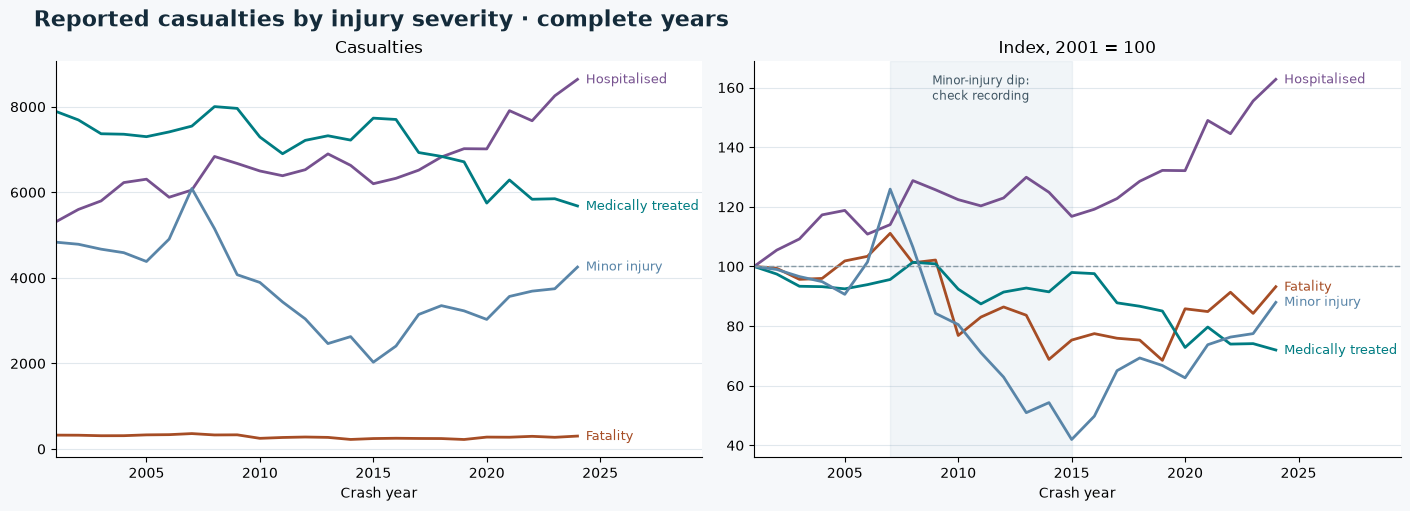

,2001,2024,Change (%)
Casualty_Severity,,,
Fatality,324,302,-6.8
Hospitalised,5309,8641,62.8
Medically treated,7893,5681,-28.0
Minor injury,4835,4253,-12.0


In [13]:
severity_flags = []
for source_name in ['Factors', 'Vehicles', 'Demographics']:
    frame = regional_sources[source_name]
    denominator = frame.groupby('Crash_Severity')['Count_Crashes'].sum()
    # The overseas-licensed flag stops being recorded part-way through the series.
    for flag in [column for column in frame if column.startswith('Involving_')
                 and column != 'Involving_Overseas_Licensed_Driver']:
        yes_counts = (frame['Count_Crashes'].where(frame[flag].eq('Yes'), 0)
                      .groupby(frame['Crash_Severity']).sum())
        percentages = yes_counts.div(denominator.where(denominator.gt(0))).mul(100)
        severity_flags.append(percentages.rename((source_name, flag.removeprefix('Involving_').replace('_', ' '))))
flag_shares = pd.DataFrame(severity_flags)
flag_shares.index = pd.MultiIndex.from_tuples(flag_shares.index, names=['Source', 'Recorded factor'])
display(flag_shares.reindex(columns=severity.index).round(1).rename_axis('Crash severity (%)', axis=1))

safety_rows = regional_sources['Restraints']
restraint_counts = safety_rows.pivot_table(
    index='Casualty_Restraint_Helmet_Use', columns='Casualty_Severity',
    values='Casualty_Count', aggfunc='sum', fill_value=0,
)
display(restraint_counts)
annual_casualties = regional_sources['Casualties'].pivot_table(
    index='Crash_Year', columns='Casualty_Severity', values='Casualty_Count', aggfunc='sum',
)
annual_casualties = annual_casualties.loc[annual_casualties.index.isin(complete_years)]
casualty_order = ['Fatality', 'Hospitalised', 'Medically treated', 'Minor injury']
casualty_colors = dict(zip(casualty_order, ['#a64d25', '#76518f', '#007c82', '#5985a8']))
annual_casualties = annual_casualties[casualty_order]
casualty_index = annual_casualties.div(annual_casualties.iloc[0]).mul(100)
first_year, last_year = int(annual_casualties.index[0]), int(annual_casualties.index[-1])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('Reported casualties by injury severity · complete years', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
for ax, values, title, unit in [
    (axes[0], annual_casualties, 'Casualties', ''),
    (axes[1], casualty_index, f'Index, {first_year} = 100', ''),
]:
    for level in casualty_order:
        ax.plot(values.index, values[level], color=casualty_colors[level], linewidth=2)
        ax.annotate(level, (last_year, values[level].iloc[-1]), xytext=(6, 0), textcoords='offset points',
                    va='center', fontsize=9, color=casualty_colors[level])
    ax.set(title=title, xlabel='Crash year', xlim=(first_year, last_year + 5.5))
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(100, color='#879aa5', linewidth=1, linestyle='--')
axes[1].axvspan(minor_peak_before.idxmax(), minor_low_year, color='#5985a8', alpha=.08)
axes[1].text((minor_peak_before.idxmax() + minor_low_year) / 2, .97, 'Minor-injury dip:\ncheck recording',
             transform=axes[1].get_xaxis_transform(), ha='center', va='top', fontsize=8.5, color='#405664')
plt.show()
casualty_change = pd.DataFrame({
    first_year: annual_casualties.iloc[0], last_year: annual_casualties.iloc[-1],
    'Change (%)': casualty_index.iloc[-1] - 100,
})
display(casualty_change.round(1))

**What this achieved.** Compared weighted vehicle, driver and crash-factor flags by recorded severity and summarised helmet and restraint categories by injury outcome. Between 2001 and 2024, hospitalised casualties rose from 5,309 to 8,641 (62.8%), fatalities moved from 324 to 302, and medically treated casualties fell from 7,893 to 5,681 (28.0%). Hospitalised and medically treated counts moving in opposite directions may reflect a change in how injuries are classified as well as a change in outcomes, and the counts do not allow for population growth. The annual casualty trend ends in 2024. The partial 2025 records remain available in the source tallies.

##### Compare regional burden, severity and reported contributing factors

Join weighted measures at `Crash_Year` and `Police_Region`, where the sources have common coverage. Compare recorded injury crash volume, the serious crash share, the severe casualty share, speed and fatigue flags, heavy vehicle and motorcycle involvement, young-driver involvement, and protective equipment use. Each measure keeps its own within-source denominator. The protective equipment share uses records with a known helmet or restraint status.

These comparisons can identify regions where several issues warrant closer examination and show whether a high count reflects volume or a higher severity share. Associations between regional summaries do not establish that the same crashes shared those characteristics. The latest five complete years are pooled by summing numerators and denominators. The source category `Unknown` remains in the coverage audit.

**In this cell.** Build regional profiles from within-source numerators and denominators. Use scatter, bubble, and heatmap views to compare crash burden, severity, and reported factors, then summarise changes across two five-year periods.

Combined regional profile, 2020–2024


,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Police_Region,,,,,,,,,,
Brisbane,18395,40.1,37.1,2.4,1.3,4.9,6.6,12.5,32.3,2.3
South Eastern,14427,43.8,40.8,3.3,1.7,7.0,5.6,11.1,33.9,3.3
North Coast,13184,52.5,48.2,4.6,2.3,8.2,5.9,12.4,32.9,4.0
Southern,8161,56.9,51.9,4.8,3.2,8.0,8.6,11.1,33.1,4.2
Central,5568,66.5,60.9,5.2,4.6,9.8,9.6,11.2,31.3,5.0
Far Northern,3446,62.5,57.6,5.2,3.3,11.8,6.6,12.8,25.1,7.4
Northern,3443,61.1,56.2,4.6,2.7,9.5,6.1,14.9,30.9,7.2


,Highest police region,Value
Measure,,
Injury crashes,Brisbane,"18,395"
Serious crash (%),Central,66.5%
Speed (%),Far Northern,5.2%
Drink driving (%),Far Northern,11.8%
Truck (%),Central,9.6%
Motorcycle or moped (%),Northern,14.9%
Unrestrained or helmet not worn (%),Far Northern,7.4%


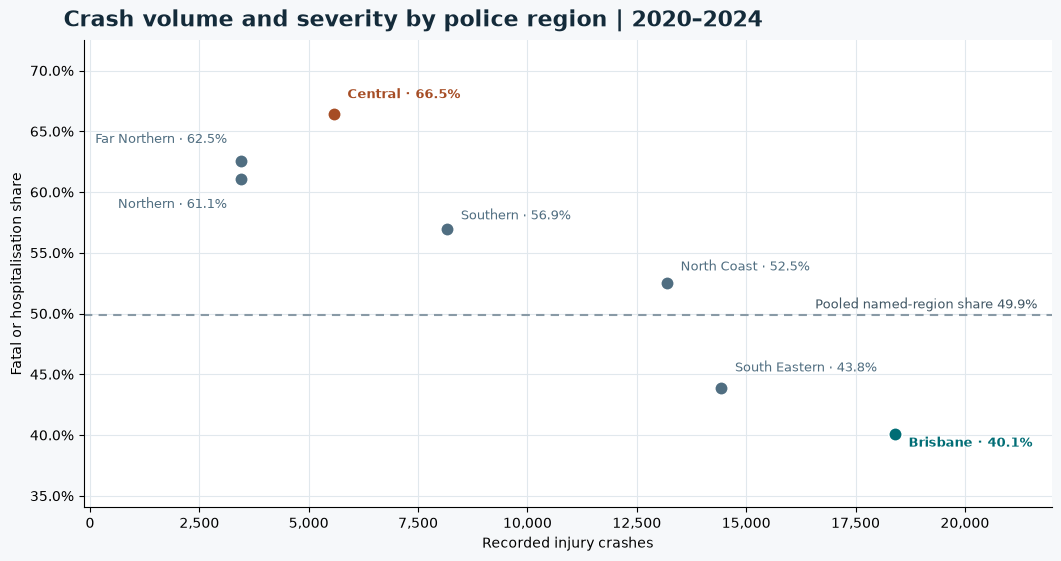

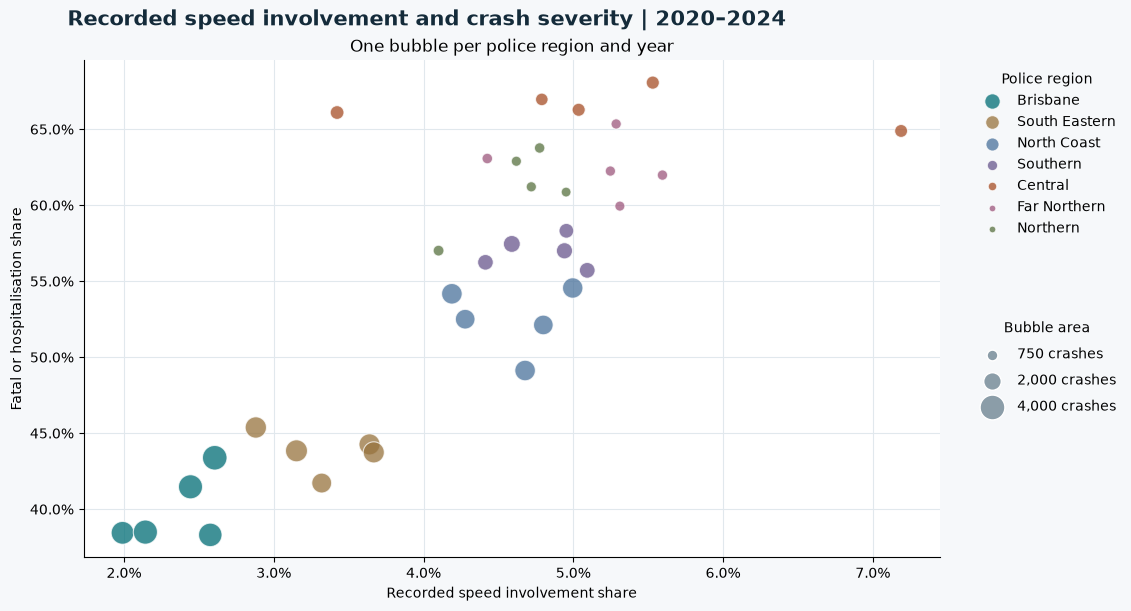

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


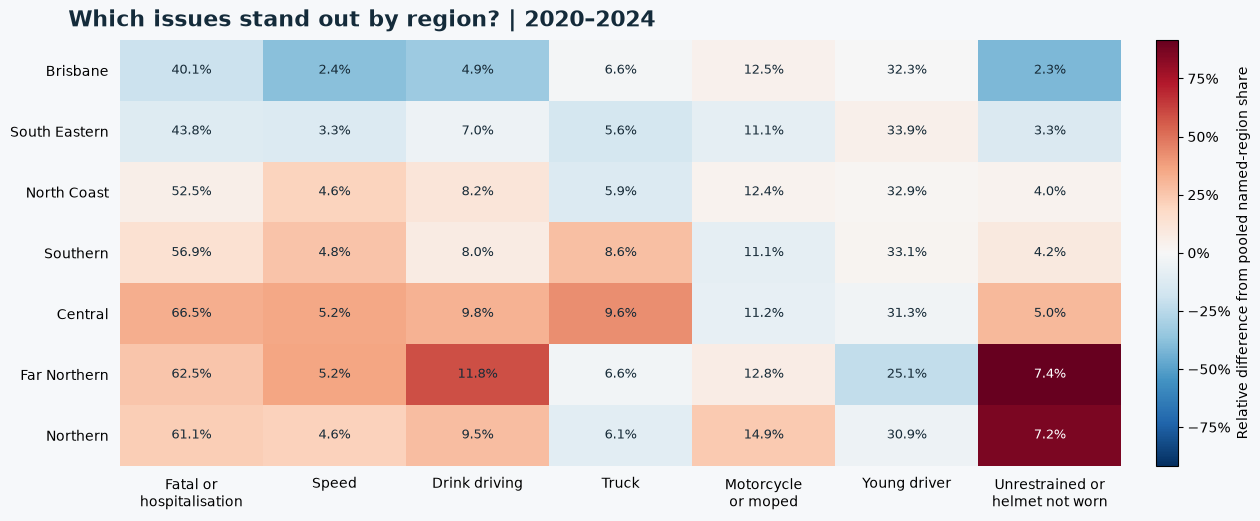

,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Period,,,,,,,,,,
2015–2019,63370,44.0,40.5,3.1,2.1,5.7,6.7,12.1,33.0,3.5
2020–2024,66624,49.9,46.2,3.8,2.3,7.4,6.7,12.0,32.3,3.9


In [14]:
# Numerator and denominator by group, kept separate so periods can be pooled before dividing.
def grouped_rate(frame, count, condition, group, label):
    denominator = frame.groupby(group, dropna=False)[count].sum(min_count=1)
    numerator = frame[count].where(condition, 0).groupby([frame[key] for key in group], dropna=False).sum()
    return pd.concat({f'{label} numerator': numerator, f'{label} denominator': denominator}, axis=1)


location_injury = regional_sources['Locations'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].assign(Records=1)
factor_injury = regional_sources['Factors'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
driver_injury = regional_sources['Demographics'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
casualty_records = regional_sources['Casualties']
known_equipment = safety_rows.loc[safety_rows['Casualty_Restraint_Helmet_Use'].isin([
    'Helmet Worn', 'Helmet Not Worn', 'Restrained', 'Unrestrained'
])]
# Each measure: (source table, count column, condition that defines the numerator).
metrics = {
    'Serious crash': (location_injury, 'Records', location_injury['Crash_Severity'].isin(severe_labels)),
    'Severe casualty': (casualty_records, 'Casualty_Count',
                        casualty_records['Casualty_Severity'].isin(['Fatality', 'Hospitalised'])),
    'Speed': (factor_injury, 'Count_Crashes', factor_injury['Involving_Driver_Speed'].eq('Yes')),
    'Fatigue': (factor_injury, 'Count_Crashes', factor_injury['Involving_Fatigued_Driver'].eq('Yes')),
    'Drink driving': (factor_injury, 'Count_Crashes', factor_injury['Involving_Drink_Driving'].eq('Yes')),
    'Truck': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Truck']].eq('Yes')),
    'Motorcycle or moped': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Motorcycle or moped']].eq('Yes')),
    'Young driver': (driver_injury, 'Count_Crashes', driver_injury['Involving_Young_Driver_16-24'].eq('Yes')),
    'Unrestrained or helmet not worn': (known_equipment, 'Casualty_Count',
        known_equipment['Casualty_Restraint_Helmet_Use'].isin(['Unrestrained', 'Helmet Not Worn'])),
}
regional_profile_counts = pd.concat([
    grouped_rate(frame, count, condition, group_fields, label)
    for label, (frame, count, condition) in metrics.items()
], axis=1)
assert regional_profile_counts.index.is_unique
for label in metrics:
    reported = regional_profile_counts[[f'{label} numerator', f'{label} denominator']].dropna()
    assert reported[f'{label} numerator'].le(reported[f'{label} denominator']).all()

# Pool the latest five complete years for the named regions.
regional_window = regional_profile_counts.loc[
    regional_profile_counts.index.get_level_values('Crash_Year').isin(recent_years)
    & (regional_profile_counts.index.get_level_values('Police_Region') != 'Unknown')
]
pooled_region = regional_window.groupby(level='Police_Region').sum(min_count=1)
regional_profile = pd.DataFrame({'Injury crashes': pooled_region['Serious crash denominator'].astype('Int64')})
for label in metrics:
    denominator = pooled_region[f'{label} denominator']
    regional_profile[f'{label} (%)'] = pooled_region[f'{label} numerator'].div(
        denominator.where(denominator.gt(0))
    ).mul(100)
regional_profile = regional_profile.sort_values('Injury crashes', ascending=False)
print(f'Combined regional profile, {recent_years.min()}–{recent_years.max()}')
display(regional_profile.round(1))

# Name the region with the highest value for each headline measure.
regional_findings = []
for field in ['Injury crashes', 'Serious crash (%)', 'Speed (%)', 'Drink driving (%)', 'Truck (%)',
              'Motorcycle or moped (%)', 'Unrestrained or helmet not worn (%)']:
    region = regional_profile[field].idxmax()
    value = regional_profile.at[region, field]
    formatted = f'{value:,}' if field == 'Injury crashes' else f'{value:.1f}%'
    regional_findings.append({'Measure': field, 'Highest police region': region, 'Value': formatted})
display(pd.DataFrame(regional_findings).set_index('Measure'))

fig, ax = plt.subplots(figsize=(10.5, 5.5), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Crash volume and severity by police region | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
reference = pooled_region['Serious crash numerator'].sum() / pooled_region['Serious crash denominator'].sum() * 100
ax.axhline(reference, color='#899aa6', linestyle=(0, (4, 3)), zorder=1)
ax.text(.985, reference + .55, f'Pooled named-region share {reference:.1f}%',
        transform=ax.get_yaxis_transform(), ha='right', fontsize=9, color='#405664')
label_offsets = {'Central': (10, 9), 'Far Northern': (-10, 11), 'Northern': (-10, -13),
                 'Southern': (10, 5), 'Brisbane': (10, -2), 'South Eastern': (10, 10)}
for region, row in regional_profile.iterrows():
    volume, serious_share = row[['Injury crashes', 'Serious crash (%)']]
    denotation = {'Brisbane': '#006d75', 'Central': '#a64d25'}.get(region, '#506e81')
    ax.scatter(volume, serious_share, s=95, color=denotation, edgecolor='white', linewidth=1.2, zorder=3)
    dx, dy = label_offsets.get(region, (10, 7))
    ax.annotate(f'{region} · {serious_share:.1f}%', (volume, serious_share), xytext=(dx, dy),
                textcoords='offset points', ha='right' if dx < 0 else 'left',
                va='bottom' if dy > 0 else 'top', color=denotation, fontsize=9,
                fontweight='bold' if region in {'Brisbane', 'Central'} else 'normal')
ax.set(xlabel='Recorded injury crashes', ylabel='Fatal or hospitalisation share')
ax.margins(x=.24, y=.23)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# Use one point per year and police region. Circle area represents injury crash volume.
speed_rate = (regional_window['Speed numerator'] / regional_window['Speed denominator'] * 100)
severity_rate = (regional_window['Serious crash numerator'] / regional_window['Serious crash denominator'] * 100)
bubble_data = pd.DataFrame({
    'Speed share': speed_rate, 'Severe share': severity_rate,
    'Injury crashes': regional_window['Serious crash denominator'],
}).dropna().reset_index()
region_colors = dict(zip(regional_profile.index,
                         ['#006d75', '#97733d', '#4a729b', '#68568d', '#a64d25', '#9d577d', '#587240']))
size_per_crash = .08
fig, ax = plt.subplots(figsize=(11.2, 6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Recorded speed involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
for region, color in region_colors.items():
    points = bubble_data[bubble_data['Police_Region'].eq(region)]
    ax.scatter(points['Speed share'], points['Severe share'], s=points['Injury crashes'] * size_per_crash,
               alpha=.75, color=color, edgecolor='white', linewidth=.8, label=region)
ax.set(xlabel='Recorded speed involvement share', ylabel='Fatal or hospitalisation share',
       title='One bubble per police region and year')
for axis in [ax.xaxis, ax.yaxis]:
    axis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
region_legend = ax.legend(title='Police region', bbox_to_anchor=(1.03, 1), loc='upper left',
                          frameon=False, markerscale=.65)
ax.add_artist(region_legend)
size_handles = [ax.scatter([], [], s=volume * size_per_crash, facecolor='#8b9da8', edgecolor='white',
                           label=f'{volume:,} crashes') for volume in [750, 2000, 4000]]
ax.legend(handles=size_handles, title='Bubble area', bbox_to_anchor=(1.03, .50),
          loc='upper left', frameon=False, labelspacing=.85)
plt.show()

from matplotlib.colors import TwoSlopeNorm

profile_fields = ['Serious crash', 'Speed', 'Drink driving', 'Truck', 'Motorcycle or moped', 'Young driver',
                  'Unrestrained or helmet not worn']
field_labels = ['Fatal or\nhospitalisation', 'Speed', 'Drink driving', 'Truck',
                'Motorcycle\nor moped', 'Young driver', 'Unrestrained or\nhelmet not worn']
profile_values = regional_profile[[f'{field} (%)' for field in profile_fields]].astype(float)
# Colour each cell by its relative difference from the pooled share for that measure.
state_baseline = np.array([
    100 * pooled_region[f'{field} numerator'].sum() / pooled_region[f'{field} denominator'].sum()
    for field in profile_fields
])
relative = 100 * (profile_values.to_numpy() / state_baseline - 1)
color_limit = max(25, float(np.nanmax(np.abs(relative))))
norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)
fig, ax = plt.subplots(figsize=(12.5, 5.1), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Which issues stand out by region? | {recent_years.min()}–{recent_years.max()}',
             x=.05, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
image = ax.imshow(relative, cmap='RdBu_r', norm=norm, aspect='auto')
ax.set(xticks=range(len(field_labels)), xticklabels=field_labels, yticks=range(len(profile_values)),
       yticklabels=profile_values.index)
ax.tick_params(length=0, pad=8)
for row, col in np.ndindex(relative.shape):
    value = profile_values.iat[row, col]
    color = 'white' if abs(relative[row, col]) > .66 * color_limit else '#172b38'
    ax.text(col, row, f'{value:.1f}%' if np.isfinite(value) else '—',
            ha='center', va='center', color=color, fontsize=9, fontweight='medium')
ax.spines[:].set_visible(False)
scale = fig.colorbar(image, ax=ax, fraction=.033, pad=.035)
scale.set_label('Relative difference from pooled named-region share')
scale.ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.show()

# Compare early and recent periods consistently across all supplements.
recent_start = int(recent_years.min())
prior_years = list(range(recent_start - 5, recent_start))
comparison_years = [prior_years, list(recent_years)]
statewide_profile = []
for years in comparison_years:
    period = regional_profile_counts.loc[regional_profile_counts.index.get_level_values('Crash_Year').isin(years)]
    pooled = period.sum(min_count=1)
    values = {'Period': f'{years[0]}–{years[-1]}', 'Injury crashes': int(pooled['Serious crash denominator'])}
    for label in metrics:
        numerator, denominator = pooled[[f'{label} numerator', f'{label} denominator']]
        values[f'{label} (%)'] = 100 * numerator / denominator if pd.notna(denominator) and denominator > 0 else np.nan
    statewide_profile.append(values)
display(pd.DataFrame(statewide_profile).set_index('Period').round(1))

**What this achieved.** Compared regional crash volume, serious outcomes and reported factors with separate source denominators. For 2020–2024, Brisbane had the most injury crashes and Central had the highest fatal-or-hospitalisation share.

##### Allow for each region's road mix

Regions differ in where their crashes happen. A region with more crashes on remote, high-speed roads will show a higher serious-crash share even if a crash in any given road setting is no more severe there than elsewhere. Indirect standardisation separates the two. For each region, the expected share applies the statewide serious share for every combination of ABS remoteness area and posted speed zone to that region's own crashes. The ratio of the recorded count to the expected count shows what remains after road setting is taken into account.

A ratio near 1 means the region's severity is what its road mix predicts. The comparison adjusts only for remoteness and speed zone. Where one region supplies most of the crashes in a setting, that setting's statewide share is largely its own, which pulls its ratio towards 1.

**In this cell.** Calculate the statewide serious share within each remoteness-by-speed-zone group for the latest five complete years. Apply those shares to each region's crashes to obtain an expected count, then compare it with the recorded count. Add Wilson 95% intervals for the recorded share and plot recorded and expected shares together.

,Injury crashes,Recorded serious crashes,Expected serious crashes,Recorded share (%),Expected share from road mix (%),Recorded ÷ expected,Ratio 95% low,Ratio 95% high,Outer regional or remote (%)
Police_Region,,,,,,,,,
Central,5568,3700,3532.0,66.5,63.4,1.048,1.028,1.067,46.2
Far Northern,3446,2155,2165.0,62.5,62.8,0.995,0.969,1.021,100.0
Northern,3443,2103,2158.0,61.1,62.7,0.974,0.948,1.000,100.0
Southern,8161,4646,4566.0,56.9,55.9,1.018,0.998,1.037,14.2
North Coast,13184,6921,6655.0,52.5,50.5,1.040,1.023,1.057,3.4
South Eastern,14427,6325,6330.0,43.8,43.9,0.999,0.981,1.018,0.0
Brisbane,18395,7376,7821.0,40.1,42.5,0.943,0.927,0.960,0.3


Recorded shares span 26.4 percentage points across regions. After allowing for road mix, the gaps range from -2.4 to +3.0 points.


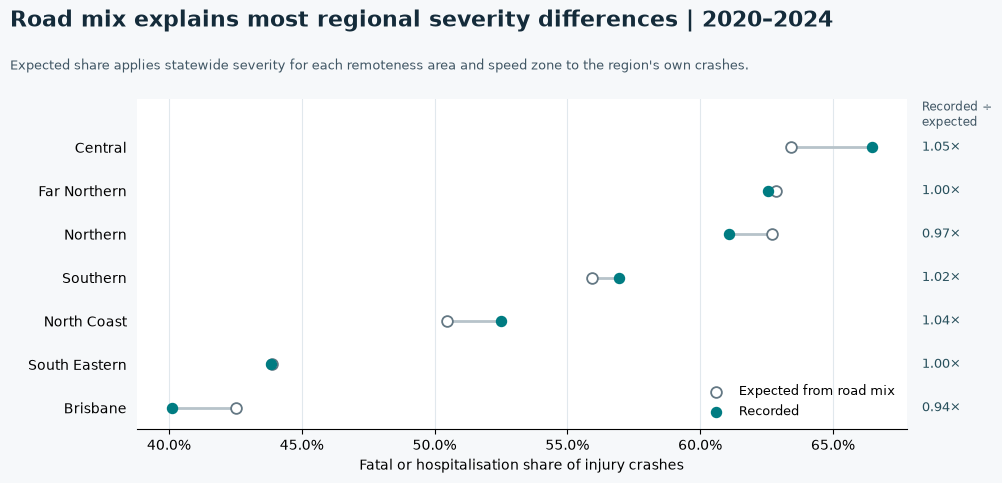

In [15]:
# `wilson_interval` is defined in the severity-mix check in Phase 2.


mix_fields = ['Loc_ABS_Remoteness', 'Crash_Speed_Limit']
mix_records = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
].dropna(subset=mix_fields).assign(Serious=lambda frame: frame['Crash_Severity'].isin(severe_labels))
# Each crash's expected chance of a serious outcome is the statewide share for its road setting.
mix_records['Expected'] = mix_records.groupby(mix_fields)['Serious'].transform('mean')
region_mix = mix_records.groupby('Police_Region').agg(
    **{'Injury crashes': ('Serious', 'size'), 'Recorded serious crashes': ('Serious', 'sum'),
       'Expected serious crashes': ('Expected', 'sum')}
)
assert np.isclose(region_mix['Recorded serious crashes'].sum(), region_mix['Expected serious crashes'].sum())
region_mix['Recorded share (%)'] = 100 * region_mix['Recorded serious crashes'] / region_mix['Injury crashes']
region_mix['Expected share from road mix (%)'] = 100 * region_mix['Expected serious crashes'] / region_mix['Injury crashes']
region_mix['Recorded ÷ expected'] = region_mix['Recorded serious crashes'] / region_mix['Expected serious crashes']
# Interval for the ratio: the Wilson interval for the recorded share divided by the expected share.
low, high = wilson_interval(region_mix['Recorded serious crashes'], region_mix['Injury crashes'])
expected_share = region_mix['Expected share from road mix (%)'] / 100
region_mix['Ratio 95% low'], region_mix['Ratio 95% high'] = low / expected_share, high / expected_share
region_mix['Outer regional or remote (%)'] = 100 * mix_records['Loc_ABS_Remoteness'].isin(
    ['Outer Regional', 'Remote', 'Very Remote']).groupby(mix_records['Police_Region']).mean()
region_mix = region_mix.sort_values('Recorded share (%)', ascending=False)
display(region_mix.round({'Expected serious crashes': 0, 'Recorded share (%)': 1,
                          'Expected share from road mix (%)': 1, 'Recorded ÷ expected': 3,
                          'Ratio 95% low': 3, 'Ratio 95% high': 3, 'Outer regional or remote (%)': 1}))
recorded_spread = region_mix['Recorded share (%)'].max() - region_mix['Recorded share (%)'].min()
residual_spread = (region_mix['Recorded share (%)'] - region_mix['Expected share from road mix (%)'])
print(f"Recorded shares span {recorded_spread:.1f} percentage points across regions. "
      f"After allowing for road mix, the gaps range from {residual_spread.min():+.1f} to {residual_spread.max():+.1f} points.")

fig, ax = plt.subplots(figsize=(11, 5), facecolor='#f6f8fa')
fig.subplots_adjust(left=.16, right=.86, bottom=.14, top=.80)
fig.suptitle(f'Road mix explains most regional severity differences | {recent_years.min()}–{recent_years.max()}',
             x=.045, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.045, .86, 'Expected share applies statewide severity for each remoteness area and speed zone to the region\'s own crashes.',
         fontsize=9.5, color='#405664')
positions = np.arange(len(region_mix))
recorded_share, road_mix_share = region_mix['Recorded share (%)'], region_mix['Expected share from road mix (%)']
ax.hlines(positions, np.minimum(recorded_share, road_mix_share), np.maximum(recorded_share, road_mix_share),
          color='#b7c3ca', linewidth=2)
ax.scatter(road_mix_share, positions, facecolor='white', edgecolor='#647884', linewidth=1.3, s=60,
           label='Expected from road mix', zorder=3)
ax.scatter(recorded_share, positions, color='#007c82', s=52, label='Recorded', zorder=4)
for y, (_, row) in zip(positions, region_mix.iterrows()):
    ax.annotate(f"{row['Recorded ÷ expected']:.2f}×", (1.02, y), xycoords=('axes fraction', 'data'),
                va='center', fontsize=9.5, color='#28505c')
ax.annotate('Recorded ÷\nexpected', (1.02, -.75), xycoords=('axes fraction', 'data'), va='center',
            fontsize=8.5, color='#405664', annotation_clip=False)
ax.set(yticks=positions, yticklabels=region_mix.index, ylim=(len(positions) - .5, -1.1),
       xlabel='Fatal or hospitalisation share of injury crashes')
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

**What this achieved.** Recorded serious-crash shares ranged from 40.1% in Brisbane to 66.5% in Central, a spread of 26.4 percentage points. After allowing for each region's mix of remoteness area and speed zone, recorded shares were within −2.4 to +3.0 points of the expected shares, and recorded serious crashes were between 0.94 (Brisbane) and 1.05 (Central) times the expected number. The intervals for Central (1.03–1.07), North Coast (1.02–1.06) and Brisbane (0.93–0.96) exclude 1, so small differences remain. Most of the regional ranking reflects where crashes happen.

#### Crash-level fields that V5 did not analyse

The locations file carries unit counts (cars, motorcycles, trucks, buses, bicycles, pedestrians), crash month, local government area, police district, state electorate and the detailed definitions for classifying accidents (DCA) movement code on every crash. V5 exported these to Tableau but analysed none of them. The four sections below use them on the stable severity window. Each share comes with a Wilson 95% interval.

Per-person rates would need ABS population estimates by SA2 or LGA, which are not in the project folder. The SA2 and LGA codes are ready for that join.

##### Road users and vehicles in each crash

V5 compared motorcycle, truck and bus involvement using the grouped vehicle table, which gives one count per year, region and severity. The unit counts on each crash support the same comparison crash by crash. They also cover pedestrians, cyclists and single-vehicle crashes, which the grouped tables do not. A crash can carry several flags.

**In this cell.** Derive involvement flags from the unit counts. Check the motorcycle, truck and bus flags against the grouped vehicle table. Compare fatal-or-hospitalisation and fatal shares with and without each flag in the stable window.

,Crash-level unit counts,Grouped vehicle table,Difference
Motorcycle or moped,38830,38830,0
Truck,29943,29943,0
Bus,7048,7048,0


Injury crashes  Serious crashes  \
Road user or vehicle          Status                                          
Pedestrian                    Involved                3307             2084   
                              Not involved           63317            31142   
Bicycle                       Involved                3692             1964   
                              Not involved           62932            31262   
Motorcycle or moped           Involved                8022             5805   
                              Not involved           58602            27421   
Truck                         Involved                4482             2378   
                              Not involved           62142            30848   
Bus                           Involved                 934              421   
                              Not involved           65690            32805   
Single vehicle, no pedestrian Involved               16638            11491   
                              Not involved           49986            21735   
Two or more vehicles          Involved               46937            19823   
                              Not involved           19687            13403   

                                            Fatal crashes  \
Road user or vehicle          Status                        
Pedestrian                    Involved                135   
                              Not involved           1169   
Bicycle                       Involved                 38   
                              Not involved           1266   
Motorcycle or moped           Involved                351   
                              Not involved            953   
Truck                         Involved                217   
                              Not involved           1087   
Bus                           Involved                 19   
                              Not involved           1285   
Single vehicle, no pedestrian Involved                578   
                              Not involved            726   
Two or more vehicles          Involved                606   
                              Not involved            698   

                                            Fatal or hospitalisation (%)  \
Road user or vehicle          Status                                       
Pedestrian                    Involved                             63.02   
                              Not involved                         49.18   
Bicycle                       Involved                             53.20   
                              Not involved                         49.68   
Motorcycle or moped           Involved                             72.36   
                              Not involved                         46.79   
Truck                         Involved                             53.06   
                              Not involved                         49.64   
Bus                           Involved                             45.07   
                              Not involved                         49.94   
Single vehicle, no pedestrian Involved                             69.06   
                              Not involved                         43.48   
Two or more vehicles          Involved                             42.23   
                              Not involved                         68.08   

                                            Serious 95% low  Serious 95% high  \
Road user or vehicle          Status                                            
Pedestrian                    Involved                61.36             64.65   
                              Not involved            48.79             49.57   
Bicycle                       Involved                51.58             54.80   
                              Not involved            49.29             50.07   
Motorcycle or moped           Involved                71.37             73.33   
                  

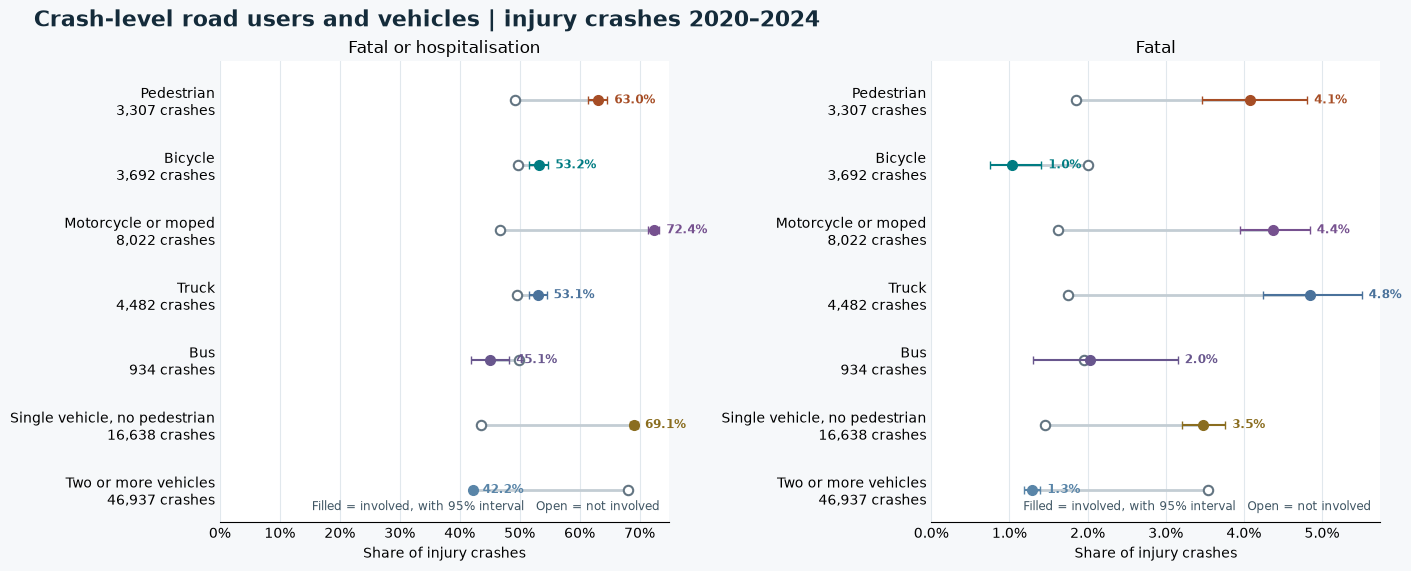

In [16]:
unit_fields = {
    'Pedestrian': 'Count_Unit_Pedestrian', 'Bicycle': 'Count_Unit_Bicycle',
    'Motorcycle or moped': 'Count_Unit_Motorcycle_Moped', 'Truck': 'Count_Unit_Truck', 'Bus': 'Count_Unit_Bus',
    'Car': 'Count_Unit_Car', 'Other unit': 'Count_Unit_Other',
}
vehicle_unit_fields = [field for label, field in unit_fields.items() if label != 'Pedestrian']


def involvement_flags(frame):
    """One True/False column per road user or vehicle type, plus single- and multi-vehicle crashes."""
    units = frame[list(unit_fields.values())].fillna(0)
    vehicles = units[vehicle_unit_fields].sum(axis=1)
    flags = pd.DataFrame({label: units[field].gt(0) for label, field in unit_fields.items()
                          if label not in ('Car', 'Other unit')}, index=frame.index)
    flags['Single vehicle, no pedestrian'] = vehicles.eq(1) & units['Count_Unit_Pedestrian'].eq(0)
    flags['Two or more vehicles'] = vehicles.ge(2)
    return flags


# The crash-level flags should agree with the grouped vehicle table over the whole series.
all_flags = involvement_flags(cleaned)
unit_check = pd.DataFrame({
    kind: {'Crash-level unit counts': int(all_flags[kind].sum()),
           'Grouped vehicle table': int(regional_sources['Vehicles'].loc[
               regional_sources['Vehicles'][flag].eq('Yes'), 'Count_Crashes'].sum())}
    for kind, flag in vehicle_flags.items()
}).T
unit_check['Difference'] = unit_check['Crash-level unit counts'] - unit_check['Grouped vehicle table']
display(unit_check)

window_crashes = cleaned.loc[cleaned['Crash_Severity'].isin(injury_labels) & cleaned['Crash_Year'].isin(stable_years)]
window_flags = involvement_flags(window_crashes)
window_is_serious = window_crashes['Crash_Severity'].isin(severe_labels)
window_is_fatal = window_crashes['Crash_Severity'].eq('Fatal')
window_label = f'{stable_years.min()}–{stable_years.max()}'
unit_rows = []
for label in window_flags:
    for status, mask in [('Involved', window_flags[label]), ('Not involved', ~window_flags[label])]:
        crashes, serious, fatal = int(mask.sum()), int(window_is_serious[mask].sum()), int(window_is_fatal[mask].sum())
        serious_low, serious_high = wilson_interval(serious, crashes)
        fatal_low, fatal_high = wilson_interval(fatal, crashes)
        unit_rows.append({
            'Road user or vehicle': label, 'Status': status, 'Injury crashes': crashes,
            'Serious crashes': serious, 'Fatal crashes': fatal,
            'Fatal or hospitalisation (%)': 100 * serious / crashes,
            'Serious 95% low': 100 * serious_low, 'Serious 95% high': 100 * serious_high,
            'Fatal (%)': 100 * fatal / crashes, 'Fatal 95% low': 100 * fatal_low, 'Fatal 95% high': 100 * fatal_high,
        })
unit_involvement = pd.DataFrame(unit_rows).set_index(['Road user or vehicle', 'Status'])
display(unit_involvement.round(2))

unit_order = list(window_flags.columns)
unit_colors = dict(zip(unit_order, ['#a64d25', '#007c82', '#76518f', '#4a729b', '#68568d', '#8a6d1f', '#5985a8']))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Crash-level road users and vehicles | injury crashes {window_label}', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
for ax, share, low, high, title in [
    (axes[0], 'Fatal or hospitalisation (%)', 'Serious 95% low', 'Serious 95% high', 'Fatal or hospitalisation'),
    (axes[1], 'Fatal (%)', 'Fatal 95% low', 'Fatal 95% high', 'Fatal'),
]:
    for y, label in enumerate(unit_order):
        involved, absent = unit_involvement.loc[(label, 'Involved')], unit_involvement.loc[(label, 'Not involved')]
        ax.hlines(y, min(involved[share], absent[share]), max(involved[share], absent[share]), color='#c3cdd4', lw=2)
        ax.errorbar(involved[share], y, xerr=[[involved[share] - involved[low]], [involved[high] - involved[share]]],
                    fmt='o', color=unit_colors[label], ms=7, capsize=3, zorder=4)
        ax.scatter(absent[share], y, s=46, facecolor='white', edgecolor='#637582', linewidth=1.5, zorder=3)
        ax.annotate(f"{involved[share]:.1f}%", (involved[high], y), xytext=(5, 0), textcoords='offset points',
                    va='center', fontsize=8.5, color=unit_colors[label], fontweight='bold')
    ax.set(yticks=range(len(unit_order)),
           yticklabels=[f"{label}\n{unit_involvement.loc[(label, 'Involved'), 'Injury crashes']:,} crashes"
                        for label in unit_order],
           ylim=(len(unit_order) - .5, -.6), title=title, xlabel='Share of injury crashes')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.set_xlim(0, None)
    ax.text(.98, .02, 'Filled = involved, with 95% interval   Open = not involved', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=8.5, color='#405664')
    ax.grid(axis='x', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(length=0)
plt.show()

**What this achieved.** The crash-level unit counts reproduce the grouped vehicle table exactly for motorcycles (38,830 crashes), trucks (29,943) and buses (7,048), so crash-level analysis loses nothing. In 2020–2024:
- **Pedestrian** crashes (3,307) had a fatal share of 4.08% (95% interval 3.46–4.81%), more than twice the 1.85% for other crashes, and 63.0% were serious.
- **Motorcycle** crashes had the highest serious share (72.4%) and a 4.38% fatal share. **Truck** crashes had the highest fatal share (4.84%) despite a near-average serious share (53.1%).
- **Single-vehicle** crashes with no pedestrian were 25% of injury crashes and 44% of fatal crashes (578 of 1,304), with a 3.47% fatal share against 1.29% for multi-vehicle crashes.
- **Bicycle** crashes were more often serious (53.2% against 49.7%) but less often fatal (1.03% against 2.01%).

##### Seasonality by month

Monthly counts depend on the number of days in the month, so the counts are converted to crashes per day. Each year's months are then indexed to that year's average daily rate, which removes the slow change in annual totals and leaves the seasonal shape. The serious and fatal shares by month use the stable window.

**In this cell.** Count injury crashes by year and month for complete years and divide by days in month. Index each month to its year's mean and draw a year-by-month heatmap. Then plot serious and fatal shares by month for the stable window with 95% intervals.

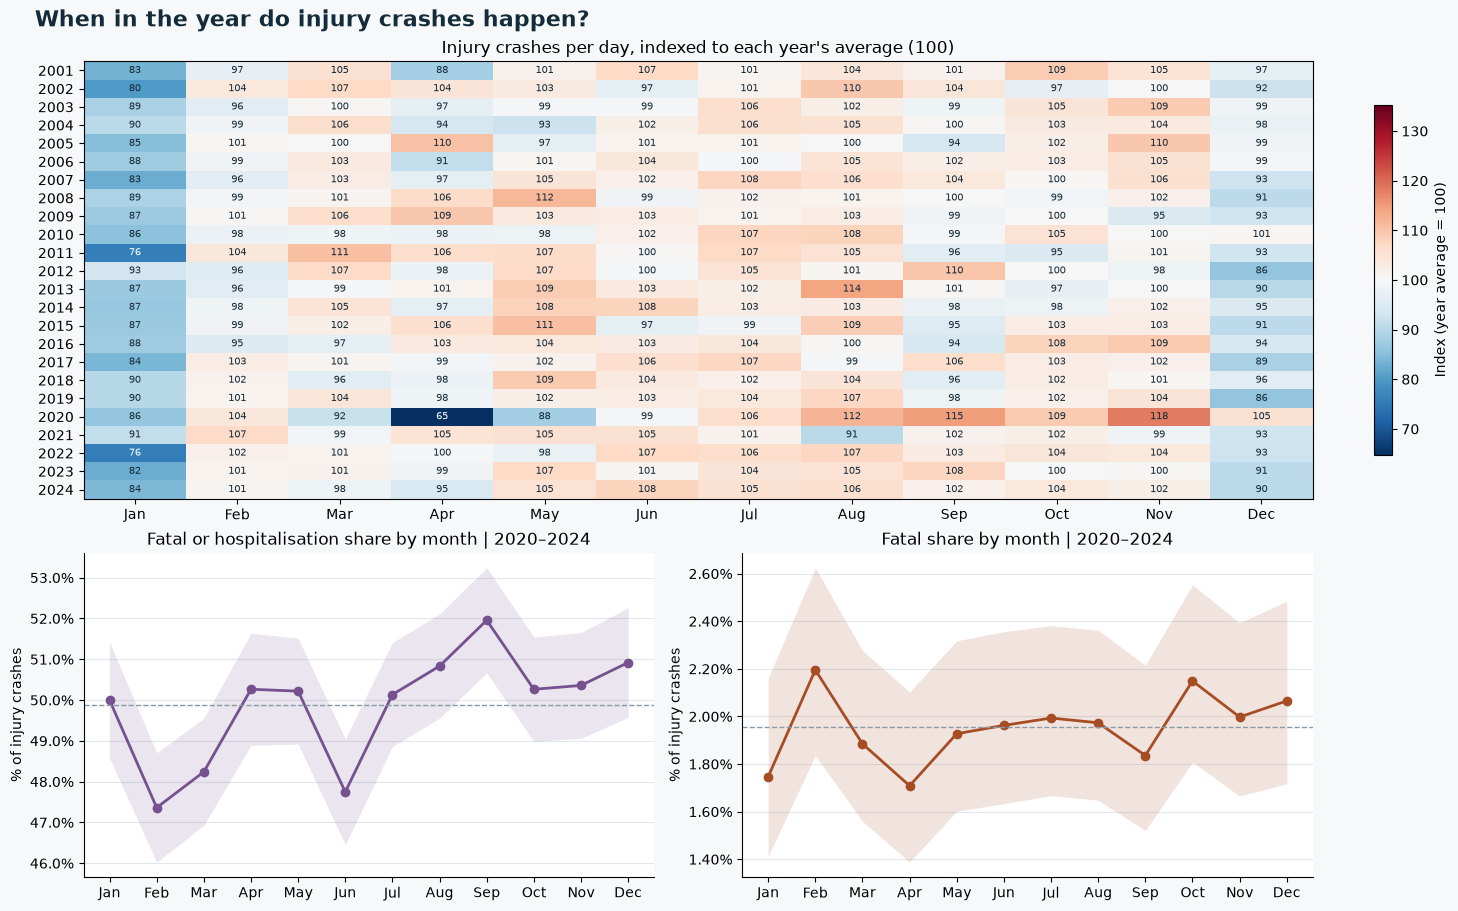

Crash_Month,January,February,March,April,May,June,July,August,September,October,November,December
Mean seasonal index,85.9,99.9,101.8,98.5,103.0,102.5,103.7,104.5,101.1,102.0,103.2,93.9
Lowest year,75.7,95.1,92.0,64.8,87.7,96.6,98.9,90.6,94.0,94.8,94.9,86.0
Highest year,93.2,106.8,110.7,110.2,111.6,107.9,107.6,113.9,114.8,109.1,118.4,105.2


,Crashes,Serious,Fatal,Fatal or hospitalisation (%),Fatal or hospitalisation 95% low,Fatal or hospitalisation 95% high,Fatal (%),Fatal 95% low,Fatal 95% high
Crash_Month,,,,,,,,,
January,4752,2376,83,50.00,48.58,51.42,1.75,1.41,2.16
February,5329,2524,117,47.36,46.03,48.71,2.20,1.84,2.62
March,5570,2687,105,48.24,46.93,49.55,1.89,1.56,2.28
April,5091,2559,87,50.27,48.89,51.64,1.71,1.39,2.10
May,5707,2866,110,50.22,48.92,51.52,1.93,1.60,2.32
June,5707,2725,112,47.75,46.45,49.05,1.96,1.63,2.36
July,5920,2968,118,50.14,48.86,51.41,1.99,1.67,2.38
August,5878,2988,116,50.83,49.56,52.11,1.97,1.65,2.36
September,5774,3000,106,51.96,50.67,53.24,1.84,1.52,2.22


Busiest month on average: August (index 104); quietest: January (86). Lowest single month: April 2020 (index 65).


In [17]:
import calendar

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September',
               'October', 'November', 'December']
monthly_injury = cleaned.loc[cleaned['Crash_Severity'].isin(injury_labels) & cleaned['Crash_Year'].isin(complete_years)]
month_year = pd.crosstab(monthly_injury['Crash_Year'], monthly_injury['Crash_Month']).reindex(columns=month_order)
days_in_month = pd.DataFrame([[calendar.monthrange(int(year), month)[1] for month in range(1, 13)]
                              for year in month_year.index], index=month_year.index, columns=month_order)
daily_rate = month_year / days_in_month
seasonal_index = daily_rate.div(daily_rate.mean(axis=1), axis=0).mul(100)
assert month_year.to_numpy().sum() == len(monthly_injury)

window_month = window_crashes.groupby('Crash_Month').agg(
    Crashes=('Crash_Severity', 'size'),
    Serious=('Crash_Severity', lambda values: int(values.isin(severe_labels).sum())),
    Fatal=('Crash_Severity', lambda values: int(values.eq('Fatal').sum())),
).reindex(month_order)
for column, label in [('Serious', 'Fatal or hospitalisation'), ('Fatal', 'Fatal')]:
    low, high = wilson_interval(window_month[column], window_month['Crashes'])
    window_month[f'{label} (%)'] = 100 * window_month[column] / window_month['Crashes']
    window_month[f'{label} 95% low'], window_month[f'{label} 95% high'] = 100 * low, 100 * high

fig = plt.figure(figsize=(14.5, 9), layout='constrained', facecolor='#f6f8fa')
grid = fig.add_gridspec(2, 2, height_ratios=[1.35, 1])
heat = fig.add_subplot(grid[0, :])
share_axes = [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
fig.suptitle('When in the year do injury crashes happen?', x=.02, ha='left', fontsize=16, fontweight='bold',
             color='#142b3a')
limit = float(np.nanmax(np.abs(seasonal_index.to_numpy() - 100)))
image = heat.imshow(seasonal_index, cmap='RdBu_r', vmin=100 - limit, vmax=100 + limit, aspect='auto')
heat.set(xticks=range(12), xticklabels=[name[:3] for name in month_order], yticks=range(len(seasonal_index)),
         yticklabels=seasonal_index.index, title='Injury crashes per day, indexed to each year\'s average (100)')
for row, col in np.ndindex(seasonal_index.shape):
    value = seasonal_index.iat[row, col]
    heat.text(col, row, f'{value:.0f}', ha='center', va='center', fontsize=7,
              color='white' if abs(value - 100) > limit * .6 else '#172b38')
fig.colorbar(image, ax=heat, label='Index (year average = 100)', shrink=.8)
for ax, label, color in [(share_axes[0], 'Fatal or hospitalisation', '#76518f'), (share_axes[1], 'Fatal', '#a64d25')]:
    x = np.arange(12)
    ax.fill_between(x, window_month[f'{label} 95% low'], window_month[f'{label} 95% high'], color=color, alpha=.15, lw=0)
    ax.plot(x, window_month[f'{label} (%)'], color=color, marker='o', lw=2)
    ax.axhline(100 * (window_month['Serious' if label != 'Fatal' else 'Fatal'].sum() / window_month['Crashes'].sum()),
               color='#879aa5', ls='--', lw=1)
    ax.set(xticks=x, xticklabels=[name[:3] for name in month_order], ylabel='% of injury crashes',
           title=f'{label} share by month | {window_label}')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

mean_index = seasonal_index.mean()
display(pd.DataFrame({'Mean seasonal index': mean_index, 'Lowest year': seasonal_index.min(),
                      'Highest year': seasonal_index.max()}).round(1).T)
display(window_month.round(2))
lowest_cell = seasonal_index.stack().idxmin()
print(f"Busiest month on average: {mean_index.idxmax()} (index {mean_index.max():.0f}); quietest: "
      f"{mean_index.idxmin()} ({mean_index.min():.0f}). Lowest single month: {lowest_cell[1]} {lowest_cell[0]} "
      f"(index {seasonal_index.stack().min():.0f}).")

**What this achieved.** Injury crashes per day are lowest in January (index 86) and December (94), the holiday months, and highest in August (104). The rest of the year sits within ±4 of the average. The lowest single month in the series is April 2020 (index 65), the first COVID-19 restriction period. In 2020–2024 the serious share by month stayed within about 47–52% and the fatal share within 1.7–2.2%. Every interval overlaps, so the data show a seasonal pattern in volume but not in severity.

##### Local areas compared with their road mix: funnel plots

The road-mix comparison above found that most of the regional difference in severity follows where the crashes happen. The same indirect standardisation works for council areas, police districts and state electorates. Each crash's expected chance of a serious outcome is the stable-window statewide share for its remoteness area and speed zone. An area's ratio is its recorded serious crashes divided by the sum of those expectations.

A funnel plot shows each ratio against the expected count, with 95% and 99.8% limits that narrow as areas get larger. Points outside the 99.8% limits are unlikely to reflect chance alone. Small areas cannot reach the top of the list through noise, which a ranked table allows. Council names are aligned for the Region/Regional suffix and the Moreton Bay change.

**In this cell.** Compute expected serious crashes by remoteness area and speed zone for the stable window. Sum observed and expected crashes by council area, police district and state electorate. Draw a funnel plot for each and list the areas outside the 99.8% limits.

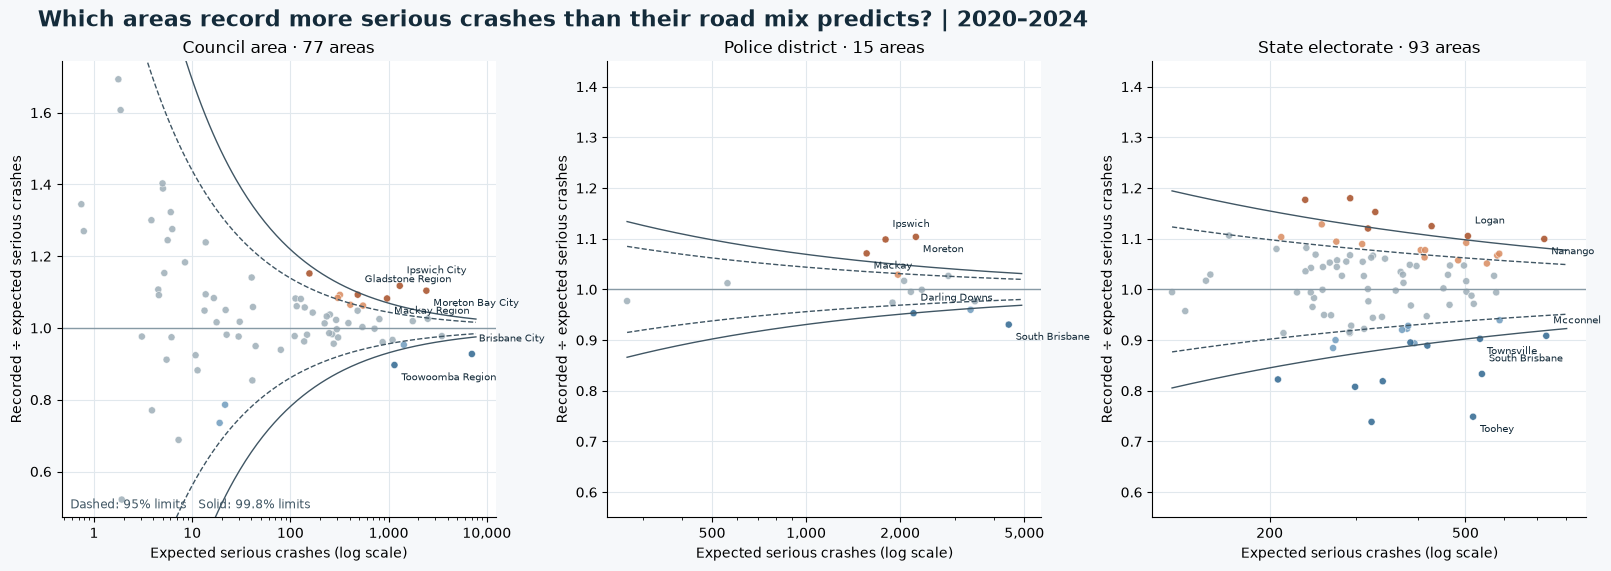

Funnel band,Above 95% limit,Above 99.8% limit,Below 95% limit,Below 99.8% limit,Within 95% limits
Area type,,,,,
Council area,4,5,3,2,63
Police district,1,3,1,2,8
State electorate,12,7,7,10,57


Injury crashes  Serious crashes  \
Area type        Area                                                
Council area     Moreton Bay City            5471             2677   
Police district  Moreton                     5010             2480   
                 Ipswich                     3774             1974   
Council area     Ipswich City                2979             1451   
Police district  Mackay                      2429             1674   
State electorate Nanango                     1100              795   
Council area     Mackay Region               1567             1044   
State electorate Ipswich                      701              344   
                 Morayfield                   782              378   
                 Redcliffe                    565              278   
                 Bundamba                    1015              480   
                 Gladstone                    535              355   
Council area     Gladstone Region             778              530   
State electorate Logan                       1033              559   
Council area     Burdekin Shire               243              180   
State electorate Mcconnel                    1723              663   
                 Mount Ommaney                482              171   
                 Bundaberg                    741              372   
                 Condamine                    604              346   
                 Townsville                   912              483   
Police district  Darling Downs               3581             2105   
State electorate Stretton                     798              278   
                 Toowoomba South              532              241   
                 South Brisbane              1271              450   
Council area     Toowoomba Region            1932             1029   
Police district  South Brisbane             10468             4148   
State electorate Burleigh                     744              238   
                 Toohey                      1238              388   
Council area     Brisbane City              16662             6535   

                                   Expected serious  Variance  \
Area type        Area                                           
Council area     Moreton Bay City           2424.93   1329.96   
Police district  Moreton                    2247.00   1214.16   
                 Ipswich                    1796.87    902.52   
Council area     Ipswich City               1298.36    721.28   
Police district  Mackay                     1562.92    538.03   
State electorate Nanango                     723.02    242.85   
Council area     Mackay Region               964.68    361.56   
State electorate Ipswich                     291.56    170.15   
                 Morayfield                  327.91    190.12   
                 Redcliffe                   236.23    136.96   
                 Bundamba                    426.74    246.92   
                 Gladstone                   316.90    126.92   
Council area     Gladstone Region            485.01    177.56   
State electorate Logan                       505.70    251.03   
Council area     Burdekin Shire              156.25     54.32   
State electorate Mcconnel                    729.81    420.01   
                 Mount Ommaney               207.93    117.68   
                 Bundaberg                   418.35    181.39   
                 Condamine                   386.44    137.49   
                 Townsville                  535.14    220.02   
Police district  Darling Downs              2208.52    830.06   
State electorate Stretton                    339.51    194.57   
                 Toowoomba South             298.33    130.93   
                 South Brisbane              540.03    309.72   
Council area     Toowoomba Region           1147.44    459.81   
Police district  South Brisbane             4457.26   2549.32   
State electorate Burleigh                   

In [18]:
FUNNEL_Z = {'95%': 1.959964, '99.8%': 3.090232}
strata_fields = ['Loc_ABS_Remoteness', 'Crash_Speed_Limit']
area_records = window_crashes.dropna(subset=strata_fields).assign(
    Serious=lambda frame: frame['Crash_Severity'].isin(severe_labels),
    **{'Council area': lambda frame: council_name(frame['Loc_Local_Government_Area'].astype('string')).str.title(),
       'Police district': lambda frame: frame['Loc_Police_District'],
       'State electorate': lambda frame: frame['Loc_State_Electorate']},
)
area_records['Expected'] = area_records.groupby(strata_fields)['Serious'].transform('mean')
area_records['Variance'] = area_records['Expected'] * (1 - area_records['Expected'])
statewide_serious = area_records['Serious'].mean()


def area_funnel(field):
    table = area_records.groupby(field).agg(**{
        'Injury crashes': ('Serious', 'size'), 'Serious crashes': ('Serious', 'sum'),
        'Expected serious': ('Expected', 'sum'), 'Variance': ('Variance', 'sum'),
    })
    table = table.loc[[not missing(name) for name in table.index]]
    table['Recorded ÷ expected'] = table['Serious crashes'] / table['Expected serious']
    table['z'] = (table['Serious crashes'] - table['Expected serious']) / np.sqrt(table['Variance'])
    table['Funnel band'] = np.select(
        [table['z'].gt(FUNNEL_Z['99.8%']), table['z'].gt(FUNNEL_Z['95%']),
         table['z'].lt(-FUNNEL_Z['99.8%']), table['z'].lt(-FUNNEL_Z['95%'])],
        ['Above 99.8% limit', 'Above 95% limit', 'Below 99.8% limit', 'Below 95% limit'], 'Within 95% limits')
    return table.rename_axis('Area')


area_fields = ['Council area', 'Police district', 'State electorate']
area_funnels = {field: area_funnel(field) for field in area_fields}
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Which areas record more serious crashes than their road mix predicts? | {window_label}',
             x=.02, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
band_colors = {'Above 99.8% limit': '#a64d25', 'Above 95% limit': '#d98b5f', 'Within 95% limits': '#9eaeb8',
               'Below 95% limit': '#6f9bbd', 'Below 99.8% limit': '#2f6690'}
for ax, field in zip(axes, area_fields):
    table = area_funnels[field]
    expected_grid = np.geomspace(max(table['Expected serious'].min(), 1), table['Expected serious'].max() * 1.1, 200)
    for label, z in FUNNEL_Z.items():
        spread = z * np.sqrt(expected_grid * (1 - statewide_serious)) / expected_grid
        ax.plot(expected_grid, 1 + spread, color='#405664', lw=1, ls='--' if label == '95%' else '-')
        ax.plot(expected_grid, 1 - spread, color='#405664', lw=1, ls='--' if label == '95%' else '-')
    ax.axhline(1, color='#879aa5', lw=1)
    ax.scatter(table['Expected serious'], table['Recorded ÷ expected'], s=26, alpha=.85, edgecolor='white',
               linewidth=.4, color=table['Funnel band'].map(band_colors))
    labelled = table.loc[table['z'].abs().gt(FUNNEL_Z['99.8%'])].nlargest(6, 'Expected serious')
    for position, (name, row) in enumerate(labelled.sort_values('Recorded ÷ expected').iterrows()):
        ax.annotate(name, (row['Expected serious'], row['Recorded ÷ expected']), xytext=(5, 9 if position % 2 else -11),
                    textcoords='offset points', fontsize=7.5, color='#142b3a')
    ratio = table['Recorded ÷ expected']
    ax.set(xscale='log', title=f'{field} · {len(table)} areas', xlabel='Expected serious crashes (log scale)',
           ylabel='Recorded ÷ expected serious crashes',
           ylim=(max(0, min(.6, ratio.min()) - .05), max(1.4, ratio.max()) + .05))
    decades = np.log10(expected_grid.max() / expected_grid.min())
    ax.xaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5) if decades < 2 else (1,)))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f'{value:,g}'))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.grid(color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].text(.02, .02, 'Dashed: 95% limits   Solid: 99.8% limits', transform=axes[0].transAxes, fontsize=8.5,
             color='#405664')
plt.show()

area_funnel_table = pd.concat(area_funnels, names=['Area type'])
outside = area_funnel_table.loc[area_funnel_table['z'].abs().gt(FUNNEL_Z['99.8%'])]
display(area_funnel_table.groupby('Area type')['Funnel band'].value_counts().unstack(fill_value=0))
display(outside.sort_values('z', ascending=False).round(2))

**What this achieved.** After allowing for remoteness and speed zone, most areas sit within the funnel. Five council areas lie above the 99.8% limit: Moreton Bay City (recorded ÷ expected 1.10), Ipswich City (1.12), Mackay Region (1.08), Gladstone Region (1.09) and Burdekin Shire (1.15). The matching police districts are Moreton, Ipswich and Mackay. Brisbane City (0.93) and Toowoomba Region (0.90) lie below the 99.8% limit. Among state electorates, Ipswich, Redcliffe, Morayfield and Nanango are above the limit, while Toohey, Burleigh and Toowoomba South are well below. These are differences in recorded severity after road mix. They could reflect local road design, enforcement, travel patterns, or local differences in how injuries are graded, so treat them as places to investigate rather than rankings.

##### Detailed movement codes

Crash nature has 15 categories and the DCA group has 22. The DCA description has 89, and distinguishes for example a vehicle leaving the carriageway on a curve from one leaving it on a straight. Ranking the codes by fatal crashes and fatal share shows which movements to target with road design.

**In this cell.** Count injury, serious and fatal crashes by DCA description in the stable window. Add Wilson 95% intervals to the fatal share and plot the 15 codes with the most fatal crashes.

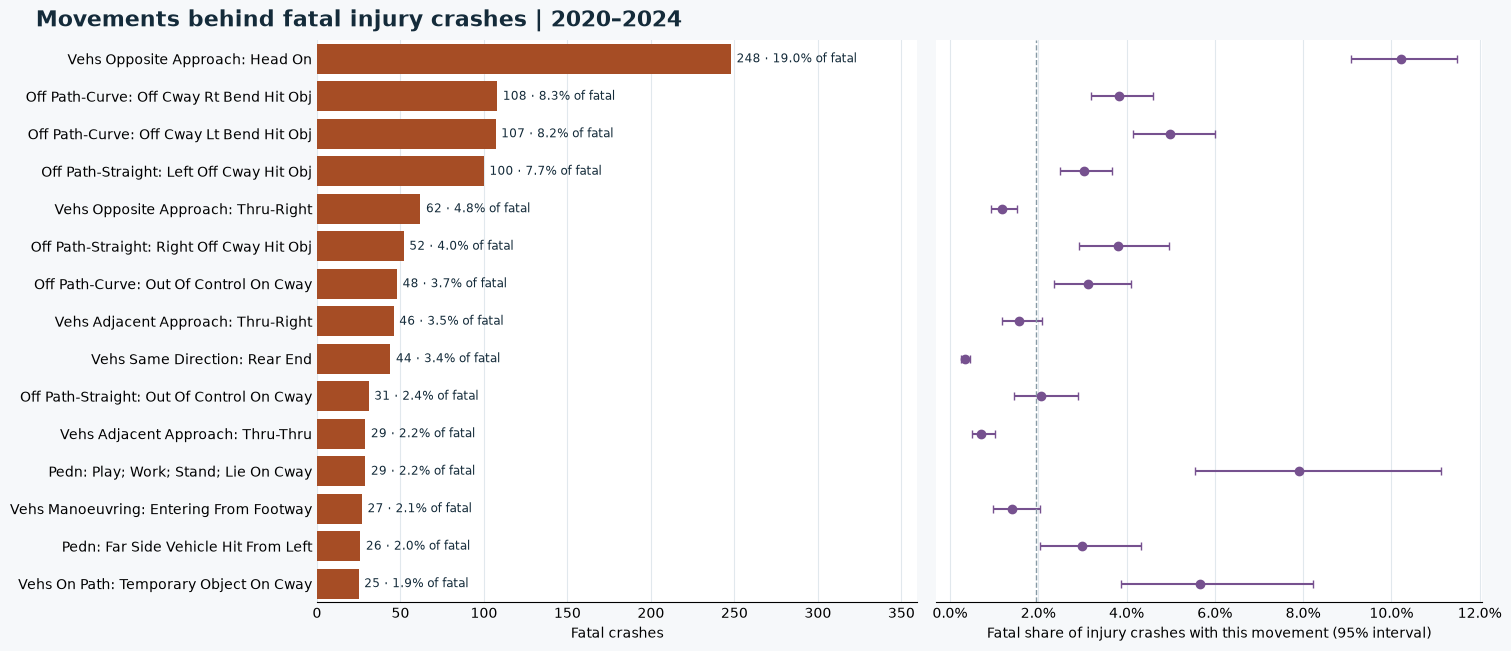

,Injury crashes,Serious crashes,Fatal crashes,Fatal (%),Fatal 95% low,Fatal 95% high,Fatal or hospitalisation (%),Share of all fatal crashes (%)
Crash_DCA_Description,,,,,,,,
Vehs Opposite Approach: Head On,2426,1702,248,10.22,9.08,11.49,70.16,19.02
Off Path-Curve: Off Cway Rt Bend Hit Obj,2817,1976,108,3.83,3.19,4.61,70.15,8.28
Off Path-Curve: Off Cway Lt Bend Hit Obj,2143,1470,107,4.99,4.15,6.00,68.60,8.21
Off Path-Straight: Left Off Cway Hit Obj,3294,2191,100,3.04,2.50,3.68,66.51,7.67
Vehs Opposite Approach: Thru-Right,5211,2718,62,1.19,0.93,1.52,52.16,4.75
Off Path-Straight: Right Off Cway Hit Obj,1365,968,52,3.81,2.92,4.96,70.92,3.99
Off Path-Curve: Out Of Control On Cway,1539,1072,48,3.12,2.36,4.11,69.66,3.68
Vehs Adjacent Approach: Thru-Right,2925,1529,46,1.57,1.18,2.09,52.27,3.53
Vehs Same Direction: Rear End,13117,3599,44,0.34,0.25,0.45,27.44,3.37


In [19]:
dca_table = window_crashes.groupby('Crash_DCA_Description').agg(**{
    'Injury crashes': ('Crash_Severity', 'size'),
    'Serious crashes': ('Crash_Severity', lambda values: int(values.isin(severe_labels).sum())),
    'Fatal crashes': ('Crash_Severity', lambda values: int(values.eq('Fatal').sum())),
})
dca_table['Fatal (%)'] = 100 * dca_table['Fatal crashes'] / dca_table['Injury crashes']
dca_low, dca_high = wilson_interval(dca_table['Fatal crashes'], dca_table['Injury crashes'])
dca_table['Fatal 95% low'], dca_table['Fatal 95% high'] = 100 * dca_low, 100 * dca_high
dca_table['Fatal or hospitalisation (%)'] = 100 * dca_table['Serious crashes'] / dca_table['Injury crashes']
dca_table['Share of all fatal crashes (%)'] = 100 * dca_table['Fatal crashes'] / dca_table['Fatal crashes'].sum()
dca_table = dca_table.sort_values(['Fatal crashes', 'Injury crashes'], ascending=False)
dca_top = dca_table.head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.4), layout='constrained', facecolor='#f6f8fa', sharey=True,
                         gridspec_kw={'width_ratios': [1.1, 1]})
fig.suptitle(f'Movements behind fatal injury crashes | {window_label}', x=.02, ha='left', fontsize=16,
             fontweight='bold', color='#142b3a')
y = np.arange(len(dca_top))
axes[0].barh(y, dca_top['Fatal crashes'], color='#a64d25')
for position, (count, share) in enumerate(zip(dca_top['Fatal crashes'], dca_top['Share of all fatal crashes (%)'])):
    axes[0].annotate(f'{count:,} · {share:.1f}% of fatal', (count, position), xytext=(4, 0), textcoords='offset points',
                     va='center', fontsize=8.5, color='#142b3a')
axes[0].set(yticks=y, yticklabels=dca_top.index, ylim=(len(dca_top) - .5, -.5), xlabel='Fatal crashes',
            xlim=(0, dca_top['Fatal crashes'].max() * 1.45))
axes[1].errorbar(dca_top['Fatal (%)'], y, xerr=[dca_top['Fatal (%)'] - dca_top['Fatal 95% low'],
                                                dca_top['Fatal 95% high'] - dca_top['Fatal (%)']],
                 fmt='o', color='#76518f', capsize=3)
axes[1].axvline(100 * window_is_fatal.mean(), color='#879aa5', ls='--', lw=1)
axes[1].set(xlabel='Fatal share of injury crashes with this movement (95% interval)')
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
for ax in axes:
    ax.grid(axis='x', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(length=0)
plt.show()
display(dca_top.round(2))

**What this achieved.** Head-on crashes were 3.6% of injury crashes but 19.0% of fatal crashes in 2020–2024 (248 fatal, a 10.2% fatal share). The next three codes are run-off-road movements: off carriageway on a right bend (108 fatal), on a left bend (107) and off a straight to the left (100). Together these account for another 24% of fatal crashes, each with a fatal share of 3–5%. Rear-end crashes are the most common injury crash (13,117) but have the lowest fatal share of the 15 codes shown (0.34%). Pedestrians struck while on the carriageway (playing, working, standing or lying) had a 7.9% fatal share. These movement codes point to specific treatments: barriers, delineation and curve warnings for run-off-road, and median separation for head-on crashes.

#### Export a flat file for casualty, restraint, driver and crash context

The CSV has one row per **crash year and police region**. Each set of columns is calculated from its own source before joining. The casualty and restraint files can be checked at a finer shared level using age group, recorded gender, road-user type, injury severity, year, and region. Road casualties reports drivers and passengers separately. The restraint file groups them as vehicle occupants.

The column prefixes identify their units and source:

- `casualty_` counts casualties from Road casualties, including separate driver and passenger totals by recorded gender.
- `seatbelt_`, `bicycle_helmet_`, and `motorcycle_helmet_` count casualties by equipment status and recorded gender from the restraint file. Columns ending in `_fatalities` count only fatalities within that category. Unknown and inapplicable status have their own columns.
- `driver_` and `factor_` count crashes with a reported flag from their respective files. A crash can meet more than one flag.
- `weather_` counts crashes and people killed by the atmospheric condition recorded in Road crash locations. Weather totals are available for the region and year as a whole.

A zero means the source reports the group and no records meet the condition. A blank means the source lacks that year-region group. Pool counts before calculating percentages. This dataset supports restraint-by-gender analysis among vehicle-occupant casualties and weather-by-fatality analysis overall. The files contain no joint breakdown linking gender, restraint status, and weather for the same casualty.

**In this cell.** Reconcile the casualty and restraint files by year, region, age, gender, road user, and injury severity. Aggregate the aligned data and the separate driver, crash-factor, and weather measures into a flat year–region export.

In [20]:
# Sum a count column under several named conditions for each year and police region.
def count_flows_by_region(frame, value_column, masks):
    measures = pd.DataFrame({
        name: frame[value_column].where(mask, 0) for name, mask in masks.items()
    }, index=frame.index)
    return measures.groupby([frame[key] for key in group_fields], dropna=False).sum(min_count=1)


casualty_source = regional_sources['Casualties']
equipment_source = regional_sources['Restraints']
road_user_column = 'Casualty_Road_User_Type'
# Treat drivers and passengers as vehicle occupants so the two casualty files share road-user categories.
casualty_for_alignment = casualty_source.rename(columns={'Casualty_RoadUserType': road_user_column}).copy()
casualty_for_alignment[road_user_column] = casualty_for_alignment[road_user_column].replace(
    {'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'}
)
equipment_users = equipment_source[road_user_column].unique()
detail_key = [*group_fields, 'Casualty_AgeGroup', 'Casualty_Gender', road_user_column, 'Casualty_Severity']
casualty_equipment_detail = pd.concat({
    'Road casualties': casualty_for_alignment.loc[casualty_for_alignment[road_user_column].isin(equipment_users)]
        .groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
    'Restraint and helmet records': equipment_source.groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
}, axis=1).sort_index().astype('Int64')
detail_matches = casualty_equipment_detail['Road casualties'].fillna(0).eq(
    casualty_equipment_detail['Restraint and helmet records'].fillna(0)
)
print(f'Detailed casualty/equipment reconciliation: {int(detail_matches.sum()):,} of {len(detail_matches):,} groups match.')

gender_groups = ['Female', 'Male', 'Unknown']
any_casualty = casualty_source['Casualty_Count'].notna()
fatal_casualty = casualty_source['Casualty_Severity'].eq('Fatality')
casualty_masks = {'casualty_total': any_casualty, 'casualty_fatalities': fatal_casualty}
for gender in gender_groups:
    group = casualty_source['Casualty_Gender'].eq(gender)
    casualty_masks[f'casualty_{gender.lower()}_total'] = group
    casualty_masks[f'casualty_{gender.lower()}_fatalities'] = group & fatal_casualty
    for user in ['Driver', 'Passenger', 'Pedestrian', 'Bicyclist', 'Motorcyclist', 'Other']:
        belongs = group & casualty_source['Casualty_RoadUserType'].eq(user)
        prefix = f'casualty_{gender.lower()}_{user.lower()}'
        casualty_masks[f'{prefix}_total'] = belongs
        casualty_masks[f'{prefix}_fatalities'] = belongs & fatal_casualty
casualty_by_region = count_flows_by_region(casualty_source, 'Casualty_Count', casualty_masks)

seatbelt_labels = {
    'Restrained': 'restrained', 'Unrestrained': 'unrestrained',
    'Restraint Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
helmet_labels = {
    'Helmet Worn': 'worn', 'Helmet Not Worn': 'not_worn',
    'Helmet Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
equipment_masks = {}
equipment_fatal = equipment_source['Casualty_Severity'].eq('Fatality')
for road_user_type, prefix, labels in [
    ('Vehicle Occupant', 'seatbelt', seatbelt_labels),
    ('Bicyclist', 'bicycle_helmet', helmet_labels),
    ('Motorcyclist', 'motorcycle_helmet', helmet_labels),
]:
    for gender in gender_groups:
        group = equipment_source[road_user_column].eq(road_user_type) & equipment_source['Casualty_Gender'].eq(gender)
        equipment_masks[f'{prefix}_{gender.lower()}_total'] = group
        for reported, name in labels.items():
            state = group & equipment_source['Casualty_Restraint_Helmet_Use'].eq(reported)
            column = f'{prefix}_{gender.lower()}_{name}'
            equipment_masks[column] = state
            equipment_masks[f'{column}_fatalities'] = state & equipment_fatal
equipment_by_region = count_flows_by_region(equipment_source, 'Casualty_Count', equipment_masks)

# Driver and crash-factor flags counted in crashes, each from its own source.
crash_context = []
for source_name, prefix in [('Demographics', 'driver'), ('Factors', 'factor')]:
    frame = regional_sources[source_name]
    masks = {f'{prefix}_total_crashes': frame['Count_Crashes'].notna()}
    for field in frame.columns[frame.columns.str.startswith('Involving_')]:
        name = field.removeprefix('Involving_').lower().replace('-', '_')
        flagged = frame[field].eq('Yes')
        masks[f'{prefix}_{name}_crashes'] = flagged
        masks[f'{prefix}_{name}_fatal_crashes'] = flagged & frame['Crash_Severity'].eq('Fatal')
    crash_context.append(count_flows_by_region(frame, 'Count_Crashes', masks))

# Weather counts come from the crash-level file: crashes and people killed by atmospheric condition.
weather_source = regional_sources['Locations'].assign(One_Crash=1)
weather_masks = {'weather_total_crashes': weather_source['One_Crash'].eq(1)}
weather_fatality_masks = {'weather_total_fatalities': weather_source['One_Crash'].eq(1)}
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    suffix = condition.lower().replace('/', '_').replace(' ', '_')
    in_weather = weather_source['Crash_Atmospheric_Condition'].eq(condition)
    weather_masks[f'weather_{suffix}_crashes'] = in_weather
    weather_masks[f'weather_{suffix}_fatal_crashes'] = in_weather & weather_source['Crash_Severity'].eq('Fatal')
    weather_fatality_masks[f'weather_{suffix}_fatalities'] = in_weather
weather_counts = count_flows_by_region(weather_source, 'One_Crash', weather_masks)
weather_fatalities = count_flows_by_region(weather_source, 'Count_Casualty_Fatality', weather_fatality_masks)

# Join every block on year and police region to form the flat export.
casualty_context_flat = pd.concat([
    casualty_by_region, equipment_by_region, *crash_context, weather_counts, weather_fatalities,
], axis=1).sort_index().astype('Int64')
assert casualty_context_flat.index.is_unique and casualty_context_flat.columns.is_unique
assert casualty_context_flat['casualty_total'].sum() == casualty_source['Casualty_Count'].sum()
assert casualty_context_flat[[column for column in equipment_masks if column.endswith('_total')]].sum().sum() == equipment_source['Casualty_Count'].sum()
assert casualty_context_flat['weather_total_crashes'].sum() == len(raw)
assert casualty_context_flat['weather_total_fatalities'].sum() == raw['Count_Casualty_Fatality'].sum()
casualty_context_flat.insert(0, 'Complete_Year_in_Locations', casualty_context_flat.index.get_level_values('Crash_Year').isin(complete_years))
context_export = DATA_DIR / 'Traffic casualty restraint and crash context V6.csv'
write_csv(casualty_context_flat.reset_index(), context_export)
print(f'Exported {len(casualty_context_flat):,} year-region groups to {context_export.name}.')

Detailed casualty/equipment reconciliation: 23,375 of 23,375 groups match.
Exported 186 year-region groups to Traffic casualty restraint and crash context V6.csv.


**What this achieved.** Reconciled the casualty and equipment tables at their shared demographic grain. All 23,375 comparable groups agree. Exported a 186-row context table with one row per year and police region.

##### Examples the flat file can answer

Compare the share of female or male vehicle-occupant casualties who were unrestrained among those with a known seatbelt status. The same table shows outcomes among fatal casualties. For weather, compare total fatalities and fatalities per 100 recorded crashes across atmospheric conditions, for all people combined. Both examples use the latest five complete crash years.

**In this cell.** Pool the latest five complete years before calculating seatbelt non-use shares by recorded gender. Calculate weather-specific fatality counts and rates separately for all people.

In [21]:
context_recent = casualty_context_flat.loc[
    casualty_context_flat.index.get_level_values('Crash_Year').isin(recent_years)
].drop(columns='Complete_Year_in_Locations')
context_totals = context_recent.sum(min_count=1)
# Pool counts across the window before calculating any share.
belt_examples = []
for gender in ['female', 'male']:
    prefix = f'seatbelt_{gender}'
    fastened = int(context_totals[f'{prefix}_restrained'])
    unfastened = int(context_totals[f'{prefix}_unrestrained'])
    fatal_fastened = int(context_totals[f'{prefix}_restrained_fatalities'])
    fatal_unfastened = int(context_totals[f'{prefix}_unrestrained_fatalities'])
    belt_examples.append({
        'Recorded gender': gender.title(),
        'Occupant casualties with known status': fastened + unfastened,
        'Unrestrained': unfastened,
        'Unrestrained share (%)': 100 * unfastened / (fastened + unfastened),
        'Fatalities with known status': fatal_fastened + fatal_unfastened,
        'Unrestrained fatalities': fatal_unfastened,
        'Unrestrained share of fatalities with known status (%)': 100 * fatal_unfastened / (fatal_fastened + fatal_unfastened),
    })
display(pd.DataFrame(belt_examples).set_index('Recorded gender').round(2))

# Fatalities per 100 recorded crashes for each atmospheric condition.
weather_examples = []
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    field = condition.lower().replace('/', '_').replace(' ', '_')
    crashes = int(context_totals[f'weather_{field}_crashes'])
    deaths = int(context_totals[f'weather_{field}_fatalities'])
    weather_examples.append({
        'Atmospheric condition': condition,
        'Crashes': crashes,
        'Fatalities, all people': deaths,
        'Fatalities per 100 recorded crashes': 100 * deaths / crashes if crashes else np.nan,
    })
display(pd.DataFrame(weather_examples).set_index('Atmospheric condition').sort_values('Crashes', ascending=False).round(2))

,Occupant casualties with known status,Unrestrained,Unrestrained share (%),Fatalities with known status,Unrestrained fatalities,Unrestrained share of fatalities with known status (%)
Recorded gender,,,,,,
Female,31696,778,2.45,232,48,20.69
Male,28440,1116,3.92,464,140,30.17


,Crashes,"Fatalities, all people",Fatalities per 100 recorded crashes
Atmospheric condition,,,
Clear,59763,1264,2.12
Raining,6382,140,2.19
Fog,375,17,4.53
Smoke/Dust,104,3,2.88
Unknown,0,0,NaN


**What this achieved.** Calculated separate restraint and weather examples for 2020–2024. Among female occupant casualties with known restraint status, 778 of 31,696 were unrestrained. Weather counts cover all people in the locations file.

##### Fatalities per 100 casualties by protective equipment, age and road user

A share of fatalities answers "what fraction of the people who died were unrestrained". A fatality rate answers "how often did an unrestrained casualty die". The second question is closer to what a campaign needs. This section calculates fatalities per 100 recorded casualties for each restraint or helmet status, keeping the "not determined" group visible, and then for each age group and road-user type. It pools the latest ten complete years so that the smaller groups have enough casualties.

These are rates among people recorded as casualties. Uninjured occupants are not in the data, and restraint status is likely to be established more thoroughly after a fatal crash, so the gap between restrained and unrestrained occupants overstates the protective effect.

**In this cell.** Sum casualties and fatalities by road-user type and equipment status, and by age group and road-user type, for the latest ten complete years. Convert each to fatalities per 100 casualties with a Wilson 95% interval and plot both views.

Casualties  Fatalities  \
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                           
Vehicle Occupant        Restrained                         112807         956   
                        Restraint Use Not determined        23896         363   
                        Unrestrained                         3651         334   
Motorcyclist            Helmet Worn                         15159         553   
                        Helmet Use Not determined             508           6   
                        Helmet Not Worn                       594          45   
Bicyclist               Helmet Worn                          6069          54   
                        Helmet Use Not determined             541           1   
                        Helmet Not Worn                       881          12   

                                                       Fatalities per 100 casualties  \
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                                  
Vehicle Occupant        Restrained                                              0.85   
                        Restraint Use Not determined                            1.52   
                        Unrestrained                                            9.15   
Motorcyclist            Helmet Worn                                             3.65   
                        Helmet Use Not determined                               1.18   
                        Helmet Not Worn                                         7.58   
Bicyclist               Helmet Worn                                             0.89   
                        Helmet Use Not determined                               0.18   
                        Helmet Not Worn                                         1.36   

                                                       95% low  95% high  
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                     
Vehicle Occupant        Restrained                        0.80      0.90  
                        Restraint Use Not determined      1.37      1.68  
                        Unrestrained                      8.26     10.13  
Motorcyclist            Helmet Worn                       3.36      3.96  
                        Helmet Use Not determined         0.54      2.55  
                        Helmet Not Worn                   5.71      9.99  
Bicyclist               Helmet Worn                       0.68      1.16  
                        Helmet Use Not determined         0.03      1.04  
                        Helmet Not Worn                   0.78      2.37

Vehicle occupants: unrestrained 9.15 and restrained 0.85 fatalities per 100 casualties, a ratio of 10.8. Not determined: 1.52.
Motorcyclists: helmet not worn 7.58 and worn 3.65, a ratio of 2.1.


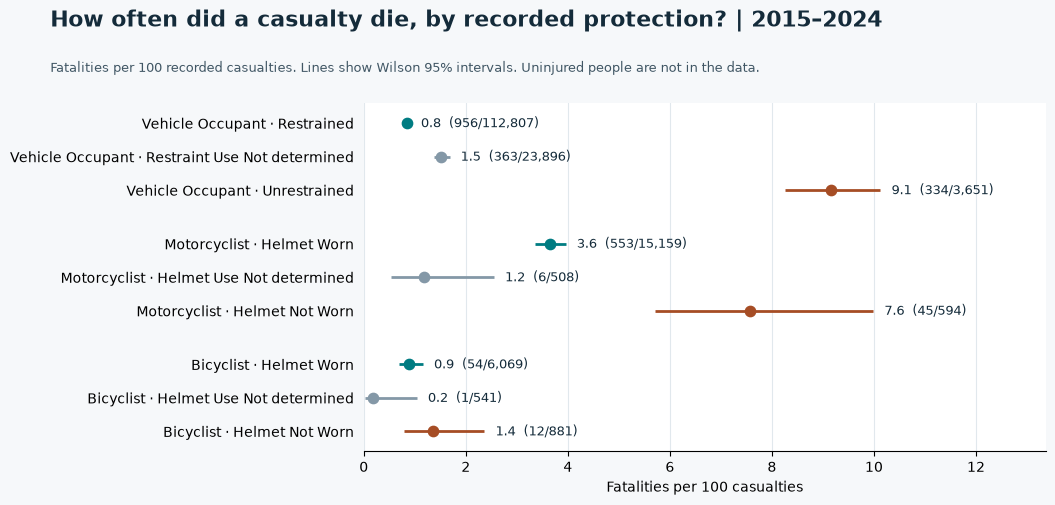

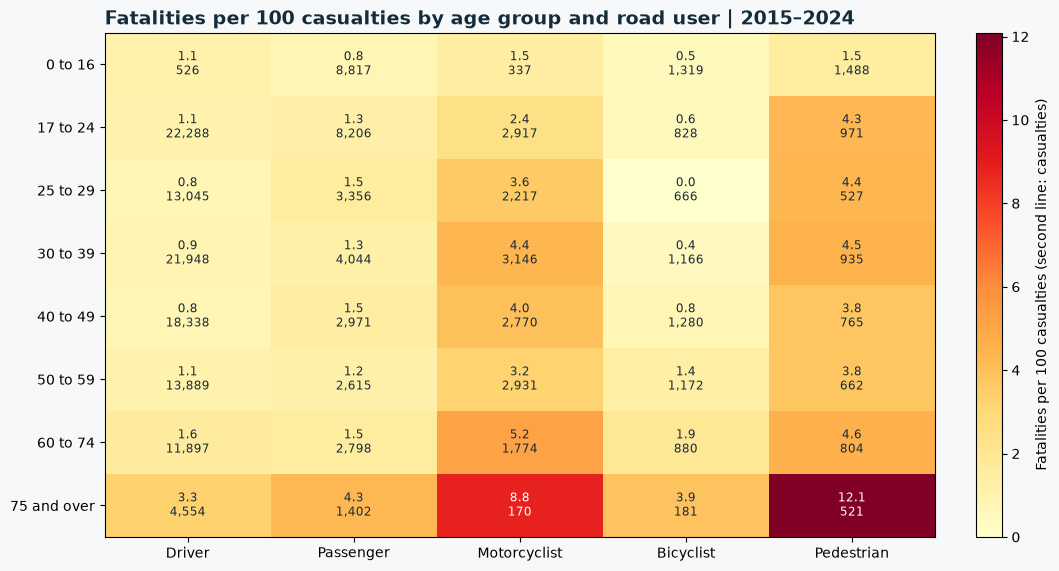

Pedestrians aged 75 and over: 12.1 fatalities per 100 casualties (63/521). Pedestrians aged 17–74: 4.2.


In [22]:
rate_years = complete_years[-10:]
rate_period = f'{rate_years.min()}–{rate_years.max()}'


# Casualties, fatalities and fatalities per 100 casualties with a Wilson interval, for the given grouping.
def fatality_rates(frame, keys):
    counts = frame.assign(Fatalities=frame['Casualty_Count'].where(frame['Casualty_Severity'].eq('Fatality'), 0)
                          ).groupby(keys)[['Casualty_Count', 'Fatalities']].sum()
    counts = counts.rename(columns={'Casualty_Count': 'Casualties'})
    low, high = wilson_interval(counts['Fatalities'], counts['Casualties'])
    return counts.assign(**{'Fatalities per 100 casualties': 100 * counts['Fatalities'] / counts['Casualties'],
                            '95% low': 100 * low, '95% high': 100 * high})


equipment_decade = equipment_source.loc[equipment_source['Crash_Year'].isin(rate_years)
                                        & equipment_source['Casualty_Restraint_Helmet_Use'].ne('Not applicable')]
equipment_rates = fatality_rates(equipment_decade, [road_user_column, 'Casualty_Restraint_Helmet_Use'])
equipment_layout = [
    ('Vehicle Occupant', 'Restrained'), ('Vehicle Occupant', 'Restraint Use Not determined'),
    ('Vehicle Occupant', 'Unrestrained'), ('Motorcyclist', 'Helmet Worn'),
    ('Motorcyclist', 'Helmet Use Not determined'), ('Motorcyclist', 'Helmet Not Worn'),
    ('Bicyclist', 'Helmet Worn'), ('Bicyclist', 'Helmet Use Not determined'), ('Bicyclist', 'Helmet Not Worn'),
]
assert set(equipment_layout) == set(equipment_rates.index)
equipment_rates = equipment_rates.loc[equipment_layout]
display(equipment_rates.round(2))
occupant_rate = equipment_rates.loc['Vehicle Occupant', 'Fatalities per 100 casualties']
rider_rate = equipment_rates.loc['Motorcyclist', 'Fatalities per 100 casualties']
print(f"Vehicle occupants: unrestrained {occupant_rate['Unrestrained']:.2f} and restrained {occupant_rate['Restrained']:.2f} "
      f"fatalities per 100 casualties, a ratio of {occupant_rate['Unrestrained'] / occupant_rate['Restrained']:.1f}. "
      f"Not determined: {occupant_rate['Restraint Use Not determined']:.2f}.")
print(f"Motorcyclists: helmet not worn {rider_rate['Helmet Not Worn']:.2f} and worn {rider_rate['Helmet Worn']:.2f}, "
      f"a ratio of {rider_rate['Helmet Not Worn'] / rider_rate['Helmet Worn']:.1f}.")

fig, ax = plt.subplots(figsize=(11, 5.2), facecolor='#f6f8fa')
fig.subplots_adjust(left=.33, right=.95, bottom=.13, top=.80)
fig.suptitle(f'How often did a casualty die, by recorded protection? | {rate_period}',
             x=.045, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.045, .86, 'Fatalities per 100 recorded casualties. Lines show Wilson 95% intervals. Uninjured people are not in the data.',
         fontsize=9.5, color='#405664')
status_colors = {'Restrained': '#007c82', 'Helmet Worn': '#007c82', 'Unrestrained': '#a64d25',
                 'Helmet Not Worn': '#a64d25'}
positions = np.arange(len(equipment_rates)) + np.repeat([0, .6, 1.2], 3)
for y, ((user, status), row) in zip(positions, equipment_rates.iterrows()):
    color = status_colors.get(status, '#8498a7')
    ax.hlines(y, row['95% low'], row['95% high'], color=color, linewidth=2)
    ax.scatter(row['Fatalities per 100 casualties'], y, color=color, s=55, zorder=3)
    ax.annotate(f"{row['Fatalities per 100 casualties']:.1f}  ({int(row['Fatalities']):,}/{int(row['Casualties']):,})",
                (row['95% high'], y), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9,
                color='#142b3a')
ax.set(yticks=positions, yticklabels=[f'{user} · {status}' for user, status in equipment_rates.index],
       ylim=(positions.max() + .6, -.6), xlim=(0, equipment_rates['95% high'].max() * 1.32),
       xlabel='Fatalities per 100 casualties')
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

age_order = ['0 to 16', '17 to 24', '25 to 29', '30 to 39', '40 to 49', '50 to 59', '60 to 74', '75 and over']
user_order = ['Driver', 'Passenger', 'Motorcyclist', 'Bicyclist', 'Pedestrian']
casualty_decade = casualty_source.loc[casualty_source['Crash_Year'].isin(rate_years)]
age_rates = fatality_rates(casualty_decade, ['Casualty_AgeGroup', 'Casualty_RoadUserType'])
assert set(age_order) <= set(age_rates.index.get_level_values(0))
age_rate_grid = age_rates['Fatalities per 100 casualties'].unstack().reindex(index=age_order, columns=user_order)
age_count_grid = age_rates['Casualties'].unstack().reindex(index=age_order, columns=user_order).fillna(0).astype(int)
# Blank any cell with fewer than 100 casualties.
age_rate_grid = age_rate_grid.where(age_count_grid.ge(100))
fig, ax = plt.subplots(figsize=(10.5, 5.6), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(age_rate_grid, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(len(user_order)), xticklabels=user_order, yticks=range(len(age_order)), yticklabels=age_order)
ax.set_title(f'Fatalities per 100 casualties by age group and road user | {rate_period}', loc='left',
             fontsize=14, fontweight='bold', color='#142b3a')
for row, col in np.ndindex(age_rate_grid.shape):
    value, count = age_rate_grid.iat[row, col], age_count_grid.iat[row, col]
    label = f'{value:.1f}\n{count:,}' if np.isfinite(value) else 'n<100'
    ax.text(col, row, label, ha='center', va='center', fontsize=8.5,
            color='white' if np.isfinite(value) and value > 6 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatalities per 100 casualties (second line: casualties)')
plt.show()
oldest_walkers = age_rates.loc[('75 and over', 'Pedestrian')]
other_adult_walkers = age_rates.loc[[(age, 'Pedestrian') for age in age_order[1:-1]]].sum()
print(f"Pedestrians aged 75 and over: {oldest_walkers['Fatalities per 100 casualties']:.1f} fatalities per 100 casualties "
      f"({int(oldest_walkers['Fatalities'])}/{int(oldest_walkers['Casualties'])}). Pedestrians aged 17–74: "
      f"{100 * other_adult_walkers['Fatalities'] / other_adult_walkers['Casualties']:.1f}.")

**What this achieved.** For 2015–2024, unrestrained vehicle occupants had 9.15 fatalities per 100 casualties (334 of 3,651) and restrained occupants 0.85 (956 of 112,807), a ratio of 10.8. Occupants whose restraint use was not determined had 1.52 per 100, higher than restrained occupants, so an analysis limited to known status leaves out a group with worse outcomes. Motorcyclists without a helmet had 7.58 per 100 compared with 3.65 with one. Pedestrians aged 75 and over had 12.1 fatalities per 100 casualties (63 of 521), compared with 4.2 for pedestrians aged 17–74.

##### Charts and Esri maps for the flat file

These visuals use the latest five complete years. The seatbelt chart and bubble map use **vehicle-occupant casualties with known seatbelt status**. The weather chart and shaded police-region map describe **fatalities among all people**. The maps display the 2026 QPS boundary layer for the named police regions.

**In this cell.** Draw paired bars for known-status seatbelt non-use among all and fatal occupant casualties. Plot weather conditions as bubbles, with recorded crash volume on the horizontal axis and fatalities represented by bubble area. Add an exact Poisson 95% interval to each weather rate so the conditions with few fatalities can be read with their uncertainty.

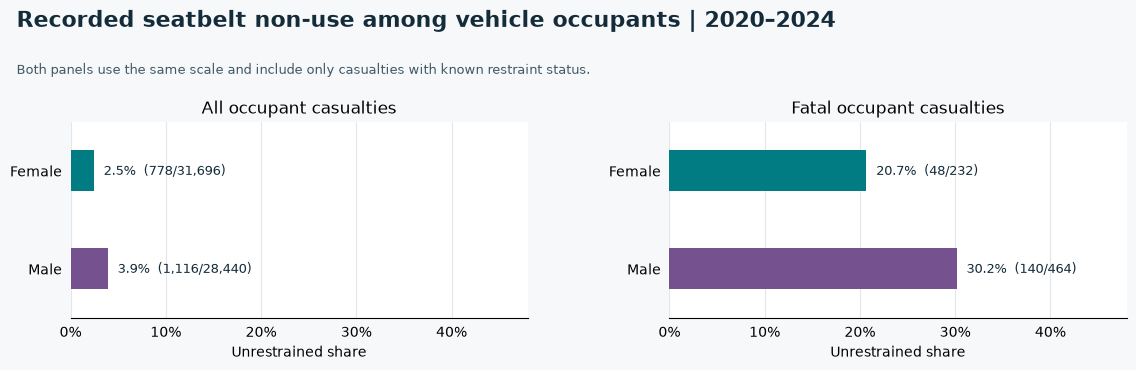

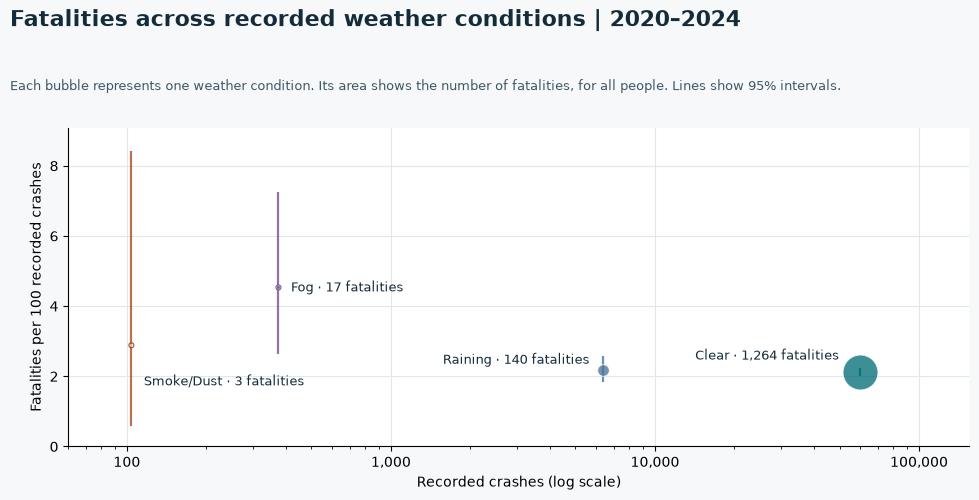

,95% low,95% high
Fatalities per 100 recorded crashes,,
Clear,2.00,2.23
Fog,2.64,7.26
Raining,1.85,2.59
Smoke/Dust,0.59,8.43


In [23]:
# Use the flat-file aggregates and pool counts before deriving shares.
context_period = f'{recent_years.min()}–{recent_years.max()}'
belt_chart = pd.DataFrame(belt_examples).set_index('Recorded gender')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.10, right=.98, bottom=.21, top=.70, wspace=.31)
fig.suptitle(f'Recorded seatbelt non-use among vehicle occupants | {context_period}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055,.82,'Both panels use the same scale and include only casualties with known restraint status.',
         fontsize=9.5,color='#405664')
for ax, percent, numerator, denominator, title in [
    (axes[0], 'Unrestrained share (%)', 'Unrestrained', 'Occupant casualties with known status',
     'All occupant casualties'),
    (axes[1], 'Unrestrained share of fatalities with known status (%)',
     'Unrestrained fatalities', 'Fatalities with known status', 'Fatal occupant casualties'),
]:
    y=np.arange(len(belt_chart))
    ax.barh(y,belt_chart[percent],height=.42,color=['#007c82','#76518f'])
    ax.set(yticks=y, yticklabels=belt_chart.index, ylim=(len(y)-.5,-.5),
           xlim=(0, 48),title=title,xlabel='Unrestrained share')
    for pos, (_, row) in enumerate(belt_chart.iterrows()):
        ax.annotate(f"{row[percent]:.1f}%  ({int(row[numerator]):,}/{int(row[denominator]):,})",
                    (row[percent],pos),xytext=(7,0),textcoords='offset points',
                    color='#142b3a',va='center',fontsize=9)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.spines[['top','right','left']].set_visible(False)
    ax.grid(axis='x',color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.tick_params(length=0,pad=6)
plt.show()

weather_chart = pd.DataFrame(weather_examples).loc[lambda d:d['Crashes'].gt(0)]
weather_palette = {'Clear':'#006d75','Raining':'#4a729b','Fog':'#76518f','Smoke/Dust':'#a64d25'}
fig, ax = plt.subplots(figsize=(10.6,5.4),facecolor='#f6f8fa')
fig.subplots_adjust(left=.11,right=.96,bottom=.17,top=.76)
fig.suptitle(f'Fatalities across recorded weather conditions | {context_period}',
             x=.055,ha='left',fontsize=16,fontweight='bold',color='#142b3a')
fig.text(.055,.83,'Each bubble represents one weather condition. Its area shows the number of fatalities, for all people. Lines show 95% intervals.',
         fontsize=9.5,color='#405664')
from scipy.stats import chi2

weather_intervals = {}
weather_offsets = {'Clear':(-15,12),'Raining':(-10,7),'Fog':(9,0),'Smoke/Dust':(9,-26)}
for row in weather_chart.to_dict('records'):
    label = row['Atmospheric condition']
    x, y = row['Crashes'], row['Fatalities per 100 recorded crashes']
    color = weather_palette[label]
    deaths = row['Fatalities, all people']
    # Exact Poisson 95% interval for the count of fatalities, expressed per 100 crashes.
    interval_low = 100 * (chi2.ppf(.025, 2 * deaths) / 2 if deaths else 0) / x
    interval_high = 100 * chi2.ppf(.975, 2 * (deaths + 1)) / 2 / x
    weather_intervals[label] = (interval_low, interval_high)
    ax.vlines(x, interval_low, interval_high, color=color, linewidth=1.6, alpha=.8, zorder=3)
    ax.scatter(x, y, s=row['Fatalities, all people']/2, color=color, alpha=.77,
               edgecolor='white', linewidth=.7, zorder=4)
    if row['Fatalities, all people'] < 20:
        ax.scatter(x, y, s=13, facecolor='none', edgecolor=color, linewidth=.75, zorder=5)
    dx, dy = weather_offsets[label]
    ax.annotate(f"{label} · {row['Fatalities, all people']:,} fatalities", (x,y), xytext=(dx,dy),
                textcoords='offset points', ha='right' if dx<0 else 'left', va='center',
                fontsize=9, color='#142b3a')
ax.set(xscale='log', xlim=(60,155000), 
       xlabel='Recorded crashes (log scale)',ylabel='Fatalities per 100 recorded crashes')
ax.set_ylim(0, max(high for _, high in weather_intervals.values()) + .65)
ax.xaxis.set_major_locator(mticker.FixedLocator([100,1000,10000,100000]))
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
plt.show()
display(pd.DataFrame(weather_intervals, index=['95% low', '95% high']).T.round(2)
        .rename_axis('Fatalities per 100 recorded crashes'))

**What this achieved.** Plotted known-status restraint shares for all and fatal occupant casualties and compared all-person fatality counts and rates by weather. The fog rate rests on 17 fatalities and has a 95% interval of 2.6 to 7.3 fatalities per 100 crashes, which sits just above the intervals for clear conditions (2.0–2.2) and rain (1.9–2.6). Smoke or dust has 3 fatalities and an interval of 0.6 to 8.4, which supports no conclusion.

##### Map restraint and weather patterns by region

**In this cell.** Build two Esri maps using police-region boundaries and pooled counts. Size the restraint bubbles by the number of female occupant casualties with known status, and shade regions in the weather map by the share of all fatalities recorded in rain.

In [24]:
import folium
from branca.colormap import LinearColormap
from html import escape as escape_map_text
from shapely.geometry import mapping

# Pool the window by police region and leave out the Unknown region.
context_regions = context_recent.groupby(level='Police_Region').sum(min_count=1)
context_regions = context_regions.loc[context_regions.index != 'Unknown']
context_regions['female_known'] = context_regions['seatbelt_female_restrained'] + context_regions['seatbelt_female_unrestrained']
context_regions['female_unrestrained_share'] = (
    context_regions['seatbelt_female_unrestrained']
    .div(context_regions['female_known'].where(context_regions['female_known'].gt(0))).mul(100)
)
context_regions['rain_fatality_share'] = (
    context_regions['weather_raining_fatalities']
    .div(context_regions['weather_total_fatalities'].where(context_regions['weather_total_fatalities'].gt(0))).mul(100)
)

# Merge the police-region polygons and simplify them for display.
region_shapes = {}
for (region,), geometry in shapefile_polygons(SPATIAL_DIR / 'police.zip', ('REGION',)):
    region_shapes.setdefault(region.title(), []).append(geometry)
region_shapes = {
    region: union_all(parts).simplify(.008, preserve_topology=True)
    for region, parts in region_shapes.items() if region in context_regions.index
}
assert set(region_shapes) == set(context_regions.index)


# Esri basemap with a small title panel.
def context_esri_map(title, detail):
    view = folium.Map(location=[-22.6, 146.8], zoom_start=5, tiles='Esri.WorldStreetMap',
                      control_scale=True)
    header = folium.Element(
        '<div style="position:absolute;top:12px;left:52px;z-index:1000;max-width:340px;'
        'padding:8px 11px;background:#fbfdff;color:#173347;'
        'border:1px solid #b9c9d5;border-radius:5px;box-shadow:0 1px 4px #33445550;font-size:12px">'
        f'<strong>{escape_map_text(title)}</strong><br>{escape_map_text(detail)}</div>'
    )
    view.get_root().html.add_child(header)
    return view


belt_bubble_map = context_esri_map(
    f'Female occupant restraint records | {context_period}',
    'Bubble area shows casualties with known status. Colour shows the unrestrained share.',
)
belt_scale = LinearColormap(['#e9f3f5','#55a6aa','#056572'], vmin=0,
                            vmax=float(context_regions['female_unrestrained_share'].max()),
                            caption='% of female occupant casualties unrestrained among known status')
folium.GeoJson({
    'type':'FeatureCollection',
    'features':[{'type':'Feature','geometry':mapping(shape),'properties':{'region':region}}
                for region,shape in region_shapes.items()],
}, style_function=lambda feature: {'fillOpacity':0,'color':'#58788d','weight':1,'opacity':.65},
    name='Police regions').add_to(belt_bubble_map)
max_known = context_regions['female_known'].max()
for region, row in context_regions.iterrows():
    point = region_shapes[region].representative_point()
    rate = float(row['female_unrestrained_share'])
    label = folium.Tooltip(
        f"<b>{escape_map_text(region)}</b><br>{int(row['seatbelt_female_unrestrained']):,} of "
        f"{int(row['female_known']):,} with known status ({rate:.1f}%)"
    )
    folium.CircleMarker([point.y,point.x],radius=25*np.sqrt(row['female_known']/max_known),
                        color='#193e51',weight=1.25,fill=True,fill_color=belt_scale(rate),
                        fill_opacity=.9,tooltip=label).add_to(belt_bubble_map)
belt_scale.add_to(belt_bubble_map)
display(belt_bubble_map)

rain_region_map = context_esri_map(
    f'Fatalities recorded in rain | {context_period}',
    'Each police region is shaded by the share of all recorded fatalities that occurred in rain.',
)
rain_scale = LinearColormap(['#b8d7e8','#5486ad','#234d7c'], vmin=0,
                            vmax=float(context_regions['rain_fatality_share'].max()),
                            caption='% of fatalities recorded in rain, all people')
rain_shapes=[]
for region in context_regions.index:
    row=context_regions.loc[region]
    rate=float(row['rain_fatality_share'])
    rain_shapes.append({
        'type':'Feature','geometry':mapping(region_shapes[region]),
        'properties':{'region':region,'rain':int(row['weather_raining_fatalities']),
                      'total':int(row['weather_total_fatalities']),'percent':f'{rate:.1f}%',
                      'color':rain_scale(rate)},
    })
folium.GeoJson(
    {'type':'FeatureCollection','features':rain_shapes},
    style_function=lambda feature: {'fillColor':feature['properties']['color'],'fillOpacity':.67,
                                    'color':'#23445d','weight':1.15},
    tooltip=folium.GeoJsonTooltip(fields=['region','rain','total','percent'],
                                   aliases=['Police region','Fatalities in rain','All fatalities','Share in rain']),
).add_to(rain_region_map)
rain_scale.add_to(rain_region_map)
display(rain_region_map)

**Static pictures of the maps above.** A saved notebook may show "Make this Notebook Trusted to load map" in place of an interactive map. The pictures below show the same view from the run saved on 20 November 2026. For the interactive version, run the cell above or open `Queensland Traffic V6 - Esri Maps.html` in a browser.

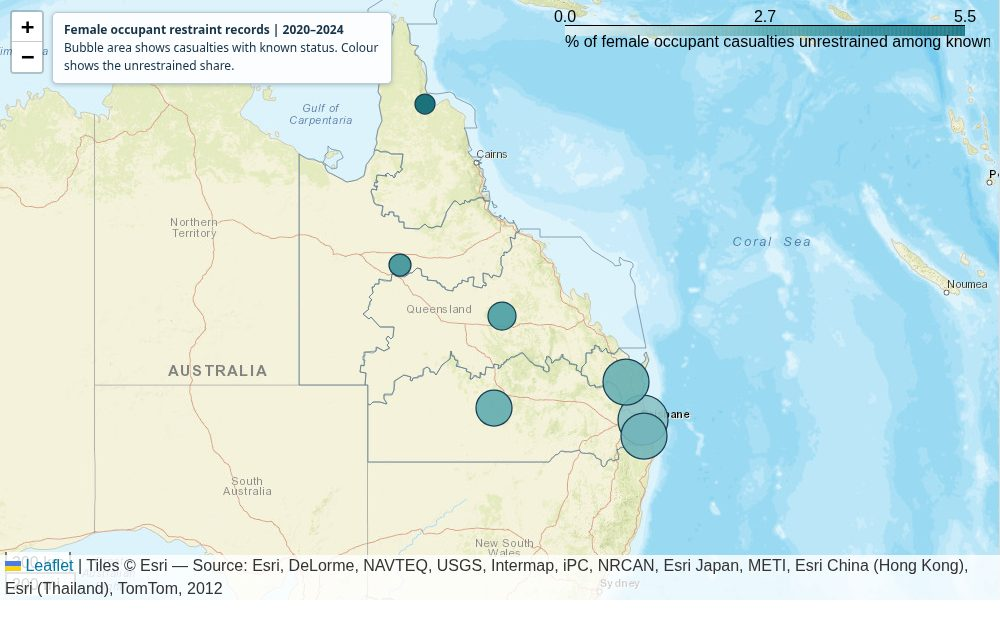

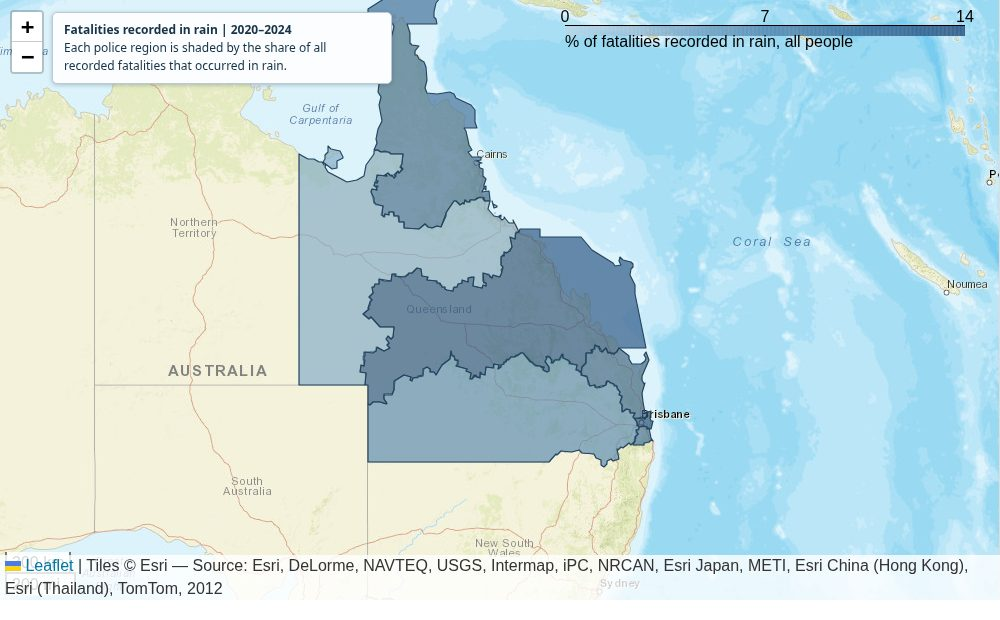

**What this achieved.** Built two interactive Esri maps for the seven named police regions. The bubble map shows female occupant restraint records. The shaded map shows the share of all recorded fatalities that occurred in rain.

#### Two- and three-level Sankey diagrams

Both diagrams cover the latest five complete reporting years. The two-level vehicle diagram assigns every injury crash with at least one of the three vehicle flags to one vehicle group, then shows its crash severity. The three-level safety diagram shows road-user type, reported restraint or helmet status, and injury severity for casualties with known equipment status. Band widths show recorded counts. Adjacent bands summarize the categories on either side of that stage.

**In this cell.** Build Sankey diagrams from weighted counts across two or three categories. Reconcile totals at each stage so the band widths reflect the counts moving between adjacent categories.

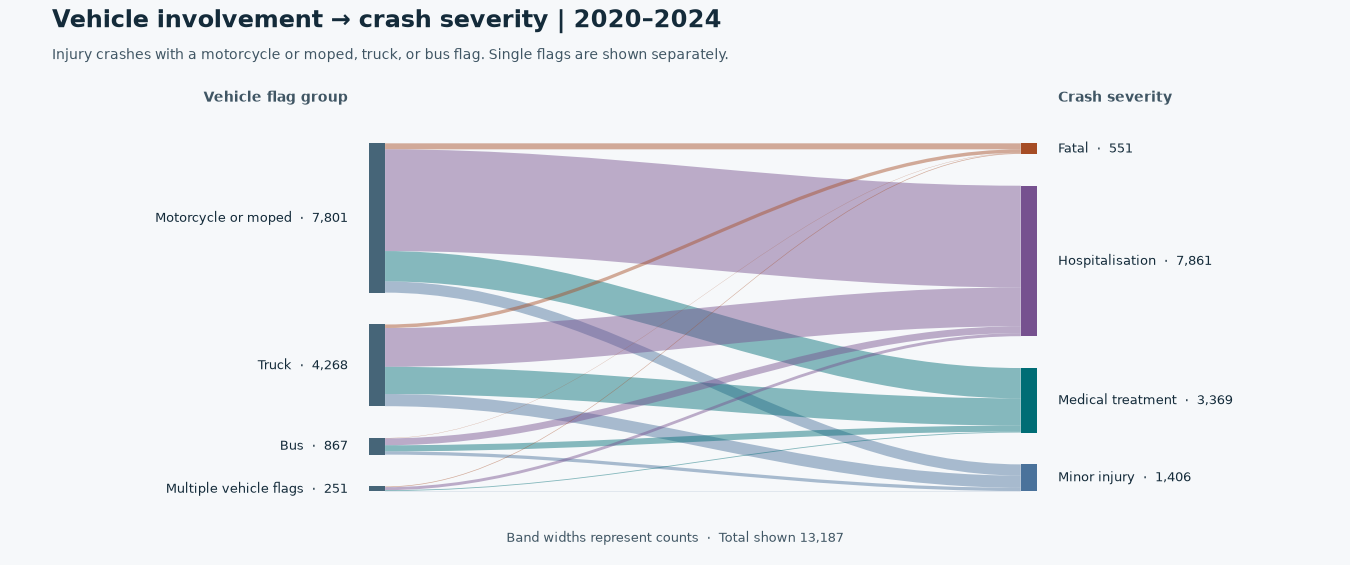

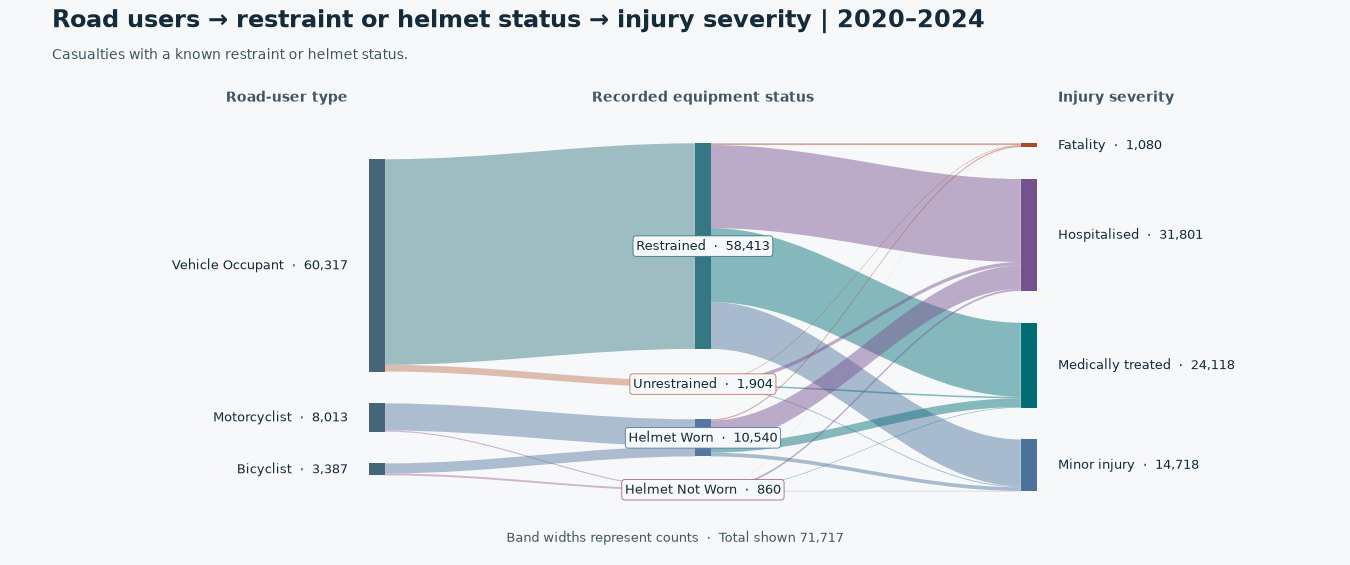

In [25]:
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch, Rectangle


# Draw a two- or three-level Sankey diagram whose band widths are proportional to counts.
def count_sankey(records, levels, orders, headers, title, caption):
    assert 2 <= len(levels) <= 3
    total = int(records['Count'].sum())
    node_totals = [
        records.groupby(field)['Count'].sum().reindex(order).fillna(0).astype(int)
        for field, order in zip(levels, orders)
    ]
    node_totals = [values.loc[values.gt(0)] for values in node_totals]
    assert total > 0 and all(values.sum() == total for values in node_totals)

    outcome_colors = dict(zip(orders[-1], ['#a64d25', '#76518f', '#006d75', '#4a729b']))
    equipment_colors = dict(zip(orders[-2], ['#357884', '#c27754', '#5678a0', '#a06693']))
    stage_colors = ([{}, outcome_colors] if len(levels) == 2 else
                    [{}, equipment_colors, outcome_colors])
    gap, width = .065, .012
    height_per_record = (.71 - gap * (max(map(len, node_totals)) - 1)) / total
    xs = np.linspace(.27, .76, len(levels))

    def node_bottoms(totals):
        heights = totals * height_per_record
        occupied = heights.sum() + gap * (len(heights) - 1)
        return .485 + occupied / 2 - (heights + gap).cumsum() + gap

    bottoms = [node_bottoms(totals) for totals in node_totals]
    fig, ax = plt.subplots(figsize=(14, 5.8), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.025, right=.975, bottom=.035, top=.88)
    fig.text(.055, .945, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.055, .89, caption, fontsize=10, color='#405664')
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')

    for stage, (left_field, right_field) in enumerate(zip(levels, levels[1:])):
        left_totals, right_totals = node_totals[stage:stage+2]
        links = records.pivot_table(index=left_field, columns=right_field, values='Count',
                                    aggfunc='sum', fill_value=0)
        links = links.reindex(index=left_totals.index, columns=right_totals.index, fill_value=0)
        assert links.sum(axis=1).equals(left_totals) and links.sum(axis=0).equals(right_totals)
        left_top = bottoms[stage] + left_totals * height_per_record
        right_top = bottoms[stage + 1] + right_totals * height_per_record
        x0, x1 = xs[stage] + width, xs[stage + 1]
        control0, control1 = x0 + .36 * (x1 - x0), x1 - .36 * (x1 - x0)
        for start, destinations in links.iterrows():
            for end, count in destinations.items():
                if count <= 0:
                    continue
                height = count * height_per_record
                a, b = left_top[start], right_top[end]
                vertices = [(x0, a), (control0, a), (control1, b), (x1, b),
                            (x1, b-height), (control1, b-height),
                            (control0, a-height), (x0, a-height), (x0, a)]
                path = PlotPath(vertices, [PlotPath.MOVETO, *([PlotPath.CURVE4] * 3),
                                           PlotPath.LINETO, *([PlotPath.CURVE4] * 3), PlotPath.CLOSEPOLY])
                ax.add_patch(PathPatch(path, facecolor=stage_colors[stage + 1][end],
                                       edgecolor='none', alpha=.46))
                left_top[start] -= height
                right_top[end] -= height

    for stage, (x, totals, header, colors) in enumerate(zip(xs, node_totals, headers, stage_colors)):
        align = 'right' if stage == 0 else 'left' if stage == len(levels) - 1 else 'center'
        label_x = x - .016 if align == 'right' else x + width + .016 if align == 'left' else x + width / 2
        ax.text(label_x, .925, header, ha=align, color='#405664', fontweight='bold')
        for label, count in totals.items():
            bottom = bottoms[stage][label]
            height = count * height_per_record
            ax.add_patch(Rectangle((x, bottom), width, height, facecolor=colors.get(label, '#466578')))
            box = {'facecolor': '#f6f8fa', 'edgecolor': colors.get(label, '#466578'),
                   'boxstyle': 'round,pad=.24', 'linewidth': .6} if align == 'center' else None
            ax.text(label_x, bottom + height / 2, f'{label}  ·  {count:,}',
                    ha=align, va='center', fontsize=9.5, color='#142b3a', bbox=box)
    ax.text(.5, .035, f'Band widths represent counts  ·  Total shown {total:,}',
            ha='center', va='center', fontsize=9, color='#405664')
    plt.show()


# Assign each flagged injury crash to one vehicle group so that every crash is counted once.
vehicle_groups = ['Motorcycle or moped', 'Truck', 'Bus', 'Multiple vehicle flags']
vehicle_flag_values = vehicle_recent[list(vehicle_flags.values())].eq('Yes')
flag_counts = vehicle_flag_values.sum(axis=1)
vehicle_group = pd.Series(pd.NA, dtype='string', index=vehicle_recent.index)
for label, column in vehicle_flags.items():
    vehicle_group.loc[flag_counts.eq(1) & vehicle_flag_values[column]] = label
vehicle_group.loc[flag_counts.gt(1)] = vehicle_groups[-1]
vehicle_records = (vehicle_recent.assign(Vehicle_group=vehicle_group)
                   .dropna(subset='Vehicle_group')
                   .rename(columns={'Count_Crashes': 'Count'}))
assert int(vehicle_records['Count'].sum()) == vehicle_recent.loc[flag_counts.gt(0), 'Count_Crashes'].sum()
period = f'{recent_years.min()}–{recent_years.max()}'
count_sankey(
    vehicle_records, ['Vehicle_group', 'Crash_Severity'], [vehicle_groups, injury_labels],
    ['Vehicle flag group', 'Crash severity'],
    f'Vehicle involvement → crash severity | {period}',
    'Injury crashes with a motorcycle or moped, truck, or bus flag. Single flags are shown separately.',
)

# Casualties with a known restraint or helmet status.
restraint_categories = ['Restrained', 'Unrestrained', 'Helmet Worn', 'Helmet Not Worn']
restraint_window = safety_rows.loc[
    safety_rows['Crash_Year'].isin(recent_years)
    & safety_rows['Casualty_Restraint_Helmet_Use'].isin(restraint_categories)
].rename(columns={'Casualty_Count': 'Count'})
count_sankey(
    restraint_window, ['Casualty_Road_User_Type', 'Casualty_Restraint_Helmet_Use', 'Casualty_Severity'],
    [['Vehicle Occupant', 'Motorcyclist', 'Bicyclist'], restraint_categories,
     ['Fatality', 'Hospitalised', 'Medically treated', 'Minor injury']],
    ['Road-user type', 'Recorded equipment status', 'Injury severity'],
    f'Road users → restraint or helmet status → injury severity | {period}',
    'Casualties with a known restraint or helmet status.',
)


**What this achieved.** Plotted weighted flows from the recorded vehicle flag group to crash severity, and from road-user type through equipment status to injury severity.

##### Sankey of recorded gender, seatbelt status and injury severity

Flow widths use observed casualty counts for vehicle occupants with known restraint status. The restraint file directly records all three variables. The road casualties file reconciles the totals at a shared demographic level. Driver flags, crash factors, and weather remain year-and-region context.

**In this cell.** Filter to vehicle-occupant casualties with a known restraint status. Reconcile the female and male totals against the flat file, then plot flows from recorded gender through belt status to injury severity.

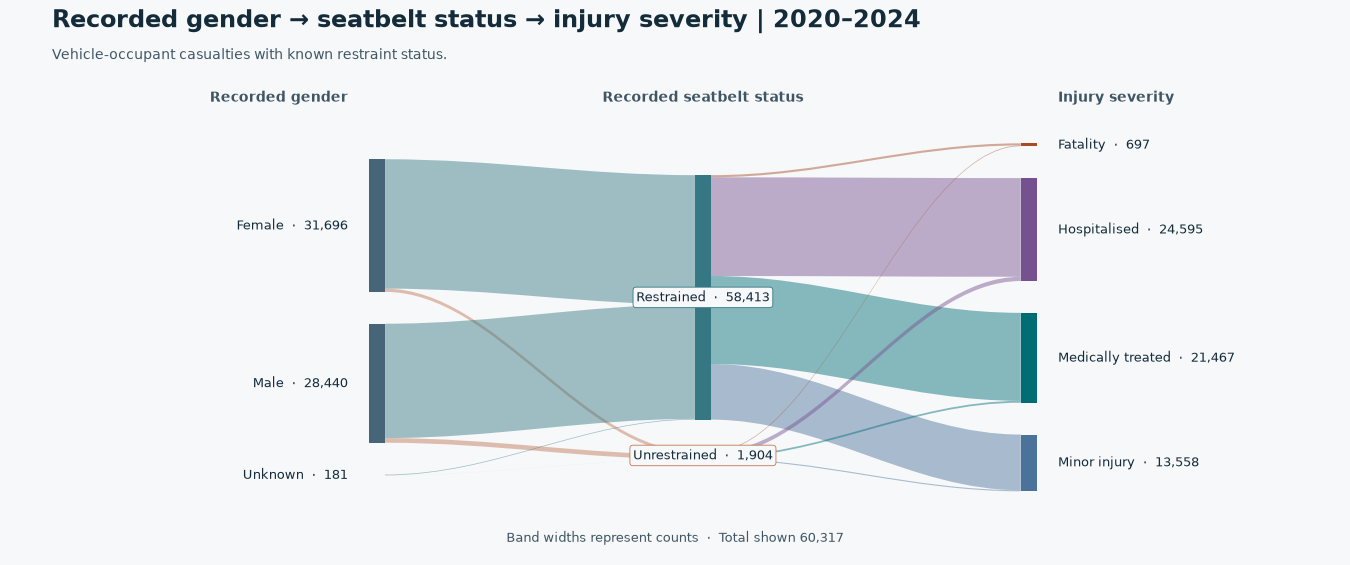

In [26]:
# Vehicle occupants with a known seatbelt status in the comparison window.
belt_sankey_records = equipment_source.loc[
    equipment_source['Crash_Year'].isin(recent_years)
    & equipment_source[road_user_column].eq('Vehicle Occupant')
    & equipment_source['Casualty_Restraint_Helmet_Use'].isin(['Restrained','Unrestrained'])
].rename(columns={'Casualty_Count':'Count'})
belt_record_counts = belt_sankey_records.groupby('Casualty_Gender')['Count'].sum()
assert belt_record_counts['Female'] == context_totals['seatbelt_female_restrained'] + context_totals['seatbelt_female_unrestrained']
assert belt_record_counts['Male'] == context_totals['seatbelt_male_restrained'] + context_totals['seatbelt_male_unrestrained']
count_sankey(
    belt_sankey_records, ['Casualty_Gender','Casualty_Restraint_Helmet_Use','Casualty_Severity'],
    [['Female','Male','Unknown'],['Restrained','Unrestrained'],
     ['Fatality','Hospitalised','Medically treated','Minor injury']],
    ['Recorded gender','Recorded seatbelt status','Injury severity'],
    f'Recorded gender → seatbelt status → injury severity | {context_period}',
    'Vehicle-occupant casualties with known restraint status.',
)

**What this achieved.** Plotted recorded gender, known seatbelt status and injury severity together using occupant casualty counts. The female and male totals agree with the flat-file values.

#### Treemaps of crash counts and severity

Each outlined group contains smaller tiles for the severity categories. Areas are proportional to recorded injury crash counts and colours identify severity. The regional treemap shows the named police regions. The vehicle treemap shows crashes with at least one motorcycle or moped, truck, or bus flag. Single-flag crashes and crashes with multiple flags occupy separate groups.

**In this cell.** Lay out nested treemap tiles proportional to recorded injury crash counts. Group tiles by police region or vehicle flag group, with severity shown by colour.

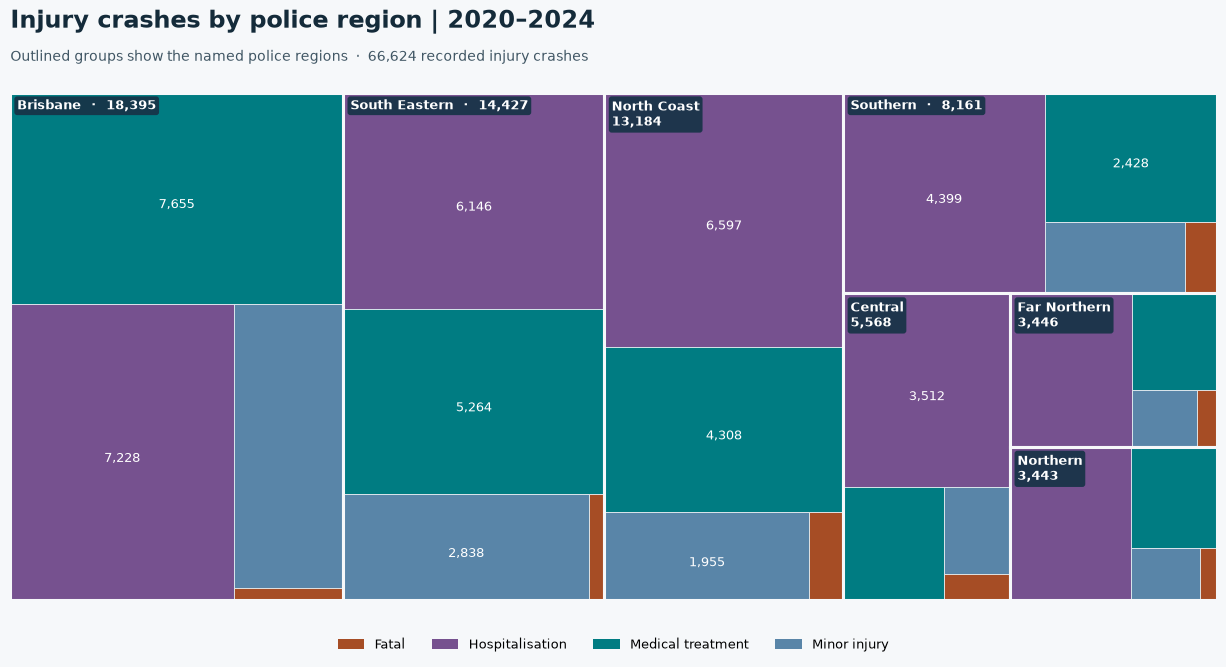

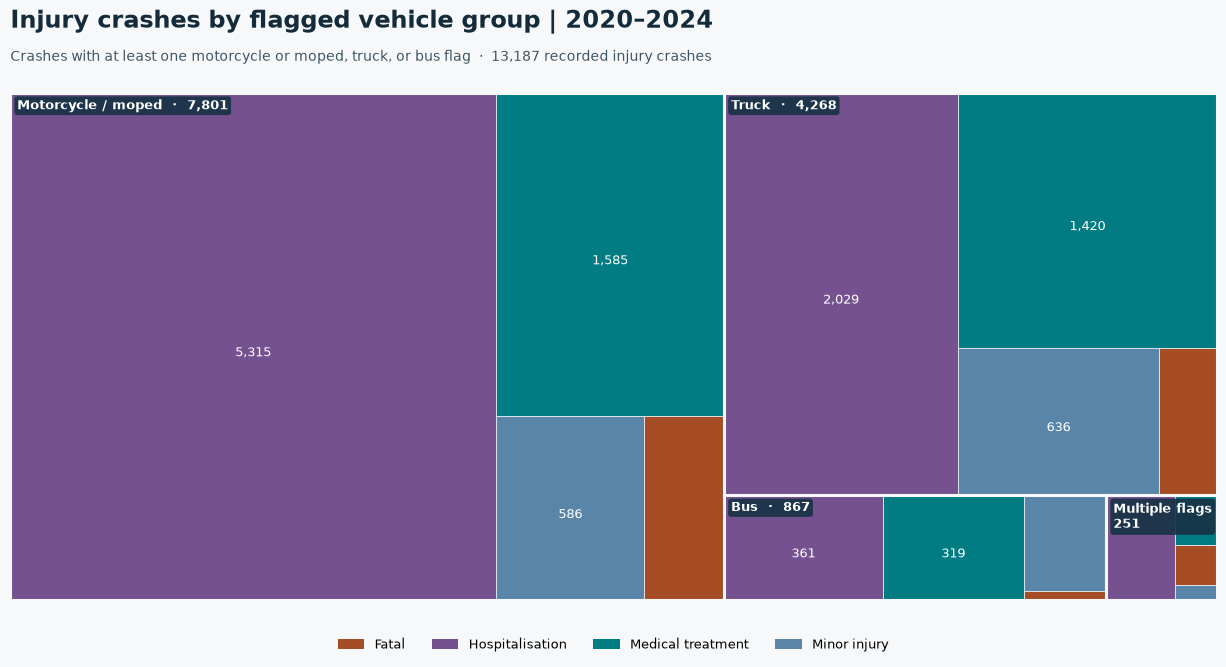

In [27]:
from matplotlib.patches import Patch


# Recursively split a rectangle into tiles with areas proportional to the counts.
def area_tiles(groups, x, y, width, height):
    # Split the larger dimension in proportion to recorded counts.
    if len(groups) == 1:
        yield groups[0][0], x, y, width, height
        return
    values = np.array([count for _, count in groups])
    total = values.sum()
    split = int(np.abs(values.cumsum()[:-1] - total / 2).argmin()) + 1
    fraction = values[:split].sum() / total
    if width >= height:
        edge = width * fraction
        yield from area_tiles(groups[:split], x, y, edge, height)
        yield from area_tiles(groups[split:], x + edge, y, width - edge, height)
    else:
        edge = height * fraction
        yield from area_tiles(groups[:split], x, y + height - edge, width, edge)
        yield from area_tiles(groups[split:], x, y, width, height - edge)


# Draw a nested treemap: one outlined group per category, with a tile per severity level.
def count_treemap(counts, title, subtitle):
    colors = {'Fatal': '#a64d25', 'Hospitalisation': '#76518f',
              'Medical treatment': '#007c82', 'Minor injury': '#5985a8'}
    totals = counts.sum(axis=1)
    groups = totals.loc[totals.gt(0)].sort_values(ascending=False)
    assert len(groups) and counts.ge(0).all(axis=None)
    total = int(groups.sum())
    width, height = 12.6, 5.3
    fig, ax = plt.subplots(figsize=(13.4, 7.05), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.035, right=.965, bottom=.135, top=.855)
    fig.text(.05, .947, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.05, .9, f'{subtitle}  ·  {total:,} recorded injury crashes',
             fontsize=10, color='#405664')
    ax.set(xlim=(0, width), ylim=(0, height), aspect='equal')
    ax.axis('off')
    outer_area = 0
    for group, x, y, group_width, group_height in area_tiles(list(groups.items()), 0, 0, width, height):
        outer_area += group_width * group_height
        values = counts.loc[group].loc[lambda row: row.gt(0)].sort_values(ascending=False)
        assert np.isclose(group_width * group_height, width * height * groups[group] / total)
        for severity_label, sx, sy, sw, sh in area_tiles(list(values.items()), x, y, group_width, group_height):
            assert np.isclose(sw * sh, width * height * values[severity_label] / total)
            ax.add_patch(Rectangle((sx, sy), sw, sh, facecolor=colors[severity_label],
                                   edgecolor='#e4edf1', linewidth=.6))
            if sw >= 1.30 and sh >= .85:
                ax.text(sx + sw / 2, sy + sh / 2 - .07, f'{values[severity_label]:,}',
                        color='white', ha='center', va='center', fontsize=9)
        ax.add_patch(Rectangle((x, y), group_width, group_height, fill=False,
                               edgecolor='#f6f8fa', linewidth=2.2))
        short_names = {'Motorcycle or moped': 'Motorcycle / moped',
                       'Multiple vehicle flags': 'Multiple flags'}
        name = short_names.get(group, group)
        label = f'{name}  ·  {groups[group]:,}'
        if group_width < 2.65:
            label = f'{name}\n{groups[group]:,}'
        ax.text(x + .075, y + group_height - .07, label, ha='left', va='top',
                color='white', fontsize=9, fontweight='bold', zorder=5,
                bbox=dict(facecolor='#173347', edgecolor='none', boxstyle='round,pad=.23', alpha=.92))
    assert np.isclose(outer_area, width * height)
    fig.legend(handles=[Patch(facecolor=color, label=label) for label, color in colors.items()],
               loc='lower center', bbox_to_anchor=(.5, .045), ncols=4, frameon=False, fontsize=9.5)
    plt.show()


treemap_region = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
]
region_tiles = pd.crosstab(treemap_region['Police_Region'], treemap_region['Crash_Severity'])
assert region_tiles.to_numpy().sum() == len(treemap_region)
count_treemap(region_tiles, f'Injury crashes by police region | {period}',
              'Outlined groups show the named police regions')

vehicle_tiles = vehicle_records.pivot_table(
    index='Vehicle_group', columns='Crash_Severity', values='Count', aggfunc='sum', fill_value=0,
)
assert vehicle_tiles.to_numpy().sum() == vehicle_records['Count'].sum()
count_treemap(vehicle_tiles, f'Injury crashes by flagged vehicle group | {period}',
              'Crashes with at least one motorcycle or moped, truck, or bus flag')

**What this achieved.** Built treemaps sized by injury crash counts. Tiles show the severity mix within each named police region and flagged vehicle group.

#### Associations that change when we compare like with like

These figures use 2020–2024, the latest five complete years. They compare regional patterns, crash-level combinations of lighting and road surface, and flag associations within their original source tables. These are descriptive comparisons. Travel exposure and many other differences between crashes are unavailable.

**In this cell.** Compare the pooled speed–severity correlation across region-years with the correlation of residuals after accounting for region and year using least squares. Plot both views side by side.

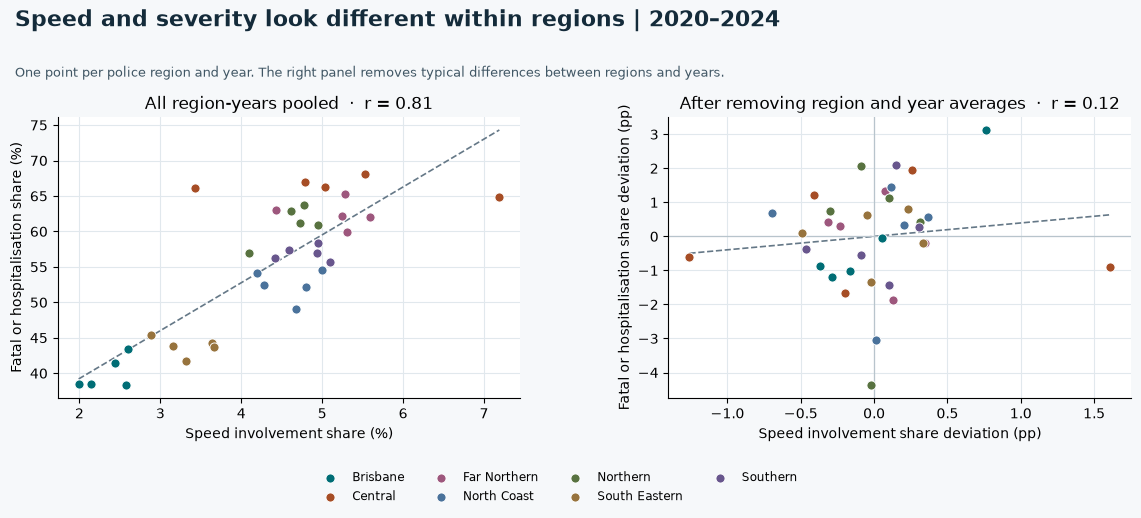

In [28]:
# Compare the pooled region-year pattern with deviations from typical region and year levels.
within_fields = ['Speed', 'Serious crash']
regional_rates = pd.DataFrame({
    label: regional_window[f'{label} numerator'].div(
        regional_window[f'{label} denominator'].where(regional_window[f'{label} denominator'].gt(0))
    ).mul(100) for label in within_fields
}).dropna().reset_index()
# Region and year indicator variables. Residuals from this fit are the within-region, within-year deviations.
indicators = pd.get_dummies(
    regional_rates[['Crash_Year', 'Police_Region']].astype(str), drop_first=True, dtype=float
)
design = np.column_stack([np.ones(len(indicators)), indicators.to_numpy()])
observed_rates = regional_rates[within_fields].to_numpy()
residual_rates = observed_rates - design @ np.linalg.lstsq(design, observed_rates, rcond=None)[0]
pooled_r = float(np.corrcoef(observed_rates.T)[0, 1])
within_r = float(np.corrcoef(residual_rates.T)[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.09, right=.97, bottom=.26, top=.78, wspace=.32)
fig.suptitle(f'Speed and severity look different within regions | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .855, 'One point per police region and year. The right panel removes typical differences between regions and years.',
         fontsize=9.5, color='#405664')
for ax, values, heading, r, suffix in [
    (axes[0], observed_rates, 'All region-years pooled', pooled_r, ' (%)'),
    (axes[1], residual_rates, 'After removing region and year averages', within_r, ' deviation (pp)'),
]:
    for region, rows in regional_rates.groupby('Police_Region'):
        positions = rows.index
        ax.scatter(values[positions, 0], values[positions, 1], s=43,
                   color=region_colors[region], edgecolor='white', linewidth=.65, label=region, zorder=3)
    x_values = np.array([values[:, 0].min(), values[:, 0].max()])
    ax.plot(x_values, np.polyval(np.polyfit(values[:, 0], values[:, 1], 1), x_values),
            linestyle='--', color='#657887', linewidth=1.2)
    ax.set(title=f'{heading}  ·  r = {r:.2f}', xlabel=f'Speed involvement share{suffix}',
           ylabel=f'Fatal or hospitalisation share{suffix}')
    ax.grid(color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(0, color='#b8c4cc', linewidth=.9)
axes[1].axvline(0, color='#b8c4cc', linewidth=.9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, .045),
           ncols=4, frameon=False, fontsize=8.8)
plt.show()

**What this achieved.** Compared pooled region-year speed and severity shares with their deviations after accounting for region and year. The correlation fell from 0.81 to 0.12.

##### Lighting and wet-road comparisons

**In this cell.** Use direct standardisation to compare wet and dry sealed roads under the same police-region and speed-zone mix. Show severe crash shares and the wet-minus-dry difference for each lighting condition.

Crash_Road_Surface_Condition,Sealed - Dry,Sealed - Wet,Wet − dry (pp)
Crash_Lighting_Condition,,,
Daylight,44.3,46.1,1.8
Darkness - Lighted,54.7,51.9,-2.9
Darkness - Not lighted,64.3,64.0,-0.2


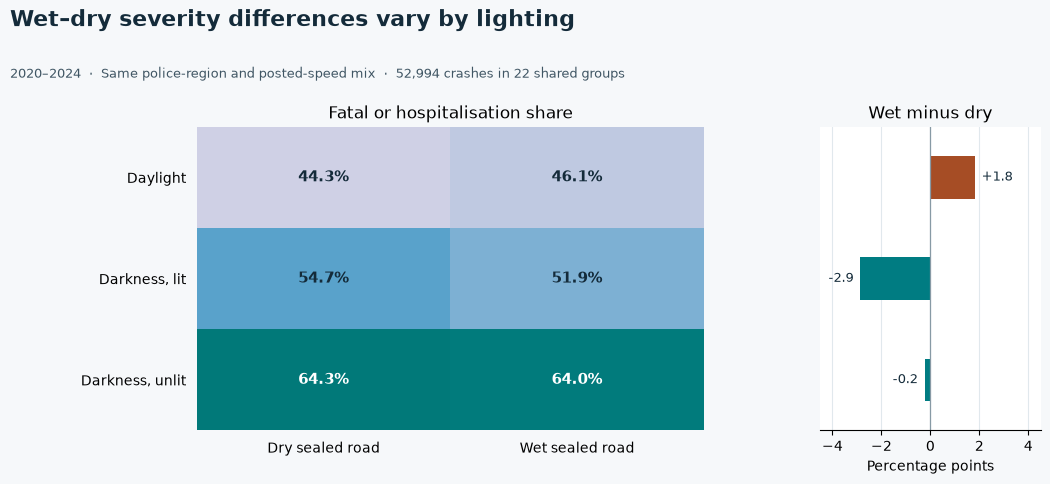

In [29]:
# Compare six lighting/surface combinations under one regional and speed-zone mix.
lights = ['Daylight', 'Darkness - Lighted', 'Darkness - Not lighted']
surfaces = ['Sealed - Dry', 'Sealed - Wet']
light_field, surface_field = 'Crash_Lighting_Condition', 'Crash_Road_Surface_Condition'
road_conditions = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
    & location_injury[light_field].isin(lights) & location_injury[surface_field].isin(surfaces)
    & location_injury['Crash_Speed_Limit'].notna()
].copy()
condition_order = pd.MultiIndex.from_product([surfaces, lights], names=[surface_field, light_field])
condition_counts = road_conditions.assign(Serious=road_conditions['Crash_Severity'].isin(severe_labels)).groupby(
    ['Police_Region', 'Crash_Speed_Limit', surface_field, light_field]
)['Serious'].agg(['size', 'sum'])
counts = condition_counts['size'].unstack([surface_field, light_field]).reindex(columns=condition_order)
serious = condition_counts['sum'].unstack([surface_field, light_field]).reindex(columns=condition_order)
# Use only region and speed-zone groups with at least 10 crashes in all six lighting/surface combinations.
common = counts.ge(10).all(axis=1)
supported = counts.loc[common]
weighted_count = supported.sum(axis=1)
# Direct standardisation: weight each group by its share of all crashes in the shared groups.
weight = weighted_count / weighted_count.sum()
standardised = serious.loc[common].div(supported).mul(weight, axis=0).sum().mul(100)
standardised = standardised.unstack(surface_field).reindex(index=lights, columns=surfaces)
contrasts = standardised[surfaces[1]] - standardised[surfaces[0]]
assert standardised.notna().all(axis=None) and supported.ge(10).all(axis=None)
display(standardised.assign(**{'Wet − dry (pp)': contrasts}).round(1))

fig = plt.figure(figsize=(11.4, 4.9), facecolor='#f6f8fa')
grid = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], left=.22, right=.96, bottom=.12, top=.74, wspace=.32)
ax, contrast_ax = [fig.add_subplot(grid[0, i]) for i in range(2)]
fig.suptitle('Wet–dry severity differences vary by lighting', x=.056, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.056, .84, f'{recent_years.min()}–{recent_years.max()}  ·  Same police-region and posted-speed mix  ·  '
         f'{int(weighted_count.sum()):,} crashes in {int(common.sum())} shared groups',
         fontsize=9.5, color='#405664')

values = standardised.to_numpy()
ax.imshow(values, cmap='PuBuGn', vmin=35, vmax=72, aspect='auto')
ax.set(xticks=[0, 1], xticklabels=['Dry sealed road', 'Wet sealed road'],
       yticks=range(len(lights)), yticklabels=['Daylight', 'Darkness, lit', 'Darkness, unlit'],
       title='Fatal or hospitalisation share')
for i, j in np.ndindex(values.shape):
    ax.text(j, i, f'{values[i, j]:.1f}%', ha='center', va='center',
            color='white' if values[i, j] > 58 else '#142b3a', fontweight='bold', fontsize=11)
ax.tick_params(length=0, pad=8)
ax.spines[:].set_visible(False)

contrast_ax.barh(range(len(lights)), contrasts,
                 color=np.where(contrasts >= 0, '#a64d25', '#007c82'), height=.42)
contrast_ax.axvline(0, color='#879aa5', lw=.9)
contrast_ax.set(ylim=(len(lights)-.5, -.5), yticks=[], xlim=(-4.5, 4.5),
                xlabel='Percentage points', title='Wet minus dry')
for i, value in enumerate(contrasts):
    contrast_ax.annotate(f'{value:+.1f}', (value, i), xytext=(5 if value>=0 else -5, 0),
                         textcoords='offset points', va='center', ha='left' if value>=0 else 'right',
                         color='#142b3a', fontsize=9)
contrast_ax.grid(axis='x', color='#e1e8ed')
contrast_ax.set_axisbelow(True)
contrast_ax.spines[['top','right','left']].set_visible(False)
plt.show()

**What this achieved.** Standardised wet and dry sealed-road severity shares to a common region and speed-zone mix. In unlit darkness, both shares were about 64%.

##### Matched odds of serious crash outcomes

**In this cell.** Build two-by-two tables of flag presence and serious outcomes within each year and police region. Compare pooled odds ratios with Mantel–Haenszel estimates that combine evidence across those groups. Add a 95% interval for each matched estimate using the Robins–Breslow–Greenland variance, so that an estimate can be judged against 1.

Groups compared  Pooled odds ratio  \
Source       Flag                                                      
Vehicles     Motorcycle or moped               35               2.98   
Factors      Speed                             35               3.05   
             Drink driving                     35               2.77   
Demographics Unlicensed driver                 35               1.81   
Factors      Fatigued driver                   35               1.83   
Vehicles     Truck                             35               1.15   
Demographics Young driver                      35               0.85   
Vehicles     Bus                               35               0.82   

                                  Matched-region/year odds ratio  95% low  \
Source       Flag                                                           
Vehicles     Motorcycle or moped                            3.06     2.90   
Factors      Speed                                          2.79     2.55   
             Drink driving                                  2.57     2.41   
Demographics Unlicensed driver                              1.75     1.64   
Factors      Fatigued driver                                1.60     1.44   
Vehicles     Truck                                          1.10     1.04   
Demographics Young driver                                   0.86     0.83   
Vehicles     Bus                                            0.84     0.74   

                                  95% high  Crashes with flag  
Source       Flag                                              
Vehicles     Motorcycle or moped      3.22               8022  
Factors      Speed                    3.06               2534  
             Drink driving            2.75               4938  
Demographics Unlicensed driver        1.88               4001  
Factors      Fatigued driver          1.78               1518  
Vehicles     Truck                    1.18               4482  
Demographics Young driver             0.89              21539  
Vehicles     Bus                      0.96                934

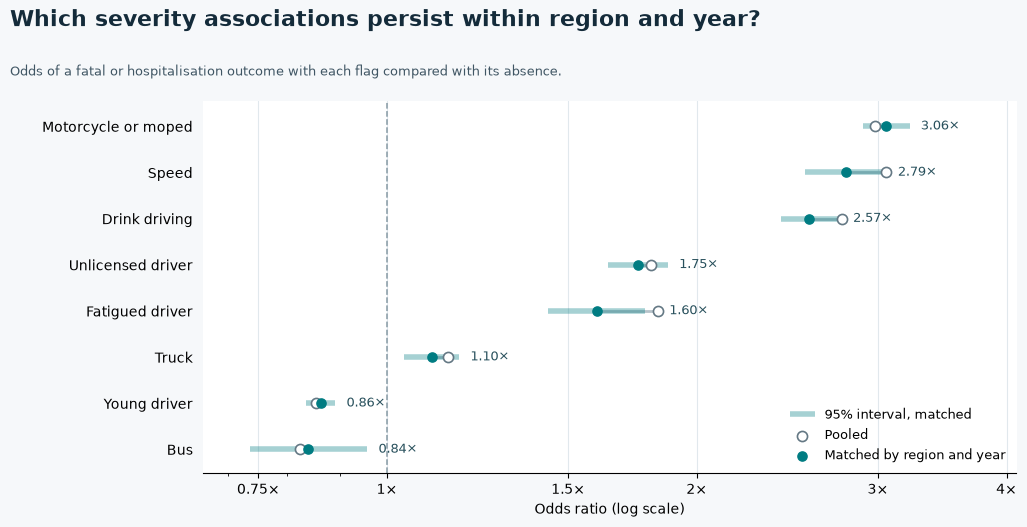

In [30]:
# Mantel–Haenszel odds ratios compare cases within the same year and police region.
association_inputs = [
    ('Factors', factor_injury, 'Involving_Driver_Speed', 'Speed'),
    ('Factors', factor_injury, 'Involving_Drink_Driving', 'Drink driving'),
    ('Factors', factor_injury, 'Involving_Fatigued_Driver', 'Fatigued driver'),
    ('Vehicles', vehicle_injury, vehicle_flags['Motorcycle or moped'], 'Motorcycle or moped'),
    ('Vehicles', vehicle_injury, vehicle_flags['Truck'], 'Truck'),
    ('Vehicles', vehicle_injury, vehicle_flags['Bus'], 'Bus'),
    ('Demographics', driver_injury, 'Involving_Young_Driver_16-24', 'Young driver'),
    ('Demographics', driver_injury, 'Involving_Unlicensed_Driver', 'Unlicensed driver'),
]
# One row of results per flag.
odds_results = []
for source_name, source, flag, label in association_inputs:
    records = source.loc[
        source['Crash_Year'].isin(recent_years) & source['Police_Region'].ne('Unknown')
        & source[flag].isin(['Yes', 'No'])
    ]
    col_order = pd.MultiIndex.from_product([['Yes', 'No'], [True, False]])
    strata = records.assign(Serious=records['Crash_Severity'].isin(severe_labels)).pivot_table(
        index=group_fields, columns=[flag, 'Serious'], values='Count_Crashes', aggfunc='sum', fill_value=0,
    ).reindex(columns=col_order, fill_value=0)
    # a, b: flag present with a serious / not serious outcome. c, d: flag absent.
    a, b, c, d = strata.to_numpy(dtype=float).T
    # Keep strata in which both the flag and the outcome vary.
    usable = ((a+b)>0) & ((c+d)>0) & ((a+c)>0) & ((b+d)>0)
    totals = (a+b+c+d)[usable]
    a,b,c,d = a[usable],b[usable],c[usable],d[usable]
    adjusted_denominator = np.sum(b*c/totals)
    # Robins–Breslow–Greenland variance of the log Mantel–Haenszel odds ratio.
    r_terms, s_terms = a*d/totals, b*c/totals
    p_terms, q_terms = (a+d)/totals, (b+c)/totals
    r_sum, s_sum = r_terms.sum(), s_terms.sum()
    log_variance = (np.sum(p_terms*r_terms)/(2*r_sum**2)
                    + np.sum(p_terms*s_terms + q_terms*r_terms)/(2*r_sum*s_sum)
                    + np.sum(q_terms*s_terms)/(2*s_sum**2)) if r_sum and s_sum else np.nan
    crude_denominator = b.sum()*c.sum()
    if adjusted_denominator and crude_denominator:
        odds_results.append({
            'Source': source_name, 'Flag': label, 'Groups compared': int(usable.sum()),
            'Pooled odds ratio': a.sum()*d.sum()/crude_denominator,
            'Matched-region/year odds ratio': np.sum(a*d/totals)/adjusted_denominator,
            '95% low': np.exp(np.log(r_sum/s_sum) - 1.959964*np.sqrt(log_variance)),
            '95% high': np.exp(np.log(r_sum/s_sum) + 1.959964*np.sqrt(log_variance)),
            'Crashes with flag': int((a+b).sum()),
        })

severity_odds = pd.DataFrame(odds_results).sort_values('Matched-region/year odds ratio', ascending=False)
display(severity_odds.set_index(['Source', 'Flag']).round(2))
fig, ax = plt.subplots(figsize=(11.0, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.23, right=.97, bottom=.12, top=.81)
fig.suptitle('Which severity associations persist within region and year?',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .857, 'Odds of a fatal or hospitalisation outcome with each flag compared with its absence.',
         fontsize=9.5, color='#405664')
order = np.arange(len(severity_odds))
crude = severity_odds['Pooled odds ratio']
adjusted = severity_odds['Matched-region/year odds ratio']
ax.axvline(1, color='#879aa5', linewidth=1.1, linestyle='--')
ax.hlines(order, np.minimum(crude, adjusted), np.maximum(crude, adjusted), color='#b7c3ca', linewidth=2)
ax.hlines(order, severity_odds['95% low'], severity_odds['95% high'], color='#007c82', linewidth=4,
          alpha=.35, label='95% interval, matched', zorder=2)
ax.scatter(crude, order, facecolor='white', edgecolor='#647884', linewidth=1.2, s=53, label='Pooled', zorder=3)
ax.scatter(adjusted, order, color='#007c82', s=44, label='Matched by region and year', zorder=4)
for y, value, pooled in zip(order, adjusted, crude):
    ax.annotate(f'{value:.2f}×', (max(value, pooled, severity_odds['95% high'].iloc[y]), y), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, color='#28505c')
ax.set(xscale='log', yticks=order, yticklabels=severity_odds['Flag'],
       ylim=(len(order)-.48, -.55), xlabel='Odds ratio (log scale)')
ax.set_xlim(min(.72, float(min(crude.min(), severity_odds['95% low'].min()))*.9),
            float(max(crude.max(), severity_odds['95% high'].max()))*1.27)
ax.xaxis.set_major_locator(mticker.FixedLocator([.75, 1, 1.5, 2, 3, 4]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f'{value:g}×'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

**What this achieved.** Compared pooled and region-year-matched odds ratios for reported flags, with 95% intervals for the matched estimates. The matched fatal-or-hospitalisation odds ratios were 3.06 (2.90–3.22) for motorcycle or moped involvement and 2.79 (2.55–3.06) for recorded speed involvement. Truck involvement was 1.10 (1.04–1.18). Young-driver involvement (0.86, 0.83–0.89) and bus involvement (0.84, 0.74–0.96) were below 1, which means injury crashes with those flags were less often serious. It does not show that the flag lowers risk. Young drivers, for example, may be involved in more lower-speed urban crashes, which the grouped source files cannot separate.

## Phase 3 · Modelling

Develop the supervised severity models, screen road sites for excess serious crashes, find the association rules, and estimate adjusted odds at crash level. The models use a time-ordered split inside the stable severity window. The site screening, rules and odds describe patterns in the recorded data.

### Train the severity models

V5 fitted three four-class Random Forests on 60,000 crashes sampled from 2001–2022 and used SMOTENC resampling. Three findings from that run shape V6. SMOTENC moved the default prediction without improving the ranking of fatal crashes (fatal average precision 0.081 against 0.088 without it). The four classes are ordered, but the rest of the notebook works with serious-or-not. And the training years span the severity drift found in Phase 2.

V6 fits two binary outcomes, **fatal or hospitalisation** and **fatal**, using every injury crash in the stable window and a time-ordered split. The earliest window years train the models, the next year sets the fatal alert threshold, and the latest complete year is the test. Partial-year records are scored separately. There is no resampling. A threshold chosen on the validation year handles the rare fatal class, and the probabilities stay calibrated.

Two model types are compared on the same inputs:

- **Gradient boosting** (`HistGradientBoostingClassifier`) with native categorical handling, early stopping and no one-hot expansion.
- **Logistic regression** with one-hot categories (rare levels grouped) and scaled unit counts. A transparent baseline.

The inputs are the V5 crash, condition and road-context fields, plus crash month, police region and the seven unit counts. Crash nature, crash type and movement group describe the crash itself, so these models describe severity given the crash that occurred. They cannot be used before a crash happens.

**In this cell.** Define the inputs with fixed category sets. Split the stable window by year into training, validation and test sets, with partial years held apart. Fit gradient boosting and logistic regression for each outcome.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical = [
    'Crash_Nature', 'Crash_Type', 'Crash_Day_Of_Week', 'Crash_Speed_Limit',
    'Crash_Lighting_Condition', 'Crash_Atmospheric_Condition',
    'Crash_Road_Surface_Condition', 'Crash_Traffic_Control',
]
road_context = [
    'Loc_ABS_Remoteness', 'Crash_DCA_Group_Description', 'Crash_Roadway_Feature',
    'Crash_Road_Horiz_Align', 'Crash_Road_Vert_Align', 'Crash_Controlling_Authority',
]
added_context = ['Crash_Month', 'Loc_Police_Region']
unit_counts = list(unit_fields.values())
model_categorical = [*categorical, *road_context, *added_context]
model_numeric = ['Crash_Hour', *unit_counts]
target = 'Crash_Severity'
outcomes = {'Fatal or hospitalisation': severe_labels, 'Fatal': ['Fatal']}

# Time-ordered split inside the stable severity window; later partial years are scored separately.
train_years = [int(year) for year in stable_years[:-2]]
validation_year, test_year = int(stable_years[-2]), int(stable_years[-1])
partial_years = [int(year) for year in sorted(raw[YEAR].unique()) if year > test_year and year not in complete_years]
injury_crashes = raw.loc[raw[target].isin(injury_labels)]
# One fixed category set per field, so every split encodes a label with the same code.
category_types = {field: pd.CategoricalDtype(sorted(injury_crashes[field].fillna('Unknown').astype(str).unique()))
                  for field in model_categorical}


def predictors(frame):
    features = frame[[*model_numeric, *model_categorical]].copy()
    for field in model_categorical:
        features[field] = features[field].fillna('Unknown').astype(str).astype(category_types[field])
    features[unit_counts] = features[unit_counts].fillna(0)
    return features


def model_split(years):
    rows = injury_crashes.loc[injury_crashes[YEAR].isin(years)]
    return predictors(rows), rows[target]


X_train, y_train = model_split(train_years)
X_valid, y_valid = model_split([validation_year])
X_test, y_test = model_split([test_year])
X_partial, y_partial = model_split(partial_years)


def logistic_model():
    encoder = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30),
         [*model_categorical, 'Crash_Hour']),
        ('units', StandardScaler(), unit_counts),
    ])
    return Pipeline([('encode', encoder), ('logistic', LogisticRegression(C=1.0, max_iter=3000))])


def boosting_model():
    return HistGradientBoostingClassifier(
        categorical_features='from_dtype', learning_rate=.05, max_iter=800, max_leaf_nodes=31,
        min_samples_leaf=40, l2_regularization=1.0, early_stopping=True, validation_fraction=.15,
        n_iter_no_change=40, random_state=SEED,
    )


model_builders = {'Logistic regression': logistic_model, 'Gradient boosting': boosting_model}
fitted_models = {}
for outcome, levels in outcomes.items():
    for label, build in model_builders.items():
        fitted_models[(outcome, label)] = build().fit(X_train, y_train.isin(levels))

print(f"Training {train_years[0]}–{train_years[-1]}: {len(X_train):,} injury crashes | validation {validation_year}: "
      f"{len(X_valid):,} | test {test_year}: {len(X_test):,} | partial {partial_years}: {len(X_partial):,}")
print(f"Inputs: {len(model_categorical)} categorical fields, crash hour and {len(unit_counts)} unit counts.")
for (outcome, label), model in fitted_models.items():
    if label == 'Gradient boosting':
        print(f"{outcome} · gradient boosting stopped after {model.n_iter_} iterations.")

Training 2020–2022: 38,644 injury crashes | validation 2023: 13,622 | test 2024: 14,358 | partial [2025]: 7,029
Inputs: 16 categorical fields, crash hour and 7 unit counts.
Fatal or hospitalisation · gradient boosting stopped after 136 iterations.
Fatal · gradient boosting stopped after 154 iterations.


**What this achieved.** Trained on every injury crash from 2020–2022 (38,644), compared with V5's sample of 60,000 from 2001–2022. Validation is 2023 (13,622 crashes), the test is 2024 (14,358) and the partial 2025 records (7,029) are scored apart. Each outcome has a gradient-boosting model (early stopping after 136 and 154 iterations) and a logistic regression on the same 16 categorical fields, crash hour and seven unit counts.

### Screen road sites for excess serious crashes

V5 found serious-crash hotspots with DBSCAN and showed the problem with ranking by count: the 100 grid cells with the most serious crashes in 2015–2019 recorded 0.61 times as many in 2020–2024, while all cells rose 1.19 times. A count ranking also favours busy sites, rewarding volume as much as risk.

V6 screens road sites by **excess serious crashes**, following the excess proportion of specific crash types method in the Highway Safety Manual network-screening chapter. It needs no traffic volumes. For each site:

1. **Sites.** Each crash goes to a site on the Queensland road network (`traffic_road_sites.py`). Crashes coded at an intersection go to the nearest mapped junction within 40 m, with junction nodes within 25 m merged. Other crashes go to the nearest road link within 30 m. A link is a run of same-named segments between junctions.
2. **Expected serious crashes.** Each crash's expected chance of a serious outcome is the statewide share for its **year**, site type, speed zone and remoteness area. Including the year means the severity drift found in Phase 2 cancels out. A site's expected count is the sum over its crashes.
3. **Shrinkage.** Sites with few crashes have noisy shares, so the observed excess is shrunk towards zero by n ÷ (n + k). Here n is the site's injury crashes and k comes from the overdispersion across all sites (method of moments, beta-binomial). The ranking uses this empirical-Bayes excess.

The screen uses the latest ten complete years and observed coordinates only. It counts **stacked coordinates**, points shared by ten or more crash records. At junctions these are expected, because intersection crashes are usually geocoded to the intersection point. On a link they would suggest snapping to a reference point. Each site reports its distinct crash points and stacked crashes so this can be checked.

**In this cell.** Load the cached junction and link network, take observed injury crashes from the screening years, flag stacked coordinates, and assign each crash to a junction or link. Report how many crashes found a site.

In [32]:
from traffic_road_sites import (JUNCTION_SNAP_M, LINK_SNAP_M, assign_sites, load_network, site_geometry_lonlat,
                                site_label)

road_network = load_network(SPATIAL_DIR / 'roads.geojson.gz', cache_dir=CACHE_DIR)
print(f"Road network: {road_network.source_features:,} source segments → {road_network.link.max() + 1:,} links "
      f"and {len(road_network.junction_xy):,} junctions.")

STACKED_MINIMUM = 10
screen_years = complete_years[complete_years > last_pdo_year][-10:]
observed_crashes = cleaned.loc[cleaned['Coordinate_Method'].eq('observed')]
# How many crash records (any year or severity) share each exact coordinate pair.
point_counts = observed_crashes.groupby(COORDS).size().rename('Crashes at this exact point')
screen_points = observed_crashes.loc[
    observed_crashes['Crash_Severity'].isin(injury_labels) & observed_crashes['Crash_Year'].isin(screen_years)
].join(point_counts, on=COORDS)
screen_points['Stacked point'] = screen_points['Crashes at this exact point'].ge(STACKED_MINIMUM)
at_intersection = screen_points['Crash_Roadway_Feature'].str.startswith('Intersection', na=False)
site_assignment = assign_sites(road_network, screen_points['Crash_Longitude'], screen_points['Crash_Latitude'],
                               at_intersection).set_index(screen_points.index)
screen_points = screen_points.join(site_assignment)
screen_points['x'], screen_points['y'] = FORWARD(screen_points['Crash_Longitude'].to_numpy(),
                                                 screen_points['Crash_Latitude'].to_numpy())

assignment_summary = pd.DataFrame({
    'Injury crashes': screen_points['Site type'].fillna('No site within range').value_counts(),
}).assign(**{'Share (%)': lambda frame: 100 * frame['Injury crashes'] / len(screen_points)})
display(assignment_summary.round(1))
print(f"Screening years {screen_years.min()}–{screen_years.max()}: {len(screen_points):,} observed injury crashes. "
      f"Intersection-coded crashes placed at a junction within {JUNCTION_SNAP_M} m: "
      f"{(screen_points.loc[at_intersection, 'Site type'] == 'Junction').mean():.1%}. "
      f"Crashes on stacked points (≥{STACKED_MINIMUM} records at one coordinate): {int(screen_points['Stacked point'].sum()):,}.")

Road network: 564,950 source segments → 513,336 links and 251,021 junctions.


,Injury crashes,Share (%)
Site type,,
Link,73291,56.4
Junction,55852,43.0
No site within range,851,0.7


Screening years 2015–2024: 129,994 observed injury crashes. Intersection-coded crashes placed at a junction within 40 m: 96.2%. Crashes on stacked points (≥10 records at one coordinate): 7,879.


**What this achieved.** Built 513,336 road links and 251,021 junctions from 564,950 road segments. Of 129,994 observed injury crashes in 2015–2024, 56.4% went to a link, 43.0% to a junction and 0.7% found no site within range. 96.2% of intersection-coded crashes reached a junction within 40 m. 7,879 crashes sit on stacked coordinates.

#### Rank sites by empirical-Bayes excess

**In this cell.** Give every assigned crash its expected serious probability from the year, site type, speed zone and remoteness strata. Sum by site, estimate the overdispersion and shrinkage constant k, and rank sites with at least five injury crashes by shrunk excess. Label each site with its road names, most common suburb, extent, stacked-point count and year range.

In [33]:
SCREEN_STRATA = ['Crash_Year', 'Site type', 'Crash_Speed_Limit', 'Loc_ABS_Remoteness']
SITE_MINIMUM = 5
assigned = screen_points.loc[screen_points['Site'].notna()].copy()
assigned['Serious'] = assigned['Crash_Severity'].isin(severe_labels)
assigned['Fatal'] = assigned['Crash_Severity'].eq('Fatal')
# Statewide serious share for the crash's year and setting. Year-specific shares absorb the severity drift.
assigned['Expected'] = assigned.groupby(SCREEN_STRATA, dropna=False)['Serious'].transform('mean')
assigned['Variance'] = assigned['Expected'] * (1 - assigned['Expected'])
assigned['Point'] = assigned['Crash_Latitude'].round(6).astype(str) + ',' + assigned['Crash_Longitude'].round(6).astype(str)


def most_common(values):
    values = values.dropna()
    return values.mode().iat[0] if len(values) else pd.NA


def site_totals(frame):
    groups = frame.groupby('Site')
    table = groups.agg(**{
        'Site type': ('Site type', 'first'), 'Site number': ('Site number', 'first'),
        'Injury crashes': ('Serious', 'size'), 'Serious crashes': ('Serious', 'sum'),
        'Fatal crashes': ('Fatal', 'sum'), 'Fatalities': ('Count_Casualty_Fatality', 'sum'),
        'Expected serious': ('Expected', 'sum'), 'Variance': ('Variance', 'sum'),
    })
    table[['Serious crashes', 'Fatal crashes', 'Fatalities']] = table[['Serious crashes', 'Fatal crashes',
                                                                       'Fatalities']].astype(int)
    return table


def overdispersion(table):
    """Method-of-moments intra-site correlation of serious outcomes beyond the binomial (beta-binomial ρ)."""
    usable = table.loc[table['Injury crashes'].ge(2)]
    excess_variance = ((usable['Serious crashes'] - usable['Expected serious']) ** 2 - usable['Variance']).sum()
    return float(np.clip(excess_variance / (usable['Variance'] * (usable['Injury crashes'] - 1)).sum(), 1e-4, .5))


def add_excess(table, rho):
    k = (1 - rho) / rho
    n = table['Injury crashes']
    table['Excess serious crashes'] = table['Serious crashes'] - table['Expected serious']
    table['Shrunk excess serious crashes'] = table['Excess serious crashes'] * n / (n + k)
    table['Serious share (%)'] = 100 * table['Serious crashes'] / n
    table['Expected share (%)'] = 100 * table['Expected serious'] / n
    table['Shrunk serious share (%)'] = 100 * (table['Serious crashes'] + k * table['Expected serious'] / n) / (n + k)
    table['z'] = table['Excess serious crashes'] / np.sqrt(table['Variance'] * (1 + (n - 1) * rho))
    return table


sites = site_totals(assigned)
site_rho = overdispersion(sites)
site_k = (1 - site_rho) / site_rho
sites = add_excess(sites, site_rho)
assert np.isclose(sites['Expected serious'].sum(), assigned['Serious'].sum())

# Labels and descriptive fields for ranked sites.
groups = assigned.groupby('Site')
sites['Distinct crash points'] = groups['Point'].nunique()
sites['Crashes on stacked points'] = groups['Stacked point'].sum().astype(int)
sites['Motorcycle crashes (%)'] = 100 * groups['Count_Unit_Motorcycle_Moped'].agg(lambda units: units.fillna(0).gt(0).mean())
sites['Suburb'] = groups['Loc_Suburb'].agg(most_common)
sites['Police region'] = groups['Loc_Police_Region'].agg(most_common)
sites['Council area'] = groups['Loc_Local_Government_Area'].agg(most_common)
sites['First year'] = groups['Crash_Year'].min()
sites['Last year'] = groups['Crash_Year'].max()
extent = groups[['x', 'y']].agg(['min', 'max'])
sites['Extent (m)'] = np.hypot(extent[('x', 'max')] - extent[('x', 'min')],
                               extent[('y', 'max')] - extent[('y', 'min')]).round().astype(int)
sites['Latitude'] = groups['Crash_Latitude'].median()
sites['Longitude'] = groups['Crash_Longitude'].median()
sites['Road names'] = [site_label(road_network, kind, number)
                       for kind, number in zip(sites['Site type'], sites['Site number'])]
road_parts = sites['Road names'].str.split(' / ', n=1, expand=True)
sites['Main street'] = road_parts[0]
sites['Intersecting street'] = road_parts[1] if 1 in road_parts else pd.NA
sites['Link length (m)'] = np.where(sites['Site type'].eq('Link'),
                                    road_network.link_length_m[sites['Site number'].clip(lower=0)].round(), np.nan)
junction_rows = sites['Site type'].eq('Junction')
junction_lon, junction_lat = INVERSE(*road_network.junction_xy[sites.loc[junction_rows, 'Site number']].T)
sites.loc[junction_rows, 'Longitude'], sites.loc[junction_rows, 'Latitude'] = junction_lon, junction_lat

screen_period = f'{int(screen_years.min())}–{int(screen_years.max())}'
ranked_sites = (sites.loc[sites['Injury crashes'].ge(SITE_MINIMUM)]
                .sort_values(['Shrunk excess serious crashes', 'Fatal crashes'], ascending=False))
hotspots = ranked_sites.reset_index().rename(columns={'Site': 'Site ID'})
hotspots.index = pd.RangeIndex(1, len(hotspots) + 1, name='Rank')
hotspot_columns = ['Site ID', 'Site type', 'Road names', 'Suburb', 'Police region', 'Injury crashes', 'Serious crashes',
                   'Expected serious', 'Shrunk excess serious crashes', 'Serious share (%)', 'Expected share (%)',
                   'Fatal crashes', 'Motorcycle crashes (%)', 'Distinct crash points', 'Crashes on stacked points', 'Extent (m)']
print(f"{len(sites):,} sites with at least one injury crash; {len(ranked_sites):,} with {SITE_MINIMUM} or more. "
      f"Overdispersion ρ = {site_rho:.4f}, shrinkage constant k = {site_k:.1f} crashes.")
display(hotspots[hotspot_columns].head(20).round(1))
count_ranked = sites.sort_values(['Serious crashes', 'Fatal crashes'], ascending=False)
statewide_motorcycle = 100 * assigned['Count_Unit_Motorcycle_Moped'].fillna(0).gt(0).mean()
print(f"Motorcycle share of screened crashes: {statewide_motorcycle:.1f}% statewide; "
      f"{hotspots.head(20).query('`Site type` == \"Link\"')['Motorcycle crashes (%)'].mean():.1f}% on average across the top-20 links, "
      f"{hotspots.head(100)['Motorcycle crashes (%)'].mean():.1f}% across the top 100 sites.")
print(f"Sites in both the top 100 by shrunk excess and the top 100 by serious-crash count: "
      f"{int(hotspots['Site ID'].head(100).isin(count_ranked.index[:100]).sum())}.")

55,943 sites with at least one injury crash; 5,645 with 5 or more. Overdispersion ρ = 0.0446, shrinkage constant k = 21.4 crashes.


,Site ID,Site type,Road names,Suburb,Police region,Injury crashes,Serious crashes,Expected serious,Shrunk excess serious crashes,Serious share (%),Expected share (%),Fatal crashes,Motorcycle crashes (%),Distinct crash points,Crashes on stacked points,Extent (m)
Rank,,,,,,,,,,,,,,,,
1,L110443,Link,Beechmont Road,Advancetown,South Eastern,37,31,16.8,9.0,83.8,45.5,2,59.5,37,0,3039
2,L85688,Link,Mt Mee Road,Delaneys Creek,North Coast,44,35,24.2,7.3,79.5,55.0,1,75.0,44,0,2622
3,J19927,Junction,Mulgrave Road / Florence Street,Parramatta Park,Far Northern,33,26,17.2,5.3,78.8,52.2,0,3.0,7,21,41
4,L110386,Link,Beaudesert - Nerang Road,Witheren,South Eastern,46,35,27.4,5.2,76.1,59.5,1,17.4,45,0,3401
5,L83247,Link,West Mount Cotton Road,Cornubia,Brisbane,19,18,7.5,4.9,94.7,39.4,0,42.1,19,0,853
6,L301333,Link,Warrego Highway,Karalee,Southern,33,20,13.6,3.9,60.6,41.1,1,9.1,33,0,3884
7,L1483,Link,Bruce Highway,Rosemount,North Coast,37,21,15.0,3.8,56.8,40.5,1,2.7,37,0,5827
8,L89858,Link,Bruce Highway,Burpengary East,North Coast,57,28,23.0,3.7,49.1,40.3,0,3.5,55,0,2035
9,L24370,Link,Bribie Island Road,Caboolture,North Coast,33,21,15.0,3.6,63.6,45.5,1,9.1,33,0,2283


Motorcycle share of screened crashes: 12.1% statewide; 33.0% on average across the top-20 links, 16.1% across the top 100 sites.
Sites in both the top 100 by shrunk excess and the top 100 by serious-crash count: 52.


**What this achieved.** Screened 55,943 sites. 5,645 have five or more injury crashes and are ranked. The overdispersion gives k = 21.4, so a site's raw excess is weighted n ÷ (n + 21.4). A site with 21 crashes keeps about half its raw excess, and one with 5 keeps about a fifth. Only 52 of the top 100 by excess are also in the top 100 by serious count.

The top 100 split almost evenly between junctions (51) and links (49):
- **Links.** The top-ranked links are mostly rural and peri-urban roads that a count ranking would not list. The leader is a 4.3 km link of **Beechmont Road, Advancetown** (31 serious of 37 injury crashes against 16.8 expected), followed by **Mt Mee Road**. Many of these links are recreational motorcycle routes. Motorcycles were involved in 33% of crashes on the top-20 links, against 12% statewide: 60% on Beechmont Road, 75% on Mt Mee Road and 86% on Northbrook Parkway. Expected shares allow for setting but not for road users, so much of these links' excess reflects who crashes there. Read them as motorcycle-safety sites as much as road-design sites.
- **Junctions.** The top junctions are mostly urban, led by **Mulgrave Road / Florence Street** in Cairns, which was also a top-five V5 DBSCAN hotspot. Stacked coordinates appear only at junctions: 37 of the 51 top junctions have them, holding 55% of their crashes, and no top link has any. That matches intersection crashes being geocoded to the intersection point. It does not mean the V5 hotspots were artefacts.

#### Do the ranked sites stay high in the next period?

Repeat V5's persistence test with sites in place of grid cells. Split the screening years into two five-year periods. Rank sites in the earlier period three ways: by serious-crash count (V5's criterion), by raw excess, and by shrunk excess. Then look at what the same sites record in the later period. Each period's expected counts come from its own year-specific shares, so the severity drift does not enter. A ranking that captures real site effects keeps its excess in the later period. A ranking that captures noise sees its excess collapse towards zero.

The calibration chart groups sites by their earlier-period estimate of excess serious share and compares it with the excess share the same sites recorded later. A calibrated estimate sits on the diagonal.

**In this cell.** Recompute site totals, overdispersion and shrinkage separately for each five-year period. For each earlier-period ranking, take the top 100 sites and compare their earlier and later serious crashes and excess. Plot earlier raw and shrunk excess shares against later excess shares by decile.

,Serious crashes 2015–2019,Serious crashes 2020–2024,Excess serious 2015–2019,Shrunk excess 2015–2019,Excess serious 2020–2024,Later ÷ earlier serious crashes,Later excess ÷ earlier raw excess,Later excess ÷ earlier shrunk excess,Still in later top 100
Earlier ranking,,,,,,,,,
Serious-crash count (V5 criterion),943,643,204.79,77.37,-3.45,0.68,-0.02,-0.04,29
Raw excess,746,416,327.00,106.95,50.41,0.56,0.15,0.47,12
Shrunk excess (empirical Bayes),832,494,305.71,113.46,45.48,0.59,0.15,0.40,17


All sites: 32,988 serious crashes in 2020–2024 against 27,646 in 2015–2019 (1.19×).


,Sites,Crashes,Excess,Pooled excess share (pp)
"Injury crashes at site, 2015–2019",,,,
1,23436,23436,745.16,3.18
2,5637,11274,42.86,0.38
3–4,3393,11332,-240.60,-2.12
5–9,1667,10488,-296.47,-2.83
10–19,401,5159,-157.17,-3.05
20+,48,1274,-93.78,-7.36


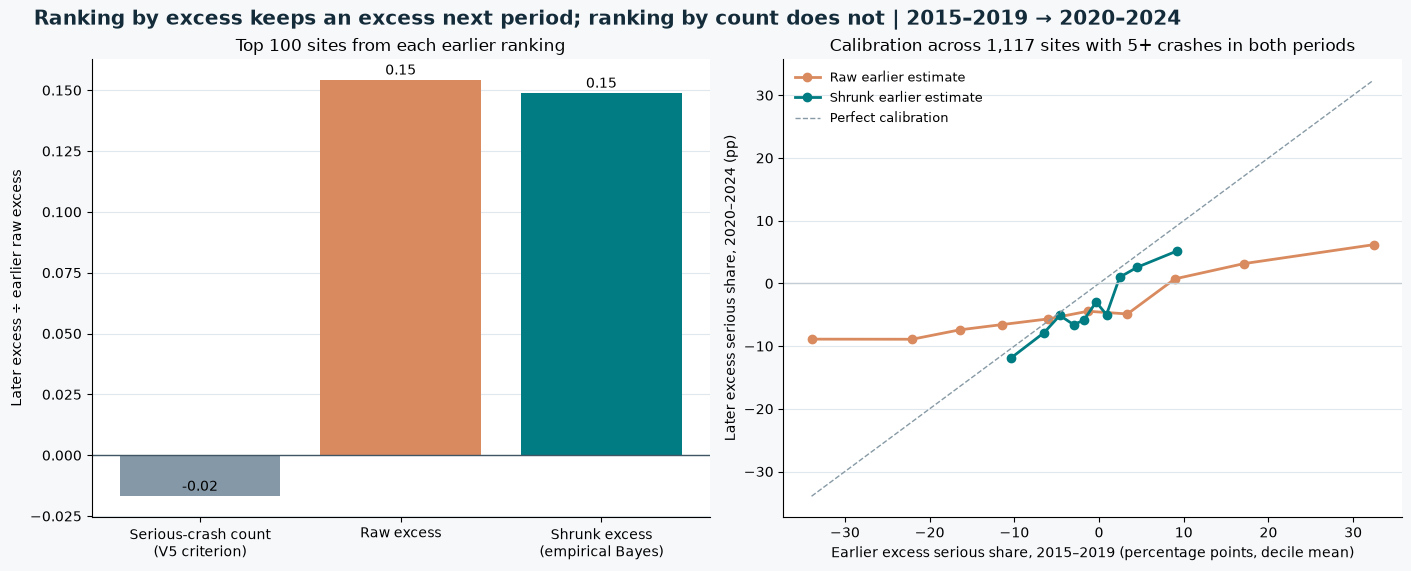

Raw earlier excess share                   Shrunk earlier excess share  \
     Earlier estimate (pp) Later excess (pp)       Earlier estimate (pp)   
0                   -33.94             -8.89                      -10.37   
1                   -22.07             -8.91                       -6.47   
2                   -16.46             -7.41                       -4.63   
3                   -11.48             -6.57                       -3.01   
4                    -5.99             -5.66                       -1.80   
5                    -1.31             -4.44                       -0.35   
6                     3.35             -4.88                        0.88   
7                     8.95              0.72                        2.44   
8                    17.09              3.15                        4.53   
9                    32.41              6.17                        9.20   

                     
  Later excess (pp)  
0            -11.87  
1             -7.84  
2             -5.11  
3             -6.58  
4             -5.87  
5             -2.97  
6             -4.98  
7              0.99  
8              2.59  
9              5.16

In [34]:
TOP_SITES = 100
earlier_years, later_years = screen_years[:5], screen_years[5:]
assert earlier_years.min() > last_pdo_year and len(later_years) == 5
earlier_label = f'{int(earlier_years.min())}–{int(earlier_years.max())}'
later_label = f'{int(later_years.min())}–{int(later_years.max())}'
period_sites = {}
for label, years in [('Earlier', earlier_years), ('Later', later_years)]:
    table = site_totals(assigned.loc[assigned['Crash_Year'].isin(years)])
    period_sites[label] = add_excess(table, overdispersion(table))
earlier, later = period_sites['Earlier'], period_sites['Later']
later_aligned = later.reindex(earlier.index).fillna({'Injury crashes': 0, 'Serious crashes': 0,
                                                     'Expected serious': 0, 'Excess serious crashes': 0})

persistence_rows = []
rankings = {'Serious-crash count (V5 criterion)': 'Serious crashes', 'Raw excess': 'Excess serious crashes',
            'Shrunk excess (empirical Bayes)': 'Shrunk excess serious crashes'}
for label, column in rankings.items():
    top = earlier.sort_values([column, 'Serious crashes'], ascending=False).head(TOP_SITES).index
    later_top = later.sort_values([column, 'Serious crashes'], ascending=False).head(TOP_SITES).index
    persistence_rows.append({
        'Earlier ranking': label,
        f'Serious crashes {earlier_label}': int(earlier.loc[top, 'Serious crashes'].sum()),
        f'Serious crashes {later_label}': int(later_aligned.loc[top, 'Serious crashes'].sum()),
        f'Excess serious {earlier_label}': earlier.loc[top, 'Excess serious crashes'].sum(),
        f'Shrunk excess {earlier_label}': earlier.loc[top, 'Shrunk excess serious crashes'].sum(),
        f'Excess serious {later_label}': later_aligned.loc[top, 'Excess serious crashes'].sum(),
        'Later ÷ earlier serious crashes': later_aligned.loc[top, 'Serious crashes'].sum()
                                            / earlier.loc[top, 'Serious crashes'].sum(),
        'Later excess ÷ earlier raw excess': later_aligned.loc[top, 'Excess serious crashes'].sum()
                                             / earlier.loc[top, 'Excess serious crashes'].sum(),
        'Later excess ÷ earlier shrunk excess': later_aligned.loc[top, 'Excess serious crashes'].sum()
                                                / earlier.loc[top, 'Shrunk excess serious crashes'].sum(),
        f'Still in later top {TOP_SITES}': int(pd.Index(top).isin(later_top).sum()),
    })
persistence = pd.DataFrame(persistence_rows).set_index('Earlier ranking')
statewide_ratio = later['Serious crashes'].sum() / earlier['Serious crashes'].sum()
display(persistence.round(2))
print(f"All sites: {later['Serious crashes'].sum():,} serious crashes in {later_label} against "
      f"{earlier['Serious crashes'].sum():,} in {earlier_label} ({statewide_ratio:.2f}×).")

# Calibration by decile, sites with enough crashes in both periods to measure a later share.
# Both sides are pooled over the decile's crashes: excess serious crashes ÷ injury crashes.
both = earlier.index[earlier['Injury crashes'].ge(SITE_MINIMUM) & later_aligned['Injury crashes'].ge(SITE_MINIMUM)]
calibration_frame = pd.DataFrame({
    'Earlier crashes': earlier.loc[both, 'Injury crashes'],
    'Earlier raw excess': earlier.loc[both, 'Excess serious crashes'],
    'Earlier shrunk excess': earlier.loc[both, 'Shrunk excess serious crashes'],
    'Later crashes': later_aligned.loc[both, 'Injury crashes'],
    'Later excess': later_aligned.loc[both, 'Excess serious crashes'],
})
calibration_points = {}
for estimate, column in [('Raw earlier excess share', 'Earlier raw excess'),
                         ('Shrunk earlier excess share', 'Earlier shrunk excess')]:
    share = calibration_frame[column] / calibration_frame['Earlier crashes']
    grouped = calibration_frame.groupby(pd.qcut(share.rank(method='first'), 10, labels=False))
    calibration_points[estimate] = pd.DataFrame({
        'Earlier estimate (pp)': 100 * grouped[column].sum() / grouped['Earlier crashes'].sum(),
        'Later excess (pp)': 100 * grouped['Later excess'].sum() / grouped['Later crashes'].sum(),
    })

# Mean excess share by site size: sites that collect many crashes sit below their strata's expected share.
size_bands = pd.cut(earlier['Injury crashes'], [0, 1, 2, 4, 9, 19, np.inf], labels=['1', '2', '3–4', '5–9', '10–19', '20+'])
size_table = earlier.groupby(size_bands, observed=True).agg(
    Sites=('Injury crashes', 'size'), Crashes=('Injury crashes', 'sum'), Excess=('Excess serious crashes', 'sum'))
size_table['Pooled excess share (pp)'] = 100 * size_table['Excess'] / size_table['Crashes']
display(size_table.rename_axis(f'Injury crashes at site, {earlier_label}').round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Ranking by excess keeps an excess next period; ranking by count does not | '
             f'{earlier_label} → {later_label}', x=.02, ha='left', fontsize=14.5, fontweight='bold', color='#142b3a')
bar_colors = ['#8498a7', '#d98b5f', '#007c82']
axes[0].bar(range(3), persistence['Later excess ÷ earlier raw excess'], color=bar_colors)
for x, value in enumerate(persistence['Later excess ÷ earlier raw excess']):
    axes[0].annotate(f'{value:.2f}', (x, value), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=10)
axes[0].axhline(0, color='#405664', lw=1)
axes[0].set(xticks=range(3), xticklabels=[label.replace(' (', '\n(') for label in persistence.index],
            ylabel='Later excess ÷ earlier raw excess', title=f'Top {TOP_SITES} sites from each earlier ranking')
for (estimate, points), color in zip(calibration_points.items(), ['#d98b5f', '#007c82']):
    axes[1].plot(points['Earlier estimate (pp)'], points['Later excess (pp)'], marker='o', color=color, lw=2,
                 label=estimate.replace(' earlier excess share', ' earlier estimate'))
span = [float(min(p.min().min() for p in calibration_points.values())),
        float(max(p.max().max() for p in calibration_points.values()))]
axes[1].plot(span, span, color='#879aa5', ls='--', lw=1, label='Perfect calibration')
axes[1].axhline(0, color='#c3cdd4', lw=1)
axes[1].set(xlabel=f'Earlier excess serious share, {earlier_label} (percentage points, decile mean)',
            ylabel=f'Later excess serious share, {later_label} (pp)',
            title=f'Calibration across {len(both):,} sites with {SITE_MINIMUM}+ crashes in both periods')
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()
display(pd.concat(calibration_points, axis=1).round(2))

**What this achieved.** The comparison supports moving away from count ranking. It also shows what the shrinkage still gets wrong.
- **Count ranking (V5).** The top 100 sites by serious count in 2015–2019 had an excess of 205 serious crashes in that period and −3 in 2020–2024. Their high counts reflect traffic volume, not risk, and the excess disappears completely.
- **Excess ranking.** The top 100 by raw excess and by shrunk excess still had 50 and 45 serious crashes above expected in 2020–2024. These sites have persistent severity problems, about 15% of their earlier raw excess. Shrinkage did not improve the ranking itself: both lists kept the same share of their excess, and the shrunk list kept 17 of its top 100 against 12.
- **Calibration.** The shrunk estimates are much better calibrated. Pooled by decile, raw earlier estimates span −34 to +32 points but later shares only −9 to +6. Shrunk estimates span −10 to +9 points and track the later shares with a slope close to one, about 3–4 points too high throughout.
- **Why the offset.** The size-band table explains it. The more crashes a site collects, the further it sits below its stratum's expected share: +3.2 points for one-crash sites, −2.8 for 5–9 crashes and −7.4 for 20 or more. Busy sites have less severe crashes than quieter sites in the same year, setting, speed zone and remoteness. The shrinkage strength (k) is about right. What's off is the reference it shrinks towards.

The next step is to add site crash frequency, or traffic volume once available, to the strata, so each site is compared with sites of similar activity. Until then, the ranking order is usable, but the excess numbers for busy sites are understated and for quiet sites overstated.

**In this cell.** Map the 150 highest-ranked sites on the Esri basemap. Junctions are circles sized by injury crashes, links are drawn along the road, and colour shows the shrunk excess serious share. Each tooltip gives the rank, roads, suburb, counts, expected count, shrunk excess, fatal crashes and stacked-point count.

In [35]:
from branca.colormap import LinearColormap

MAP_SITES = 150
map_sites = hotspots.head(MAP_SITES)
excess_share = map_sites['Shrunk serious share (%)'] - map_sites['Expected share (%)']
site_scale = LinearColormap(['#f2c18d', '#d4682a', '#8e1f1f'], vmin=float(excess_share.min()),
                            vmax=float(excess_share.max()),
                            caption='Shrunk excess serious share (percentage points above expected)')
hotspot_map = folium.Map(location=[-27.47, 153.03], zoom_start=10, tiles='Esri.WorldStreetMap', control_scale=True)
layers = {kind: folium.FeatureGroup(name=f'{kind}s (top {MAP_SITES} sites overall)').add_to(hotspot_map)
          for kind in ['Junction', 'Link']}
for rank, row in map_sites.iterrows():
    colour = site_scale(row['Shrunk serious share (%)'] - row['Expected share (%)'])
    tooltip = (f"#{rank} · {escape(str(row['Road names']))}, {escape(str(row['Suburb']))}<br>"
               f"{row['Site type']} · {row['Injury crashes']} injury crashes, {row['Serious crashes']} serious "
               f"(expected {row['Expected serious']:.1f})<br>Shrunk excess {row['Shrunk excess serious crashes']:.1f} "
               f"serious crashes · {row['Fatal crashes']} fatal · {screen_period}"
               + (f"<br>{row['Crashes on stacked points']} crashes on stacked coordinates"
                  if row['Crashes on stacked points'] else ''))
    if row['Site type'] == 'Junction':
        folium.CircleMarker([row['Latitude'], row['Longitude']], radius=4 + row['Injury crashes'] ** .5,
                            color=colour, weight=1.2, fill=True, fill_opacity=.75, tooltip=tooltip
                            ).add_to(layers['Junction'])
    else:
        geometry = site_geometry_lonlat(road_network, 'Link', int(row['Site number']))
        folium.GeoJson(mapping(geometry), style_function=lambda _, colour=colour: {'color': colour, 'weight': 6,
                                                                                    'opacity': .85},
                       tooltip=folium.Tooltip(tooltip)).add_to(layers['Link'])
site_scale.add_to(hotspot_map)
folium.LayerControl(collapsed=False).add_to(hotspot_map)
display(hotspot_map)
display(map_sites['Police region'].value_counts().rename(f'Top {MAP_SITES} sites').to_frame())

,Top 150 sites
Police region,
South Eastern,50
Brisbane,38
North Coast,36
Southern,15
Far Northern,6
Central,3
Northern,2


**What this achieved.** Mapped the 150 highest-ranked sites. Junctions are circles and links follow the road. South Eastern (50), Brisbane (38) and North Coast (36) police regions hold most of them. The map replaces the V5 DBSCAN hotspot view on the Esri map page.

### Find combinations associated with serious outcomes

Use Apriori on injury crashes in the stable severity window to find combinations of up to two recorded conditions that often occur with a fatal or hospitalisation outcome. V5 pooled every year from 2001, so its baseline mixed coding periods. The items cover crash nature, lighting, speed zone, remoteness area, roadway feature, horizontal alignment and traffic control. A combination and outcome must appear together in at least 0.5% of injury crashes, with at least 60% confidence. Rules are ranked by lift, which compares the serious share among crashes matching the rule with the serious share among all injury crashes in the window.

The rules describe co-occurrence in recorded injury crashes.

**In this cell.** Encode recorded crash characteristics as indicator variables, add the serious-outcome indicator, and use Apriori to find frequent combinations. Keep rules whose consequent is the serious outcome, filter by support and confidence, and rank them by lift.

In [36]:
from mlxtend.frequent_patterns import apriori, association_rules

rule_fields = [
    'Crash_Nature', 'Crash_Lighting_Condition', 'Crash_Speed_Limit', 'Loc_ABS_Remoteness',
    'Crash_Roadway_Feature', 'Crash_Road_Horiz_Align', 'Crash_Traffic_Control',
]
serious_outcome = 'Outcome = Fatal or hospitalisation'
# Stable severity window only, so the outcome definition is consistent across the crashes compared.
rule_records = cleaned.loc[cleaned['Crash_Severity'].isin(injury_labels)
                           & cleaned['Crash_Year'].isin(stable_years)]
# One indicator column per field value, plus the outcome indicator in the first column.
transactions = pd.get_dummies(rule_records[rule_fields].fillna('Unknown'), prefix_sep=' = ', dtype=bool)
transactions.insert(0, serious_outcome, rule_records['Crash_Severity'].isin(severe_labels).to_numpy())
serious_baseline = transactions[serious_outcome].mean()
itemsets = apriori(transactions, min_support=.005, use_colnames=True, max_len=3, low_memory=True)
rules = association_rules(
    itemsets, num_itemsets=len(transactions), metric='confidence', min_threshold=.60
)
# Keep rules that predict the serious outcome and rank them by lift.
severity_rules = rules.loc[rules['consequents'].map(lambda items: items == frozenset({serious_outcome}))
                           ].sort_values(['lift', 'support'], ascending=False)
rule_table = severity_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(12).copy()
for column in ['antecedents', 'consequents']:
    rule_table[column] = rule_table[column].map(lambda items: ' + '.join(sorted(items)))
rule_table.insert(2, 'serious crashes', (rule_table['support'] * len(transactions)).round().astype(int))
print(f"{len(transactions):,} injury crashes, {stable_years.min()}–{stable_years.max()} | serious share {serious_baseline:.1%} | "
      f"{len(severity_rules)} rules meet the thresholds")
display(rule_table.round(3).reset_index(drop=True))

66,624 injury crashes, 2020–2024 | serious share 49.9% | 136 rules meet the thresholds


,antecedents,consequents,serious crashes,support,confidence,lift
0,Crash_Nature = Head-on + Crash_Speed_Limit = 1...,Outcome = Fatal or hospitalisation,434,0.007,0.849,1.703
1,Crash_Nature = Head-on + Loc_ABS_Remoteness = ...,Outcome = Fatal or hospitalisation,344,0.005,0.791,1.586
2,Crash_Speed_Limit = 100 - 110 km/h + Loc_ABS_R...,Outcome = Fatal or hospitalisation,404,0.006,0.788,1.579
3,Crash_Speed_Limit = 100 - 110 km/h + Loc_ABS_R...,Outcome = Fatal or hospitalisation,536,0.008,0.775,1.553
4,Crash_Roadway_Feature = No Roadway Feature + L...,Outcome = Fatal or hospitalisation,527,0.008,0.770,1.545
5,Crash_Traffic_Control = No traffic control + L...,Outcome = Fatal or hospitalisation,588,0.009,0.760,1.523
6,Crash_Nature = Fall from vehicle + Loc_ABS_Rem...,Outcome = Fatal or hospitalisation,561,0.008,0.754,1.512
7,Crash_Roadway_Feature = No Roadway Feature + L...,Outcome = Fatal or hospitalisation,668,0.010,0.753,1.510
8,Crash_Traffic_Control = No traffic control + L...,Outcome = Fatal or hospitalisation,770,0.012,0.752,1.508
9,Crash_Road_Horiz_Align = Straight + Loc_ABS_Re...,Outcome = Fatal or hospitalisation,448,0.007,0.750,1.505


**What this achieved.** Ranked Apriori rules on the 66,624 injury crashes of 2020–2024, where 49.9% were serious. V5's all-years baseline was 42.6%. 136 rules met the thresholds. The leading rule is still head-on crashes in 100–110 km/h zones (84.9% serious, 434 serious crashes, lift 1.70). Remoteness now features in most of the top twelve, with very remote location alone giving a 74.8% serious share. Many top rules repeat the same remote high-speed setting with a second condition that adds little. A redundancy filter is still to do.

### Adjusted odds of a serious outcome at crash level

The matched odds ratios in Phase 2 compare flags within year and police region using the grouped tables, so they cannot adjust for anything else. With crash-level unit counts, one logistic regression can estimate the association of each road user or vehicle type with a serious outcome while holding constant speed zone, remoteness, lighting, surface, alignment, roadway feature, traffic control, time of week, police region and year. Including the year absorbs any remaining severity drift inside the window.

Crash nature and movement group are left out on purpose. A pedestrian crash is almost always coded "hit pedestrian", so including nature would absorb the pedestrian effect. Categories with fewer than 100 crashes are pooled (into the reference level if the pool itself is still under 100), and each field's most common category is the reference. Intervals are Wald 95% intervals from the inverse of the information matrix. These are associations among recorded injury crashes, not causal effects. The speed, drink-driving and fatigue flags exist only in the grouped tables and are not in this model.

**In this cell.** Build the design matrix for stable-window injury crashes, fit an unpenalised logistic regression for fatal or hospitalisation, and compute adjusted odds ratios with 95% intervals. Compare the vehicle flags with V5's matched estimates and plot the main terms.

66,624 injury crashes, 2020–2024 · 50 terms · references: Speed zone = 60 km/h; Remoteness = Major Cities; Lighting = Daylight; Road surface = Sealed - Dry; Horizontal alignment = Straight; Roadway feature = No Roadway Feature; Traffic control = No traffic control; Time of week = Weekday day; Police region = Brisbane; Crash year = 2024


,Crashes with term,Adjusted odds ratio,95% low,95% high,Field
Term,,,,,
Pedestrian,3307,2.97,2.75,3.21,Road user or vehicle
Bicycle,3692,2.13,1.98,2.29,Road user or vehicle
Motorcycle or moped,8022,3.35,3.17,3.54,Road user or vehicle
Truck,4482,1.31,1.23,1.40,Road user or vehicle
Bus,934,1.01,0.88,1.15,Road user or vehicle
"Single vehicle, no pedestrian",16638,2.14,2.04,2.24,Road user or vehicle
Speed zone: 0 - 50 km/h,14028,0.92,0.88,0.96,Speed zone
Speed zone: 100 - 110 km/h,10468,1.32,1.25,1.39,Speed zone
Speed zone: 70 km/h,4792,1.19,1.12,1.27,Speed zone


,Matched region/year (grouped table),Matched 95% low,Matched 95% high,Adjusted (crash level),Adjusted 95% low,Adjusted 95% high
Flag,,,,,,
Motorcycle or moped,3.06,2.90,3.22,3.35,3.17,3.54
Truck,1.10,1.04,1.18,1.31,1.23,1.40
Bus,0.84,0.74,0.96,1.01,0.88,1.15


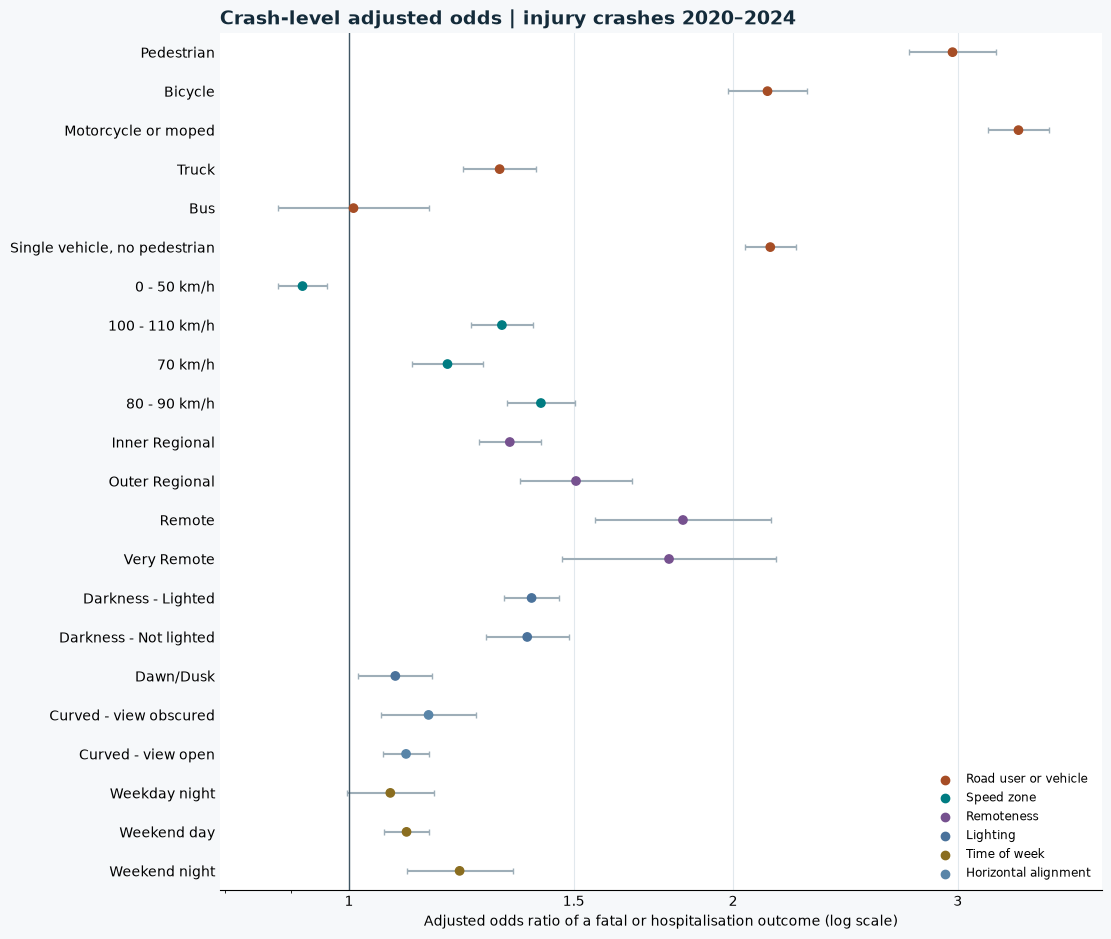

In [37]:
odds_records = window_crashes.copy()
odds_flags = involvement_flags(odds_records).drop(columns='Two or more vehicles')
weekend = odds_records['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday'])
night = odds_records['Crash_Hour'].isin(night_hours)
odds_fields = {
    'Speed zone': odds_records['Crash_Speed_Limit'],
    'Remoteness': odds_records['Loc_ABS_Remoteness'],
    'Lighting': odds_records['Crash_Lighting_Condition'],
    'Road surface': odds_records['Crash_Road_Surface_Condition'],
    'Horizontal alignment': odds_records['Crash_Road_Horiz_Align'],
    'Roadway feature': odds_records['Crash_Roadway_Feature'],
    'Traffic control': odds_records['Crash_Traffic_Control'],
    'Time of week': pd.Series(np.select([weekend & night, ~weekend & night, weekend],
                                        ['Weekend night', 'Weekday night', 'Weekend day'], 'Weekday day'),
                              index=odds_records.index),
    'Police region': odds_records['Loc_Police_Region'],
    'Crash year': odds_records['Crash_Year'].astype(str),
}
ODDS_MINIMUM = 100
design_parts, reference_levels = [odds_flags.astype(float)], {}
for name, values in odds_fields.items():
    values = values.fillna('Unknown').astype(str)
    counts = values.value_counts()
    values = values.where(values.map(counts).ge(ODDS_MINIMUM), f'Other (fewer than {ODDS_MINIMUM})')
    reference_levels[name] = values.value_counts().idxmax()
    # A pooled group that is still small joins the reference level rather than becoming its own term.
    pooled = values.eq(f'Other (fewer than {ODDS_MINIMUM})')
    if 0 < pooled.sum() < ODDS_MINIMUM:
        values = values.mask(pooled, reference_levels[name])
    dummies = pd.get_dummies(values, prefix=name, prefix_sep=': ', dtype=float)
    design_parts.append(dummies.drop(columns=f'{name}: {reference_levels[name]}'))
design = pd.concat(design_parts, axis=1)
design = design.loc[:, design.sum().gt(0)]
odds_outcome = odds_records['Crash_Severity'].isin(severe_labels).to_numpy()

odds_model = LogisticRegression(C=np.inf, solver='newton-cholesky', max_iter=200).fit(design, odds_outcome)
with_intercept = np.column_stack([np.ones(len(design)), design.to_numpy()])
fitted_probability = odds_model.predict_proba(design)[:, 1]
information = with_intercept.T @ (with_intercept * (fitted_probability * (1 - fitted_probability))[:, None])
standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))[1:]
coefficients = odds_model.coef_[0]
adjusted_odds = pd.DataFrame({
    'Term': design.columns, 'Crashes with term': design.sum().astype(int).to_numpy(),
    'Adjusted odds ratio': np.exp(coefficients),
    '95% low': np.exp(coefficients - 1.959964 * standard_errors),
    '95% high': np.exp(coefficients + 1.959964 * standard_errors),
}).set_index('Term')
adjusted_odds['Field'] = [term.split(': ')[0] if ': ' in term else 'Road user or vehicle' for term in adjusted_odds.index]
print(f"{len(design):,} injury crashes, {window_label} · {design.shape[1]} terms · "
      f"references: " + '; '.join(f'{name} = {level}' for name, level in reference_levels.items()))
display(adjusted_odds.loc[adjusted_odds['Field'].ne('Crash year')].round(2))

# Crash-level adjusted estimates beside V5's region-and-year matched estimates from the grouped table.
odds_comparison = pd.DataFrame({
    'Matched region/year (grouped table)': severity_odds.set_index('Flag')['Matched-region/year odds ratio'],
    'Matched 95% low': severity_odds.set_index('Flag')['95% low'],
    'Matched 95% high': severity_odds.set_index('Flag')['95% high'],
}).reindex(['Motorcycle or moped', 'Truck', 'Bus']).join(
    adjusted_odds[['Adjusted odds ratio', '95% low', '95% high']].rename(columns={
        'Adjusted odds ratio': 'Adjusted (crash level)', '95% low': 'Adjusted 95% low', '95% high': 'Adjusted 95% high'}))
display(odds_comparison.round(2))

plot_terms = adjusted_odds.loc[adjusted_odds['Field'].isin(
    ['Road user or vehicle', 'Speed zone', 'Remoteness', 'Lighting', 'Time of week', 'Horizontal alignment'])]
plot_terms = plot_terms.loc[~plot_terms.index.str.contains('Other \\(fewer|Unknown', regex=True)]
field_colors = {'Road user or vehicle': '#a64d25', 'Speed zone': '#007c82', 'Remoteness': '#76518f',
                'Lighting': '#4a729b', 'Time of week': '#8a6d1f', 'Horizontal alignment': '#5985a8'}
fig, ax = plt.subplots(figsize=(11, .34 * len(plot_terms) + 1.8), layout='constrained', facecolor='#f6f8fa')
y = np.arange(len(plot_terms))
ax.errorbar(plot_terms['Adjusted odds ratio'], y,
            xerr=[plot_terms['Adjusted odds ratio'] - plot_terms['95% low'],
                  plot_terms['95% high'] - plot_terms['Adjusted odds ratio']],
            fmt='none', ecolor='#9eaeb8', capsize=2.5)
ax.scatter(plot_terms['Adjusted odds ratio'], y, color=plot_terms['Field'].map(field_colors), s=36, zorder=3)
ax.axvline(1, color='#405664', lw=1)
ax.set(xscale='log', yticks=y, yticklabels=[term.split(': ', 1)[-1] for term in plot_terms.index],
       ylim=(len(plot_terms) - .5, -.5), xlabel='Adjusted odds ratio of a fatal or hospitalisation outcome (log scale)')
ax.set_title(f'Crash-level adjusted odds | injury crashes {window_label}', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
ax.set_xticks([.5, .75, 1, 1.5, 2, 3, 4])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f'{value:g}'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlim(plot_terms['95% low'].min() * .9, plot_terms['95% high'].max() * 1.1)
for field, color in field_colors.items():
    ax.scatter([], [], color=color, label=field)
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(length=0)
plt.show()

**What this achieved.** Holding road setting, time, region and year constant, the adjusted odds of a serious outcome in 2020–2024 were:
- **Road users and vehicles.** Motorcycle involvement 3.35 (95% 3.17–3.54), pedestrian 2.97 (2.75–3.21), single vehicle with no pedestrian 2.14 (2.04–2.24), bicycle 2.13 (1.98–2.29) and truck 1.31 (1.23–1.40). Bus involvement (1.01, 0.88–1.15) shows no association once setting is allowed for, whereas V5's region-and-year matched estimate was 0.84 (0.74–0.96). The crash-level truck estimate is also higher than the matched 1.10 (1.04–1.18). Both suggest the grouped-table estimates were confounded by where buses and trucks crash.
- **Road setting.** Odds rose with speed zone (80–90 km/h 1.41, 100–110 km/h 1.32, against 60 km/h) and remoteness (remote 1.83). Darkness raised them (1.39 lit, 1.38 unlit), as did weekend nights (1.22), cross intersections (1.27) and bridges or causeways (1.30). Roundabouts lowered them (0.70).
- **Region.** Central region kept odds of 1.72 against Brisbane after these adjustments.

These are associations among recorded injury crashes, not causal effects.

## Phase 4 · Evaluation and quality decisions

Evaluate the classifier on its held-out later records. Review the trade-off between fatal-class detection and false positives before choosing a model or threshold.

### Evaluate held-out severity predictions

Score each model on the validation year, the test year and the partial-year records, and compare it with a baseline that predicts the training share for every crash.

- **Ranking.** ROC AUC and average precision. Average precision for a random ranking equals the outcome share, so it is reported beside that share.
- **Probabilities.** The Brier score, compared with the training-share baseline, and a reliability chart on the test year. Probabilities matter here because the screening and any campaign targeting would use them directly.
- **Fatal alerts.** The fatal threshold is fixed on the validation year as the highest-precision threshold that still finds half the fatal crashes, then applied unchanged to the test year. Precision, recall, misses and false alerts are reported for each year.
- **Inputs.** Permutation importance on the test year shows which inputs each gradient-boosting model relies on.

For a like-for-like comparison with V5, which tested on 2023–2025 pooled, the summary also scores fatal average precision on those three years combined.

**In this cell.** Score both outcomes and both model types on each evaluation set. Fix the fatal threshold on the validation year and apply it to the test and partial years. Plot fatal precision–recall curves, reliability curves for the serious outcome, and permutation importance for the gradient-boosting models.

Years  \
Outcome                  Model               Evaluation set                    
Fatal or hospitalisation Logistic regression Validation                 2023   
                                             Test                       2024   
                                             Partial year               2025   
                                             V5 test years pooled  2023–2025   
                         Gradient boosting   Validation                 2023   
                                             Test                       2024   
                                             Partial year               2025   
                                             V5 test years pooled  2023–2025   
Fatal                    Logistic regression Validation                 2023   
                                             Test                       2024   
                                             Partial year               2025   
                                             V5 test years pooled  2023–2025   
                         Gradient boosting   Validation                 2023   
                                             Test                       2024   
                                             Partial year               2025   
                                             V5 test years pooled  2023–2025   

                                                                   Crashes  \
Outcome                  Model               Evaluation set                  
Fatal or hospitalisation Logistic regression Validation              13622   
                                             Test                    14358   
                                             Partial year             7029   
                                             V5 test years pooled    35009   
                         Gradient boosting   Validation              13622   
                                             Test                    14358   
                                             Partial year             7029   
                                             V5 test years pooled    35009   
Fatal                    Logistic regression Validation              13622   
                                             Test                    14358   
                                             Partial year             7029   
                                             V5 test years pooled    35009   
                         Gradient boosting   Validation              13622   
                                             Test                    14358   
                                             Partial year             7029   
                                             V5 test years pooled    35009   

                                                                   Outcome share  \
Outcome                  Model               Evaluation set                        
Fatal or hospitalisation Logistic regression Validation                    0.512   
                                             Test                          0.510   
                                             Partial year                  0.506   
                                             V5 test years pooled          0.510   
                         Gradient boosting   Validation                    0.512   
                                             Test                          0.510   
                                             Partial year                  0.506   
                                             V5 test years pooled          0.510   
Fatal                    Logistic regression Validation                    0.019   
                                             Test                          0.019   
                                             Partial year                  0.018   
                                             V5 test years pooled          0.019   
                         Gradient boosting   Vali

Fatal alert thresholds set on the validation year: Logistic regression 0.056, Gradient boosting 0.044


,Model,Test year,Evaluation set,Coverage,Test crashes,Actual fatal crashes,Fatal predictions,Correct fatal predictions,Missed fatal crashes,False fatal alerts,Fatal precision (%),Fatal recall (%)
0,Logistic regression,2023,Validation,12 months,13622,260,1119,131,129,988,11.7,50.4
1,Logistic regression,2024,Test,12 months,14358,273,1251,124,149,1127,9.9,45.4
2,Logistic regression,2025,Partial year,Partial year,7029,127,591,57,70,534,9.6,44.9
3,Gradient boosting,2023,Validation,12 months,13622,260,1320,132,128,1188,10.0,50.8
4,Gradient boosting,2024,Test,12 months,14358,273,1548,137,136,1411,8.9,50.2
5,Gradient boosting,2025,Partial year,Partial year,7029,127,679,60,67,619,8.8,47.2


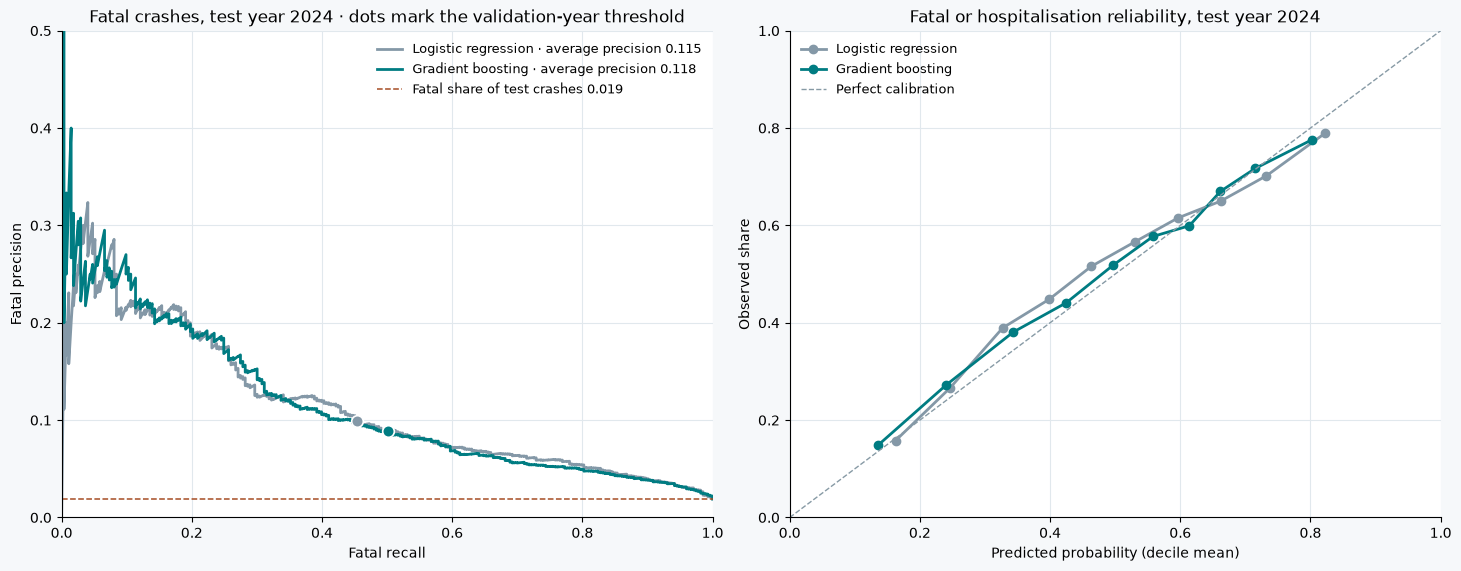

Mean predicted                        Observed share  \
Model  Gradient boosting Logistic regression Gradient boosting   
Decile                                                           
1                  0.136               0.163             0.149   
2                  0.240               0.246             0.272   
3                  0.343               0.327             0.381   
4                  0.425               0.398             0.441   
5                  0.497               0.463             0.518   
6                  0.558               0.531             0.577   
7                  0.614               0.596             0.599   
8                  0.662               0.662             0.670   
9                  0.715               0.732             0.717   
10                 0.802               0.823             0.776   

                            
Model  Logistic regression  
Decile                      
1                    0.158  
2                    0.266  
3                    0.389  
4                    0.448  
5                    0.516  
6                    0.567  
7                    0.615  
8                    0.650  
9                    0.702  
10                   0.790

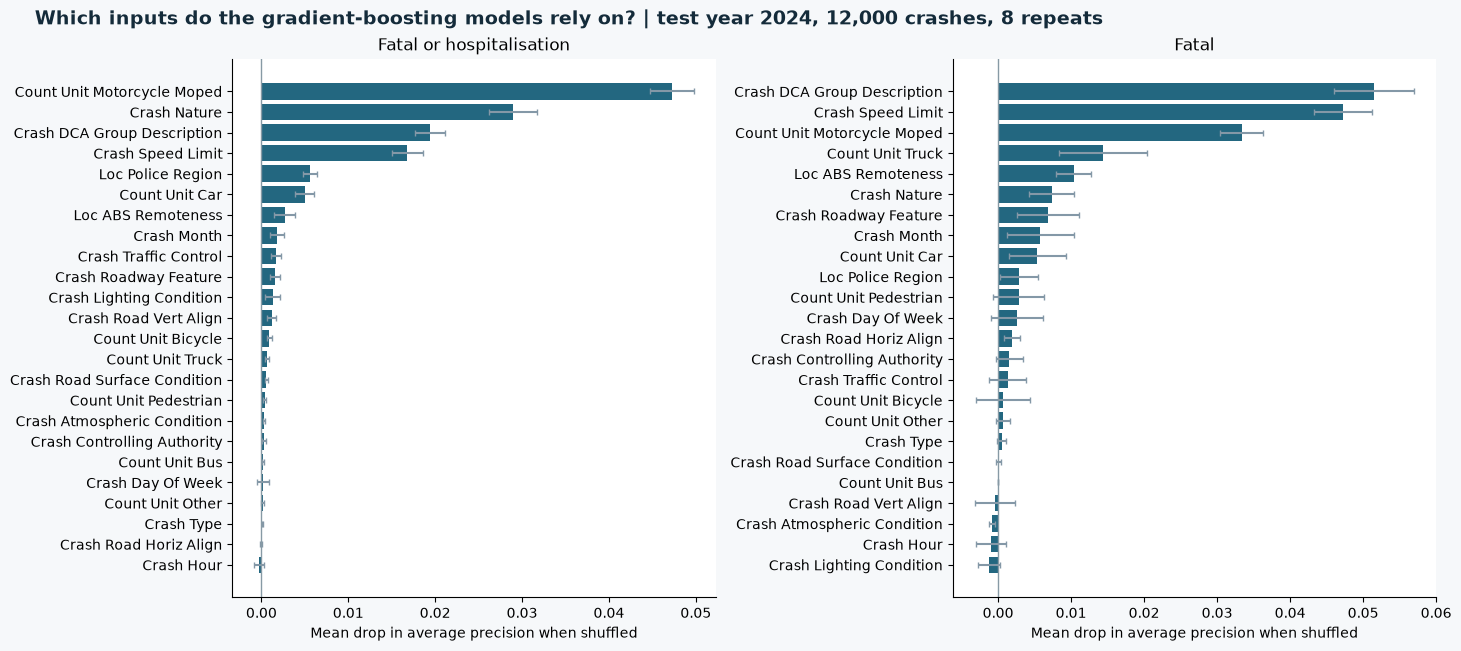

Outcome,Fatal,Fatal or hospitalisation
Input field,,
Crash_DCA_Group_Description,0.0515,0.0194
Crash_Speed_Limit,0.0472,0.0168
Count_Unit_Motorcycle_Moped,0.0333,0.0472
Count_Unit_Truck,0.0144,0.0006
Loc_ABS_Remoteness,0.0104,0.0027
Crash_Nature,0.0074,0.0289
Crash_Roadway_Feature,0.0069,0.0015
Crash_Month,0.0058,0.0018
Count_Unit_Car,0.0054,0.0050


In [38]:
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score

evaluation_sets = {'Validation': ([validation_year], X_valid, y_valid), 'Test': ([test_year], X_test, y_test)}
if len(X_partial):
    evaluation_sets['Partial year'] = (partial_years, X_partial, y_partial)
v5_years = [validation_year, test_year, *partial_years]
model_rows, scores = [], {}
for (outcome, label), model in fitted_models.items():
    levels = outcomes[outcome]
    training_share = float(y_train.isin(levels).mean())
    for set_name, (years, X, y) in [*evaluation_sets.items(),
                                    ('V5 test years pooled', (v5_years, pd.concat([X_valid, X_test, X_partial]),
                                                              pd.concat([y_valid, y_test, y_partial])))]:
        actual = y.isin(levels).to_numpy()
        probability = model.predict_proba(X)[:, 1]
        scores[(outcome, label, set_name)] = (actual, probability)
        model_rows.append({
            'Outcome': outcome, 'Model': label, 'Evaluation set': set_name,
            'Years': '–'.join(str(year) for year in (years[0], years[-1])) if len(years) > 1 else str(years[0]),
            'Crashes': len(actual), 'Outcome share': actual.mean(),
            'ROC AUC': roc_auc_score(actual, probability),
            'Average precision': average_precision_score(actual, probability),
            'Brier score': brier_score_loss(actual, probability),
            'Brier score, training-share baseline': brier_score_loss(actual, np.full(len(actual), training_share)),
            'Mean predicted probability': probability.mean(),
        })
model_summary = pd.DataFrame(model_rows)
model_summary['Brier skill'] = 1 - model_summary['Brier score'] / model_summary['Brier score, training-share baseline']
display(model_summary.set_index(['Outcome', 'Model', 'Evaluation set']).round(3))

# Fatal alert threshold: highest validation precision with at least half of fatal crashes found.
FATAL_RECALL_TARGET = .5
fatal_thresholds, annual_model_rows = {}, []
for label in model_builders:
    actual, probability = scores[('Fatal', label, 'Validation')]
    precision, recall, thresholds = precision_recall_curve(actual, probability)
    eligible = np.flatnonzero(recall[:-1] >= FATAL_RECALL_TARGET)
    fatal_thresholds[label] = float(thresholds[eligible[np.argmax(precision[eligible])]])
    for set_name, (years, X, y) in evaluation_sets.items():
        actual, probability = scores[('Fatal', label, set_name)]
        alert = probability >= fatal_thresholds[label]
        hits = int((actual & alert).sum())
        annual_model_rows.append({
            'Model': label, 'Test year': int(years[0]) if len(years) == 1 else years[0],
            'Evaluation set': set_name,
            'Coverage': '12 months' if set_name != 'Partial year' else 'Partial year',
            'Test crashes': len(actual), 'Actual fatal crashes': int(actual.sum()),
            'Fatal predictions': int(alert.sum()), 'Correct fatal predictions': hits,
            'Missed fatal crashes': int(actual.sum()) - hits, 'False fatal alerts': int(alert.sum()) - hits,
            'Fatal precision (%)': 100 * hits / alert.sum() if alert.any() else np.nan,
            'Fatal recall (%)': 100 * hits / actual.sum() if actual.any() else np.nan,
        })
annual_model_audit = pd.DataFrame(annual_model_rows)
print('Fatal alert thresholds set on the validation year:',
      ', '.join(f'{label} {value:.3f}' for label, value in fatal_thresholds.items()))
display(annual_model_audit.round(1))

model_colors = {'Logistic regression': '#8498a7', 'Gradient boosting': '#007c82'}
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6), layout='constrained', facecolor='#f6f8fa')
pr_rows, reliability_rows = [], []
for label, color in model_colors.items():
    actual, probability = scores[('Fatal', label, 'Test')]
    precision, recall, _ = precision_recall_curve(actual, probability)
    average = average_precision_score(actual, probability)
    axes[0].plot(recall, precision, color=color, lw=2, label=f'{label} · average precision {average:.3f}')
    operating = annual_model_audit.query('Model == @label and `Evaluation set` == "Test"').iloc[0]
    axes[0].scatter(operating['Fatal recall (%)'] / 100, operating['Fatal precision (%)'] / 100, s=70, color=color,
                    edgecolor='white', linewidth=1.2, zorder=4)
    keep_points = np.unique(np.linspace(0, len(recall) - 1, 400).round().astype(int))
    pr_rows.append(pd.DataFrame({'Model': label, 'Fatal recall': recall[keep_points],
                                 'Fatal precision': precision[keep_points]}))
    actual, probability = scores[('Fatal or hospitalisation', label, 'Test')]
    observed_share, predicted_share = calibration_curve(actual, probability, n_bins=10, strategy='quantile')
    axes[1].plot(predicted_share, observed_share, marker='o', color=color, lw=2, label=label)
    reliability_rows.append(pd.DataFrame({'Model': label, 'Mean predicted': predicted_share,
                                          'Observed share': observed_share}))
pr_curves = pd.concat(pr_rows, ignore_index=True)
reliability = pd.concat(reliability_rows, ignore_index=True)
fatal_test_share = scores[('Fatal', 'Gradient boosting', 'Test')][0].mean()
axes[0].axhline(fatal_test_share, color='#a64d25', ls='--', lw=1.1, label=f'Fatal share of test crashes {fatal_test_share:.3f}')
axes[0].set(xlabel='Fatal recall', ylabel='Fatal precision', xlim=(0, 1), ylim=(0, .5),
            title=f'Fatal crashes, test year {test_year} · dots mark the validation-year threshold')
axes[1].plot([0, 1], [0, 1], color='#879aa5', ls='--', lw=1, label='Perfect calibration')
axes[1].set(xlabel='Predicted probability (decile mean)', ylabel='Observed share', xlim=(0, 1), ylim=(0, 1),
            title=f'Fatal or hospitalisation reliability, test year {test_year}')
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
    ax.grid(color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()
display(reliability.assign(Decile=reliability.groupby('Model').cumcount() + 1)
        .pivot(index='Decile', columns='Model', values=['Mean predicted', 'Observed share']).round(3))


def outcome_scorer(levels):
    def score(estimator, features, labels):
        return average_precision_score(np.asarray(labels), estimator.predict_proba(features)[:, 1])
    return score


importance_rows = X_test.sample(n=min(12_000, len(X_test)), random_state=SEED).index
importance_tables = []
for outcome, levels in outcomes.items():
    result = permutation_importance(fitted_models[(outcome, 'Gradient boosting')], X_test.loc[importance_rows],
                                    y_test.loc[importance_rows].isin(levels), scoring=outcome_scorer(levels),
                                    n_repeats=8, random_state=SEED)
    importance_tables.append(pd.DataFrame({'Outcome': outcome,
                                           'Mean drop in average precision': result.importances_mean,
                                           'Standard deviation': result.importances_std}, index=X_test.columns))
importance = pd.concat(importance_tables).rename_axis('Input field')
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.4), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Which inputs do the gradient-boosting models rely on? | test year {test_year}, '
             f'{len(importance_rows):,} crashes, 8 repeats', x=.02, ha='left', fontsize=14, fontweight='bold',
             color='#142b3a')
for ax, outcome in zip(axes, outcomes):
    table = importance.loc[importance['Outcome'].eq(outcome)].sort_values('Mean drop in average precision')
    ax.barh(table.index.str.replace('_', ' '), table['Mean drop in average precision'],
            xerr=table['Standard deviation'], color='#236780', ecolor='#8498a7', capsize=2)
    ax.axvline(0, color='#879aa5', lw=1)
    ax.set(title=outcome, xlabel='Mean drop in average precision when shuffled')
    ax.spines[['top', 'right']].set_visible(False)
plt.show()
display(importance.reset_index().pivot(index='Input field', columns='Outcome', values='Mean drop in average precision')
        .sort_values('Fatal', ascending=False).round(4))

**What this achieved.**

**Fatal outcome.** On V5's test years (2023–2025 pooled), fatal average precision was 0.130 for logistic regression and 0.128 for gradient boosting. V5's best was 0.091, and the fatal share is 0.019. Using the same years makes the comparison fair. Fatal ROC AUC was 0.83–0.86. At the threshold fixed on 2023, the 2024 test year gave:
- **Gradient boosting:** found 137 of 273 fatal crashes (recall 50.2%) with 1,411 false alerts (precision 8.9%).
- **Logistic regression:** found 124 (45.4%) with 1,127 false alerts (9.9%).

V5's best model at similar recall had a precision of 5.0–6.5%. Precision held steady on the partial 2025 records (8.8–9.6%).

**Serious outcome.** Both models reached ROC AUC 0.71–0.72 and cut the Brier score by 14–15% against the training-share baseline. The reliability curves lie close to the diagonal, and mean predictions (0.49–0.50) match the observed share (0.51). Because training stays inside the stable window, the V5 mismatch between training and test class mix is gone.

**Inputs.** The gradient-boosting fatal model relies most on movement group, speed zone, motorcycle count, truck count and remoteness. The new unit counts are among the most useful inputs.

The logistic regression matches gradient boosting on every measure, so the simpler, explainable model is enough. Even so, no threshold gives high fatal precision with useful recall, so the earlier caveat stands: these models describe severity given the crash and are not ready for operational alerts.

### Results at a glance

The following summaries come from the calculations above. For maps or location-sensitive analyses, use `Coordinate_Method` to select observed locations or include the estimates deliberately. For any series that crosses the end of property-damage-only recording, use injury crashes.

**In this cell.** Collect the main findings from recording checks, spatial recovery, model evaluation, association rules, hotspots, and regional comparisons into a single run summary.

In [39]:
# Headline numbers are read from variables computed above, so they cannot drift from the analysis.
print(f"Most common injury crash severity: {injury_severity.idxmax()} ({injury_severity.max():,} crashes).")
print(f"Property-damage-only crashes are recorded to {last_pdo_year} only ({severity['Property damage only']:,} records).")
print(f"Hospitalisation share of injury crashes: {first_year_mix['Hospitalisation']:.1f}% in {mix_complete.index[0]} and "
      f"{latest_year_mix['Hospitalisation']:.1f}% in {mix_complete.index[-1]}; fatal share {mix_complete['Fatal'].min():.1f}–"
      f"{mix_complete['Fatal'].max():.1f}%. Stable severity window: {window_label}.")
print(f"Peak recorded hour for injury crashes: {hourly.sum().idxmax():02}:00.")
print(f"Crash records with both coordinates estimated: {len(targets) - cleaned.loc[targets, COORDS].isna().any(axis=1).sum():,}.")
print(f"Additional coordinate pairs estimated in the second pass: {int(second_pass.sum()):,}.")
print(f"Review-only coordinate candidates: {cleaned['Second_pass_review_latitude'].notna().sum():,}.")
print(f"Coordinate pairs still missing: {int((~available['Coordinate pair']).sum()):,}.")
print(f"Other crash attributes inferred before the public spatial match: {missing_audit.drop(index=COORDS)['Values inferred'].sum():,}.")
both_location_fields = ~recorded['Suburb'] & ~recorded['Council area'] & available['Suburb'] & available['Council area']
print(f"Crashes with both suburb and council area recovered: {both_location_fields.sum():,}.")
suburb_recovered = int(cleaned['Suburb_Only_Name'].notna().sum())
print(f"Suburbs recovered separately for crashes without coordinates: {suburb_recovered:,}.")
print(f"Crashes still missing both a suburb and coordinates: {int((~available['Suburb'] & ~available['Coordinate pair']).sum()):,}.")
print(f"All six files contribute to {regional_summary.notna().all(axis=1).sum():,} "
      f"of {len(regional_summary):,} year-and-police-region groups.")

for label in ['Pedestrian', 'Motorcycle or moped', 'Single vehicle, no pedestrian']:
    involved = unit_involvement.loc[(label, 'Involved')]
    print(f"{label} injury crashes, {window_label}: {int(involved['Injury crashes']):,}, fatal share {involved['Fatal (%)']:.2f}% "
          f"(95% {involved['Fatal 95% low']:.2f}–{involved['Fatal 95% high']:.2f}%).")
print(f"Seasonality: busiest month {mean_index.idxmax()} (index {mean_index.max():.0f}), quietest {mean_index.idxmin()} "
      f"({mean_index.min():.0f}).")
for field, table in area_funnels.items():
    above = table.index[table['z'].gt(FUNNEL_Z['99.8%'])]
    print(f"{field}s above the 99.8% funnel limit: {len(above)} of {len(table)}"
          + (f" ({', '.join(above[:5])}{'…' if len(above) > 5 else ''})." if len(above) else '.'))
top_dca = dca_table.index[0]
print(f"Movement code with the most fatal crashes, {window_label}: {top_dca} "
      f"({dca_table.at[top_dca, 'Fatal crashes']:,}, {dca_table.at[top_dca, 'Share of all fatal crashes (%)']:.1f}% of fatal).")

vehicle_fatal = vehicle_severity['Fatal share (%)'].unstack()
for kind in ['Truck', 'Motorcycle or moped']:
    involved, absent = vehicle_fatal.loc[kind, ['Involved', 'Absent']]
    print(f"{kind} fatal share among injury crashes: {involved:.1f}% with the flag and {absent:.1f}% without.")
for flag in ['Pedestrian', 'Motorcycle or moped', 'Truck', 'Bicycle']:
    row = adjusted_odds.loc[flag]
    print(f"Adjusted odds of a serious outcome, {flag.lower()} involved: {row['Adjusted odds ratio']:.2f} "
          f"({row['95% low']:.2f}–{row['95% high']:.2f}).")

volume_region = regional_profile['Injury crashes'].idxmax()
severity_region = regional_profile['Serious crash (%)'].idxmax()
print(f"Highest recorded injury crash volume: {volume_region} "
      f"({regional_profile.at[volume_region, 'Injury crashes']:,}).")
print(f"Highest fatal or hospitalisation share: {severity_region} "
      f"({regional_profile.at[severity_region, 'Serious crash (%)']:.1f}%).")
mix_region = region_mix['Recorded ÷ expected'].idxmax()
print(f"After allowing for remoteness and speed zone, recorded ÷ expected serious crashes ranges from "
      f"{region_mix['Recorded ÷ expected'].min():.2f} to {region_mix['Recorded ÷ expected'].max():.2f} ({mix_region}).")
print(f"Vehicle occupants, {rate_period}: {occupant_rate['Unrestrained']:.1f} fatalities per 100 unrestrained casualties "
      f"and {occupant_rate['Restrained']:.1f} per 100 restrained.")

top_site = hotspots.iloc[0]
print(f"Road sites screened, {screen_period}: {len(ranked_sites):,} with {SITE_MINIMUM}+ injury crashes. "
      f"Top site: {top_site['Road names']}, {top_site['Suburb']} ({top_site['Serious crashes']} serious against "
      f"{top_site['Expected serious']:.1f} expected).")
shrunk_row = persistence.loc['Shrunk excess (empirical Bayes)']
count_row = persistence.loc['Serious-crash count (V5 criterion)']
print(f"Top {TOP_SITES} sites in {earlier_label} by serious count kept {count_row['Later excess ÷ earlier raw excess']:.2f} "
      f"of their excess in {later_label}; by shrunk excess, {shrunk_row['Later excess ÷ earlier raw excess']:.2f} "
      f"({shrunk_row['Later excess ÷ earlier shrunk excess']:.2f} of the shrunk estimate).")
if not rule_table.empty:
    strongest = rule_table.iloc[0]
    print(f"Top displayed severity rule, {window_label}: {strongest['antecedents']} → {strongest['consequents']} "
          f"(lift {strongest['lift']:.2f}).")
for outcome in outcomes:
    best = model_summary.query('Outcome == @outcome and `Evaluation set` == "Test"').set_index('Model')
    print(f"{outcome}, test year {test_year}: " + '; '.join(
        f"{model} ROC AUC {row['ROC AUC']:.3f}, average precision {row['Average precision']:.3f} "
        f"(share {row['Outcome share']:.3f}), Brier skill {row['Brier skill']:.3f}" for model, row in best.iterrows()) + '.')
pooled = model_summary.query('Outcome == "Fatal" and `Evaluation set` == "V5 test years pooled"').set_index('Model')
print(f"Fatal average precision on V5's test years ({pooled['Years'].iloc[0]}): "
      + ', '.join(f"{model} {row['Average precision']:.3f}" for model, row in pooled.iterrows()) + ' (V5 best: 0.091).')

Most common injury crash severity: Hospitalisation (133,287 crashes).
Property-damage-only crashes are recorded to 2010 only (87,432 records).
Hospitalisation share of injury crashes: 30.5% in 2001 and 49.1% in 2024; fatal share 1.5–2.3%. Stable severity window: 2020–2024.
Peak recorded hour for injury crashes: 15:00.
Crash records with both coordinates estimated: 127.
Additional coordinate pairs estimated in the second pass: 1.
Review-only coordinate candidates: 5.
Coordinate pairs still missing: 471.
Other crash attributes inferred before the public spatial match: 2.
Crashes with both suburb and council area recovered: 127.
Suburbs recovered separately for crashes without coordinates: 28.
Crashes still missing both a suburb and coordinates: 443.
All six files contribute to 184 of 186 year-and-police-region groups.
Pedestrian injury crashes, 2020–2024: 3,307, fatal share 4.08% (95% 3.46–4.81%).
Motorcycle or moped injury crashes, 2020–2024: 8,022, fatal share 4.38% (95% 3.95–4.85%).
S

**What this achieved.** Brought the saved data quality, descriptive and model findings together. The results support exploration and follow-up validation before any operational model decision.

## Phase 5 · Deployment readiness

The notebook and CSVs provide a local analytical release. An operational model release would need a versioned bundle with its fitted preprocessing, training configuration, dependency lock, input schema, and evaluation report. Choose the delivery mode once the intended user and decision are agreed. For a batch release, verify input/output contracts, reproduce predictions after reloading the bundle, and rehearse rollback to the previous approved version.

### Export the analysis data for Tableau and the Esri map page

These files are the Tableau inputs, so every number can be traced to this run. They go to `Tableau data V6/`. `build_tableau_workbook.py` still packages the V5 tables into `Queensland Traffic V5.twbx`. The model and hotspot sheets need updating for the V6 layouts before it can build a V6 workbook.

- `crashes.csv` has one row per crash with readable field names. Three indicator fields make rates simple to calculate. `Injury crash` is 1 for an injury crash and 0 for a property-damage-only record. `Serious outcome` and `Fatal outcome` are 1 or 0 for injury crashes and blank for property-damage-only records, so their average is the share among injury crashes whatever filter is applied.
- `casualties.csv`, `restraints.csv`, `crash_factors.csv`, `vehicle_types.csv` and `driver_demographics.csv` hold the five grouped source tables with aligned year and police-region names and count fields ready to sum.
- The remaining files hold results that depend on a fixed period or method, such as the road-mix comparison, the matched odds ratios, the hotspots and the model evaluation. Each carries its period in the data.

The same cell rebuilds the Esri map page from the maps created in this run.

**In this cell.** Assemble the crash-level table and the grouped tables with readable names and ordered category labels. Collect the fixed-period results, write every table to `Tableau data V6/` through temporary files, and check row counts and totals against the source. Render the Folium maps into the tabbed Esri HTML page.

In [40]:
TABLEAU_DIR = DATA_DIR / 'Tableau data V6'
TABLEAU_DIR.mkdir(exist_ok=True)


def ordered_labels(values, order):
    """Prefix categories with their position so they sort in a meaningful order."""
    labels = {name: f'{position} · {name}' for position, name in enumerate(order, start=1)}
    return values.map(labels).fillna(values)


month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September',
               'October', 'November', 'December']
is_injury = cleaned['Crash_Severity'].ne('Property damage only')
# Crash-level table with readable names. Ordered labels sort correctly in Tableau without manual sorting.
tableau_crashes = pd.DataFrame({
    'Crash ref': cleaned[CRASH_ID],
    'Crash year': cleaned['Crash_Year'],
    'Complete year': np.where(cleaned['Crash_Year'].isin(complete_years), 'Complete year', 'Partial year'),
    'Stable severity window': np.where(cleaned['Crash_Year'].isin(stable_years), 'Yes', 'No'),
    'Recording period': np.where(cleaned['Crash_Year'].le(last_pdo_year),
                                 f'To {last_pdo_year} (property damage recorded)',
                                 f'From {last_pdo_year + 1} (injury crashes only)'),
    'Month': cleaned['Crash_Month'].map({name: f'{number:02} · {name[:3]}' for number, name in enumerate(month_order, 1)}),
    'Day of week': ordered_labels(cleaned['Crash_Day_Of_Week'], day_order),
    'Weekend': np.where(cleaned['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday']), 'Weekend', 'Weekday'),
    'Hour': cleaned['Crash_Hour'],
    'Time band': np.where(cleaned['Crash_Hour'].isin(night_hours), 'Night (22:00–04:59)', 'Day and evening (05:00–21:59)'),
    'Severity': cleaned['Crash_Severity'],
    'Record type': np.where(is_injury, 'Injury crash', 'Property damage only'),
    'Crashes': 1,
    'Injury crash': is_injury.astype(int),
    'Serious outcome': cleaned['Crash_Severity'].isin(severe_labels).astype('Int64').where(is_injury),
    'Fatal outcome': cleaned['Crash_Severity'].eq('Fatal').astype('Int64').where(is_injury),
    'Crash nature': cleaned['Crash_Nature'],
    'Crash type': cleaned['Crash_Type'],
    'Movement group': cleaned['Crash_DCA_Group_Description'],
    'Police region': cleaned['Loc_Police_Region'],
    'Police district': cleaned['Loc_Police_District'],
    'Local government area': cleaned['Loc_Local_Government_Area'],
    'Suburb': cleaned['Loc_Suburb'],
    'Postcode': cleaned['Loc_Post_Code'],
    'Statistical area 2': cleaned['Loc_ABS_Statistical_Area_2'],
    'Statistical area 4': cleaned['Loc_ABS_Statistical_Area_4'],
    'Remoteness area': ordered_labels(cleaned['Loc_ABS_Remoteness'], remoteness_order),
    'State electorate': cleaned['Loc_State_Electorate'],
    'Street': cleaned['Crash_Street'],
    'Intersecting street': cleaned['Crash_Street_Intersecting'],
    'Controlling authority': cleaned['Crash_Controlling_Authority'],
    'Roadway feature': cleaned['Crash_Roadway_Feature'],
    'Traffic control': cleaned['Crash_Traffic_Control'],
    'Speed zone': ordered_labels(cleaned['Crash_Speed_Limit'], speed_order),
    'Road surface': cleaned['Crash_Road_Surface_Condition'],
    'Weather': cleaned['Crash_Atmospheric_Condition'],
    'Lighting': cleaned['Crash_Lighting_Condition'],
    'Horizontal alignment': cleaned['Crash_Road_Horiz_Align'],
    'Vertical alignment': cleaned['Crash_Road_Vert_Align'],
    'Fatalities': cleaned['Count_Casualty_Fatality'],
    'Hospitalised': cleaned['Count_Casualty_Hospitalised'],
    'Medically treated': cleaned['Count_Casualty_MedicallyTreated'],
    'Minor injuries': cleaned['Count_Casualty_MinorInjury'],
    'Casualties': cleaned['Count_Casualty_Total'],
    'Cars': cleaned['Count_Unit_Car'],
    'Motorcycles': cleaned['Count_Unit_Motorcycle_Moped'],
    'Trucks': cleaned['Count_Unit_Truck'],
    'Buses': cleaned['Count_Unit_Bus'],
    'Bicycles': cleaned['Count_Unit_Bicycle'],
    'Pedestrians': cleaned['Count_Unit_Pedestrian'],
    'Road site': screen_points['Site'].reindex(cleaned.index),
    'Road site type': screen_points['Site type'].reindex(cleaned.index),
    'Coordinate method': cleaned['Coordinate_Method'],
    'Latitude': cleaned['Crash_Latitude'].round(6),
    'Longitude': cleaned['Crash_Longitude'].round(6),
    'Grid latitude': cleaned['Crash_Latitude'].round(2),
    'Grid longitude': cleaned['Crash_Longitude'].round(2),
})
assert len(tableau_crashes) == len(raw) and tableau_crashes['Crash ref'].is_unique
assert tableau_crashes['Injury crash'].sum() == len(injury_only)
assert tableau_crashes['Serious outcome'].sum() == injury_serious.sum()
assert tableau_crashes['Fatal outcome'].sum() == severity['Fatal']
assert tableau_crashes['Fatalities'].sum() == raw['Count_Casualty_Fatality'].sum()

casualty_severity_flags = {'Fatalities': ['Fatality'], 'Fatal or hospitalised': ['Fatality', 'Hospitalised']}


# Grouped casualty tables with count columns that can be summed directly.
def tableau_casualties(frame, renames):
    table = frame.rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region',
                                  'Casualty_Severity': 'Casualty severity', 'Casualty_AgeGroup': 'Age group',
                                  'Casualty_Gender': 'Gender', 'Casualty_Count': 'Casualties', **renames})
    for name, levels in casualty_severity_flags.items():
        table[name] = table['Casualties'].where(table['Casualty severity'].isin(levels), 0)
    return table.drop(columns='_id')


# Grouped flag tables with crash counts split into injury, serious and fatal.
def tableau_flags(frame):
    table = frame.rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region',
                                  'Crash_Severity': 'Severity', 'Count_Crashes': 'Crashes'})
    table = table.rename(columns={column: column.removeprefix('Involving_').replace('_', ' ').replace(' 16-24', ' 16–24')
                                  .replace(' 60plus', ' 60 plus') for column in table if column.startswith('Involving_')})
    injury = table['Severity'].ne('Property damage only')
    table['Injury crashes'] = table['Crashes'].where(injury, 0)
    table['Serious crashes'] = table['Crashes'].where(table['Severity'].isin(severe_labels), 0)
    table['Fatal crashes'] = table['Crashes'].where(table['Severity'].eq('Fatal'), 0)
    return table[[column for column in table if not column.startswith(('Count_', '_id'))]]


model_year_table = annual_model_audit.assign(**{'Test period': lambda frame: frame['Test year'].astype(str)
                                                + np.where(frame['Coverage'].eq('Partial year'), ' (partial)', '')})
# Fatal alerts on the test year at the validation-year threshold, as a two-by-two table per model.
confusion_rows = []
for label in model_builders:
    actual, probability = scores[('Fatal', label, 'Test')]
    predicted_fatal = probability >= fatal_thresholds[label]
    for actual_label, actual_mask in [('Fatal', actual), ('Not fatal', ~actual)]:
        for predicted_label, predicted_mask in [('Fatal', predicted_fatal), ('Not fatal', ~predicted_fatal)]:
            crashes = int((actual_mask & predicted_mask).sum())
            confusion_rows.append({'Model': label, 'Actual severity': actual_label,
                                   'Predicted severity': predicted_label, 'Share of actual': crashes / actual_mask.sum(),
                                   'Crashes': crashes})
standardised_long = (standardised.rename_axis(index=light_field, columns=surface_field).stack().rename('Fatal or hospitalisation share (%)').reset_index()
                     .rename(columns={light_field: 'Lighting', surface_field: 'Road surface'}))
residual_table = regional_rates.assign(**{
    'Speed deviation (pp)': residual_rates[:, 0], 'Serious share deviation (pp)': residual_rates[:, 1],
}).rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region', 'Speed': 'Speed involvement (%)',
                   'Serious crash': 'Serious share (%)'})

# File name (without .csv) mapped to the table written to the Tableau data folder.
tableau_tables = {
    'crashes': tableau_crashes,
    'casualties': tableau_casualties(casualty_source, {'Casualty_RoadUserType': 'Road user'}),
    'restraints': tableau_casualties(equipment_source, {road_user_column: 'Road user',
                                                        'Casualty_Restraint_Helmet_Use': 'Restraint or helmet use'}),
    'crash_factors': tableau_flags(regional_sources['Factors']),
    'vehicle_types': tableau_flags(regional_sources['Vehicles']),
    'driver_demographics': tableau_flags(regional_sources['Demographics']).drop(columns='Overseas Licensed Driver'),
    'result_region_road_mix': region_mix.reset_index().rename(columns={'Police_Region': 'Police region'})
        .assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_matched_odds': severity_odds.assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_equipment_fatality_rates': equipment_rates.reset_index().rename(
        columns={road_user_column: 'Road user', 'Casualty_Restraint_Helmet_Use': 'Restraint or helmet use'}
    ).assign(Period=rate_period),
    'result_speed_severity_region_year': residual_table,
    'result_wet_dry_standardised': standardised_long.assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_hotspots': hotspots.reset_index().assign(Period=screen_period),
    'result_site_screening': sites.reset_index().rename(columns={'Site': 'Site ID'}).assign(Period=screen_period),
    'result_site_persistence': persistence.reset_index().assign(
        **{'Earlier period': earlier_label, 'Later period': later_label}),
    'result_severity_mix_by_year': severity_mix.reset_index().assign(
        **{'Stable window': lambda frame: np.where(frame['Crash_Year'].isin(stable_years), 'Yes', 'No')}),
    'result_unit_involvement': unit_involvement.reset_index().assign(Period=window_label),
    'result_month_seasonality': seasonal_index.rename_axis(index='Crash year', columns='Month').stack()
        .rename('Seasonal index').reset_index(),
    'result_month_severity': window_month.rename_axis('Month').reset_index().assign(Period=window_label),
    'result_area_funnel': area_funnel_table.reset_index().assign(Period=window_label),
    'result_dca_codes': dca_table.rename_axis('Movement (DCA description)').reset_index().assign(Period=window_label),
    'result_adjusted_odds': adjusted_odds.reset_index().assign(Period=window_label),
    'result_association_rules': severity_rules[['antecedents', 'support', 'confidence', 'lift']].assign(
        antecedents=lambda frame: frame['antecedents'].map(lambda items: ' + '.join(sorted(items))),
        **{'Serious crashes': lambda frame: (frame['support'] * len(transactions)).round().astype(int)}
    ).rename(columns={'antecedents': 'Conditions', 'support': 'Support', 'confidence': 'Serious share',
                      'lift': 'Lift'}),
    'result_model_summary': model_summary,
    'result_model_by_year': model_year_table,
    'result_model_confusion': pd.DataFrame(confusion_rows),
    'result_model_precision_recall': pr_curves,
    'result_model_permutation_importance': importance.reset_index()
        .assign(**{'Input field': lambda frame: frame['Input field'].str.replace('_', ' ')}),
}
for name, table in tableau_tables.items():
    assert len(table) and table.columns.is_unique, name
    write_csv(table, TABLEAU_DIR / f'{name}.csv')
for name, source_name, field in [('casualties', 'Casualties', 'Casualty_Count'),
                                 ('restraints', 'Restraints', 'Casualty_Count')]:
    assert tableau_tables[name]['Casualties'].sum() == regional_sources[source_name][field].sum()
for name, source_name in [('crash_factors', 'Factors'), ('vehicle_types', 'Vehicles'),
                          ('driver_demographics', 'Demographics')]:
    assert tableau_tables[name]['Crashes'].sum() == len(raw)
    assert tableau_tables[name]['Injury crashes'].sum() == len(injury_only)
tableau_exports = [TABLEAU_DIR / f'{name}.csv' for name in tableau_tables]
assert all(path.is_file() for path in tableau_exports)
print(f"Wrote {len(tableau_exports)} tables to {TABLEAU_DIR.name}/ | crashes.csv has "
      f"{len(tableau_crashes):,} rows and {tableau_crashes.shape[1]} fields.")

# Rebuild the tabbed Esri map page from the maps created in this run.
esri_views = [
    ('Crash locations and density', crash_map), ('Female occupant restraints', belt_bubble_map),
    ('Fatalities recorded in rain', rain_region_map), ('Road sites with excess serious crashes', hotspot_map),
]
buttons = ''.join(
    f'<button type="button" aria-controls="map-{number}" aria-pressed="{str(number == 0).lower()}">{escape(title)}</button>'
    for number, (title, _) in enumerate(esri_views)
)
frames = ''.join(
    f'<iframe id="map-{number}" title="{escape(title)}"{"" if number == 0 else " hidden"} '
    f'srcdoc="{escape(view.get_root().render(), quote=True)}"></iframe>\n'
    for number, (title, view) in enumerate(esri_views)
)
esri_page = f"""<!doctype html>
<html lang="en-AU"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Queensland traffic crashes | V6 Esri maps</title>
<style>
* {{ box-sizing:border-box }}
body {{ margin:0; height:100dvh; display:flex; flex-direction:column; font:15px system-ui,sans-serif; color:#173347; background:#f4f8fb }}
header {{ padding:14px 20px }}
h1 {{ font-size:22px; margin:0 0 8px }}
p {{ margin:0 0 10px }}
nav {{ display:flex; gap:8px; flex-wrap:wrap }}
button {{ font:inherit; border-radius:5px; padding:6px 12px; border:1px solid #7995a6; color:#16364a; background:white; cursor:pointer }}
button[aria-pressed=true] {{ background:#173347; color:white }}
iframe {{ width:100%; flex:1; min-height:0; border:0; border-top:1px solid #bacbd6 }}
</style>
<header><h1>Queensland traffic crashes · V6 Esri maps</h1>
<p>Choose a map. The Esri imagery and map libraries require an internet connection.</p>
<nav aria-label="Map views">{buttons}</nav></header>
{frames}<script>
for (const tab of document.querySelectorAll('button')) {{
  tab.addEventListener('click', () => {{
    for (const item of document.querySelectorAll('button')) {{
      item.setAttribute('aria-pressed', String(item === tab));
      const map = document.getElementById(item.getAttribute('aria-controls'));
      map.hidden = item !== tab;
      if (item === tab) map.contentWindow.dispatchEvent(new Event('resize'));
    }}
  }});
}}
</script></html>
"""
esri_destination = DATA_DIR / 'Queensland Traffic V6 - Esri Maps.html'
with NamedTemporaryFile(mode='w', encoding='utf-8', dir=DATA_DIR, prefix='.traffic-v6-', suffix='.html',
                        delete=False) as stream:
    stream.write(esri_page)
Path(stream.name).replace(esri_destination)
print(f"Rebuilt {esri_destination.name} with {len(esri_views)} map views.")

Wrote 27 tables to Tableau data V6/ | crashes.csv has 415,407 rows and 57 fields.
Rebuilt Queensland Traffic V6 - Esri Maps.html with 4 map views.


**What this achieved.** Wrote 27 tables to `Tableau data V6/`. The 415,407-row crash table now has 57 fields, adding the stable-window flag and each screened crash's road site. The new result tables hold the severity mix, unit involvement, seasonality, area funnels, DCA codes, adjusted odds, site screening and persistence, with model tables in the V5 layout. Rebuilt the Esri map page as `Queensland Traffic V6 - Esri Maps.html`, with the road-site map in place of the DBSCAN hotspots. `build_tableau_workbook.py` has not been updated for these tables.

### Record the analytical release

**In this cell.** Compute SHA-256 checksums for the original files, local spatial layers and three CSV exports. Record the Python and package versions, random seed and analysis windows so later runs can be compared.

In [41]:
import hashlib
import json
import platform
from importlib.metadata import version

# Size and SHA-256 checksum identify the exact file used or produced.
def fingerprint(path):
    with path.open('rb') as stream:
        digest = hashlib.file_digest(stream, 'sha256').hexdigest()
    return {'file': path.name, 'bytes': path.stat().st_size, 'sha256': digest}

export_files = [EXPORT, DATA_DIR / 'Traffic location and suburb reconciliation V6.csv', context_export]
analysis_exports = [*tableau_exports, esri_destination]
packages = ['numpy', 'pandas', 'scipy', 'matplotlib', 'folium', 'scikit-learn',
            'mlxtend', 'shapely', 'pyproj', 'pyshp', 'ijson', 'pyarrow']
code_files = [DATA_DIR / name for name in ['traffic_spatial_lookup.py', 'traffic_location_recovery.py',
                                           'traffic_road_sites.py']]
# Everything needed to compare this run with a later one.
manifest = {
    'notebook': 'Traffic_Incidents_V6.ipynb', 'seed': SEED,
    'python': platform.python_version(), 'packages': {name: version(name) for name in packages},
    'inputs': [{**fingerprint(path), 'file': str(path.relative_to(DATA_DIR))} for path in required],
    'code': [fingerprint(path) for path in code_files],
    'exports': [fingerprint(path) for path in export_files],
    'analysis_exports': [{**fingerprint(path), 'file': str(path.relative_to(DATA_DIR))}
                         for path in analysis_exports],
    'recording_breaks': {'last_property_damage_only_year': last_pdo_year,
                         'overseas_licensed_flag_last_year': overseas_last_year},
    'stable_severity_window': {'years': [int(year) for year in stable_years],
                               'tolerance_percentage_points': SEVERITY_TOLERANCE_PP},
    'comparison_years': recent_years.astype(int).tolist(),
    'models': {'training_years': train_years, 'validation_year': validation_year, 'test_year': test_year,
               'partial_years': partial_years, 'fatal_thresholds': fatal_thresholds},
    'site_screening': {'years': [int(year) for year in screen_years], 'overdispersion_rho': site_rho,
                       'shrinkage_k': site_k, 'junction_snap_m': JUNCTION_SNAP_M, 'link_snap_m': LINK_SNAP_M},
}
destination = DATA_DIR / 'Traffic release manifest V6.json'
with NamedTemporaryFile(mode='w', encoding='utf-8', dir=DATA_DIR, delete=False) as stream:
    json.dump(manifest, stream, indent=2)
Path(stream.name).replace(destination)
print(f"Recorded {len(required)} inputs, {len(export_files)} CSV exports and "
      f"{len(analysis_exports)} analysis exports in {destination.name}.")

Recorded 11 inputs, 3 CSV exports and 28 analysis exports in Traffic release manifest V6.json.


**What this achieved.** The V6 release manifest identifies the inputs, the three helper modules, the exported CSVs, the package versions, the stable severity window, the model years and thresholds, and the site-screening constants. `imbalanced-learn` is no longer used.

## Phase 6 · Monitoring and maintenance

For periodic data refreshes, track source coverage, reporting lag, missing fields, unknown categories, cross-file count differences, and spatial match rates. If the classifier is used operationally, monitor input and prediction drift, fatal precision and recall once actual labels arrive, and performance by region and reporting period. Assign owners and thresholds, document the response to a failed check, and require validation and approval before replacing a model. Re-run the recording-change check on every refresh, because a new break in a series would invalidate trend comparisons. Re-run the severity-mix check too. If a new year falls outside the 3-point tolerance, the stable window moves, and the models, rules and serious-share comparisons must be refitted on the new window. Refresh the road-site screening each year, and record whether treated sites fall back by more than the period-to-period fall shown in Phase 3.

### Missing process elements

| Stage | What to complete | Evidence to record |
|---|---|---|
| **Before further model selection** | Agree who uses the result, what action it informs, when the prediction is made and which inputs are available then. Agree acceptable fatal-class precision and recall and the cost of missed cases and false alerts. | A signed-off use case, feature availability list and measurable acceptance criteria. |
| **Before repeatable releases** | Archive the input versions identified in the release manifest. Add publisher release dates, reporting cutoffs and a dependency lockfile. Turn the existing ID, tally, coordinate, recording-change and severity-mix checks into automated pipeline checks. Update `build_tableau_workbook.py` for the V6 tables. | A run manifest and a repeatable validation report with explicit pass conditions. |
| **Before operational model use** | *Done in V6:* threshold chosen on a validation year, calibration measured, partial year scored separately. *Still to do:* rolling time splits as more stable-window years arrive, performance by region and condition, and uncertainty intervals for precision and recall. Confirm with the data custodian why the hospitalisation share rose, so the stable window can be justified or extended. | A model evaluation report and a decision against the agreed thresholds. |
| **Before applying exploratory findings** | *Done in V6:* count hotspots replaced by excess-based site screening with a two-period check. *Still to do:* add site crash frequency (and traffic volumes when available) to the screening strata, which corrects the calibration offset found in Phase 3, plus a road-user-adjusted variant that separates motorcycle-route sites from road-design sites, a redundancy filter and later-period check for the association rules, population denominators (ABS estimates by SA2 or LGA) for per-person rates, and a check of recorded against polygon police regions and suburbs. | Stability and coverage tables with review decisions. |
| **If a model moves into use** | Package and register the approved pipeline, test it on representative inputs, establish a release and rollback procedure, then assign monitoring and retraining ownership. Add automated integration, delivery or training where the release cadence warrants it. | A versioned model bundle, release checklist, monitoring plan and documented triggers for investigation and revalidation. |

The next decision is whether V6 will remain a research and reporting notebook or support a defined operational prediction. That decision determines which production steps are needed.

## Practical use cases for the Queensland crash analysis

The examples below use recorded crashes or casualties. Severity shares and comparisons cover the stable severity window, 2020–2024, unless stated otherwise. Traffic volumes or distance travelled would be needed to compare risk per trip or kilometre.

### Common use cases

- **Plan patrol and incident-response coverage.** Use the day-and-hour severity heatmap and the Esri layers to shortlist areas and times for a coverage review. The most injury crashes were recorded at 15:00, while the fatal-or-hospitalisation share was highest late at night (64.6% on weekend nights compared with 47.1% on weekday days and evenings). Volume dips in January and December and is otherwise flat across the year, so seasonal staffing should follow volume rather than severity. Check that the pattern holds by police region before changing shifts.
- **Prioritise road safety inspections.** Use the road-site screening list (`result_hotspots.csv` and the site map) rather than crash counts. Sites ranked by serious-crash count kept none of their excess in the next five years. Sites ranked by excess kept 45–50 serious crashes above expected. The top links include Beechmont Road (Advancetown), Mt Mee Road and Beaudesert–Nerang Road. Many of these are recreational motorcycle routes, where rider-focused treatments (surface, barriers, curve delineation, enforcement and rider campaigns) may matter as much as general road design. Top junctions include Mulgrave Road / Florence Street in Cairns. Busy sites score slightly low and quiet sites slightly high against their expected share, so review road design, traffic volumes and site history before choosing treatments.
- **Target and evaluate restraint campaigns.** Use the road-user and equipment Sankey to choose which seatbelt or helmet messages warrant review. For 2015–2024, unrestrained occupants had 9.15 fatalities per 100 casualties compared with 0.85 for restrained occupants. Track the known-status share and the amount of missing status together when comparing periods.

### Less obvious use cases

- **Target run-off-road and head-on treatments by movement code.** Head-on crashes were 3.6% of injury crashes but 19% of fatal crashes, and three run-off-road movements on curves and straights account for another 24%. Join the DCA codes to the road-site list to find links where these movements dominate, then check them for barriers, wide centre lines and curve delineation.
- **Ask why some councils record more serious crashes than their road mix predicts.** Moreton Bay, Ipswich, Mackay, Gladstone and Burdekin sit above the 99.8% funnel limit, and Brisbane and Toowoomba sit below it. Check local injury-grading and reporting practice before reading these as differences in road safety. This is the same question the statewide hospitalisation drift raises.
- **Reconsider the vehicle messages.** At crash level, after allowing for road setting, bus involvement shows no association with a serious outcome (odds ratio 1.01), and the truck association (1.31) is stronger than the grouped tables suggested. Pedestrian (2.97) and cyclist (2.13) crashes carry odds of a serious outcome comparable to single-vehicle crashes (2.14).
- **Use location recovery to triage data-quality work.** Of the 598 crashes originally missing coordinates, 127 gained estimated coordinate pairs and another 28 gained a suburb only. Use the 443 records still missing both fields to prioritise searches for original location evidence.